In [2]:
!pip install -U tbparse

In [3]:
import numpy as np
from tbparse import SummaryReader
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [ ]:
var = "pearo_z_500hpa"

## RMSE

In [268]:
var = ["aro_t_850hpa", "aro_t2m_2m", "aro_u10_10m", "aro_v10_10m", "aro_tp_0m", "aro_z_500hpa"]
var_name = [r'$Temp_{850hPa}$', r'$Temp_{2m}$', r'$U_{10m}$', r'$V_{10m}$', r'$Total Precip$', r'$Z_{500hPa}$']
linestyle = ['-.', '--', '-', ':', (0, (3, 1, 1, 1, 1, 1))]

In [288]:
# Read and parse the JSON file

k=0

with open("/data/titan_21var/base_0order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_0_order = data[var[k]]

with open("/data/titan_21var/base_2order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_2_order = data[var[k]]

with open("/data/titan_21var/base_1order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_1_order = data[var[k]]

with open("/data/titan_21var/base_2order_5em4_bckwrd/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_2_order_bckwrd = data[var[k]]


In [223]:
# concatenate all data for normalization
all_data = np.concatenate([df_base_0_order, df_base_1_order, df_base_2_order, df_base_2_order_bckwrd])
min_val = np.min(all_data)
max_val = np.max(all_data)
std = np.std(all_data)

In [224]:
# Read and parse the JSON file

with open("/data/titan_21var/base_0order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_0_order = data[var[k]]/std

with open("/data/titan_21var/base_2order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_2_order = data[var[k]]/std

with open("/data/titan_21var/base_1order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_1_order = data[var[k]]/std

with open("/data/titan_21var/base_2order_5em4_bckwrd/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_2_order_bckwrd = data[var[k]]/std

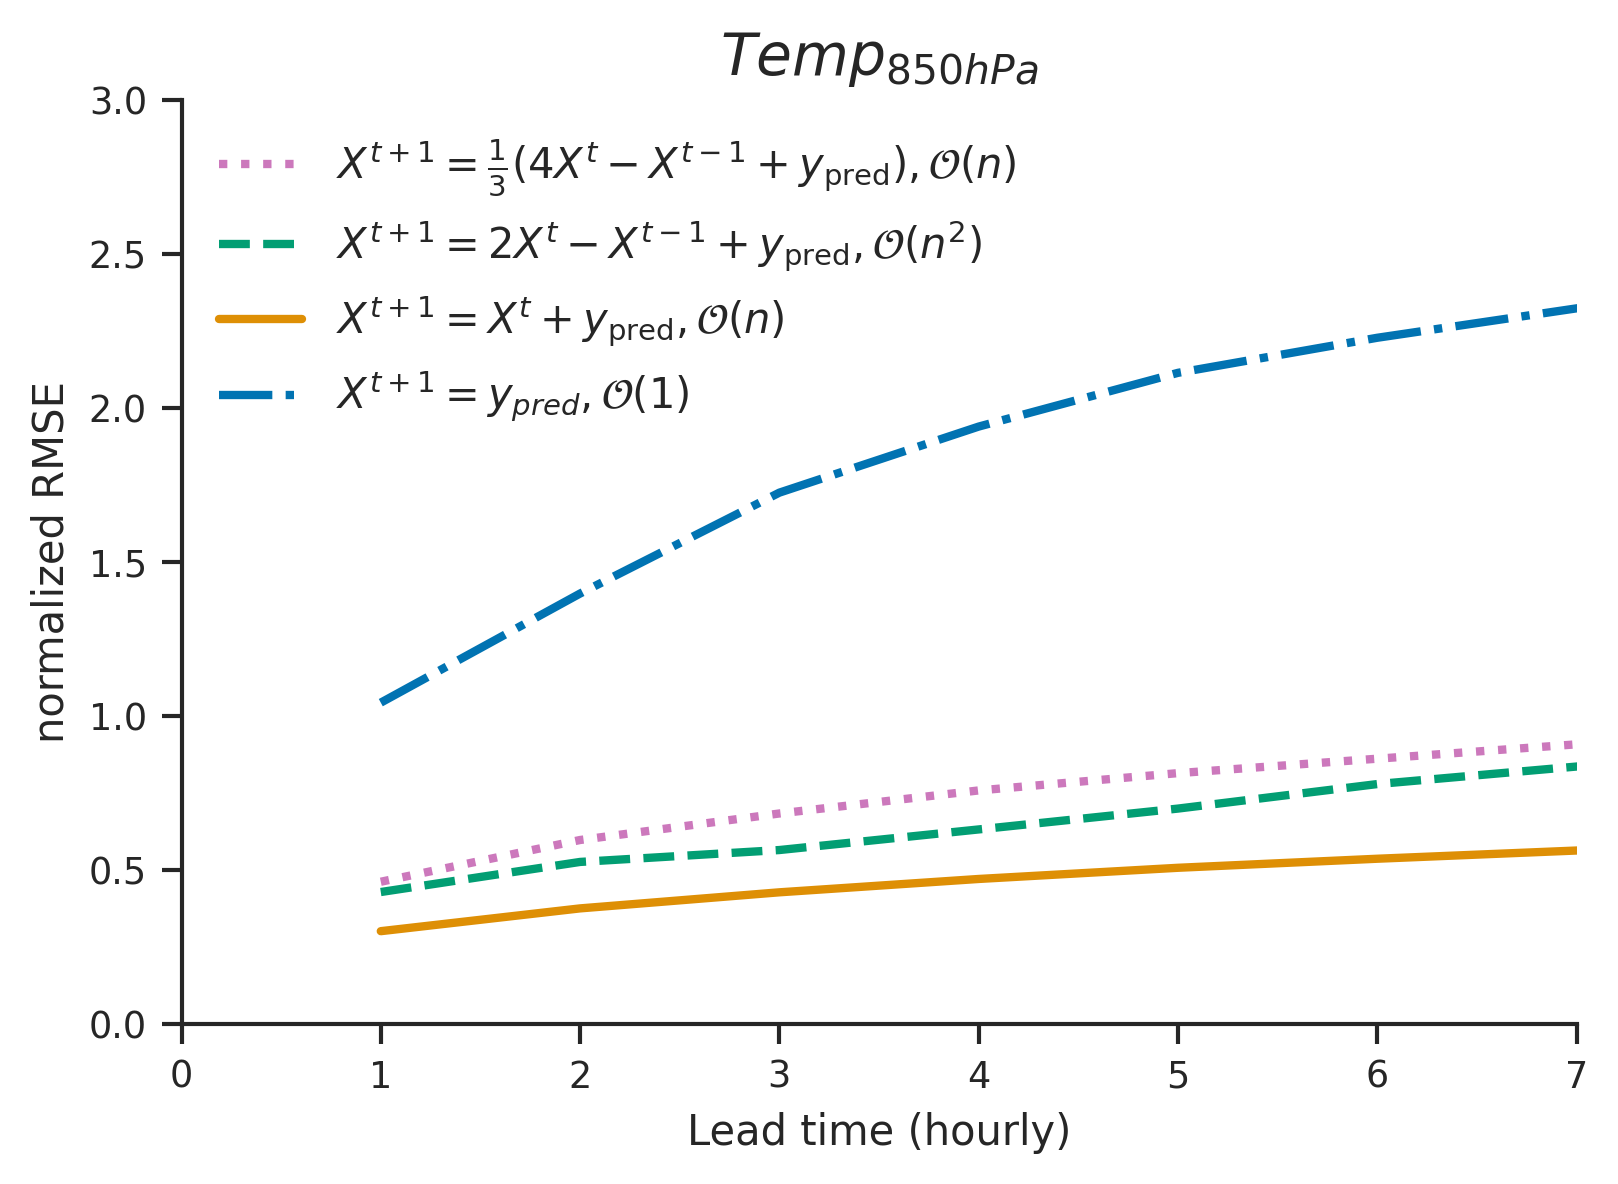

In [289]:
# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

LTs = np.arange(1, 43, 1)

# Plot with distinct, publication-quality colors and styles

ax.plot(LTs, df_base_2_order_bckwrd, label=r'$X^{t+1} = \frac{1}{3} (4X^{t} - X^{t-1} + y_{\text{pred}}) , \mathcal{O}(n)$',
        color=palette[4], linestyle=':', linewidth=2)
ax.plot(LTs, df_base_2_order, label=r'$X^{t+1} = 2X^{t} - X^{t-1} + y_{\text{pred}}, \mathcal{O}(n^2)$',
        color=palette[2], linestyle='--', linewidth=2)
ax.plot(LTs, df_base_1_order, label=r'$X^{t+1} = X^{t} + y_{\text{pred}}, \mathcal{O}(n)$',
        color=palette[1], linestyle='-', linewidth=2)
ax.plot(LTs, df_base_0_order, label=r'$X^{t+1}=y_{pred}, \mathcal{O}(1)$',
        color=palette[0], linestyle='-.', linewidth=2)





# Labels and title with LaTeX for better typography
ax.set_title(var_name[k], fontsize=14, weight='bold')
ax.set_xlabel(r'Lead time (hourly)', fontsize=10)
ax.set_ylabel(r'normalized RMSE', fontsize=10)
ax.set_ylim(0,3)
ax.set_xlim(0,7)

# Customize legend
ax.legend(frameon=False, fontsize=10, loc='upper left')

# Remove top and right borders
sns.despine()

# Show the plot
plt.show()

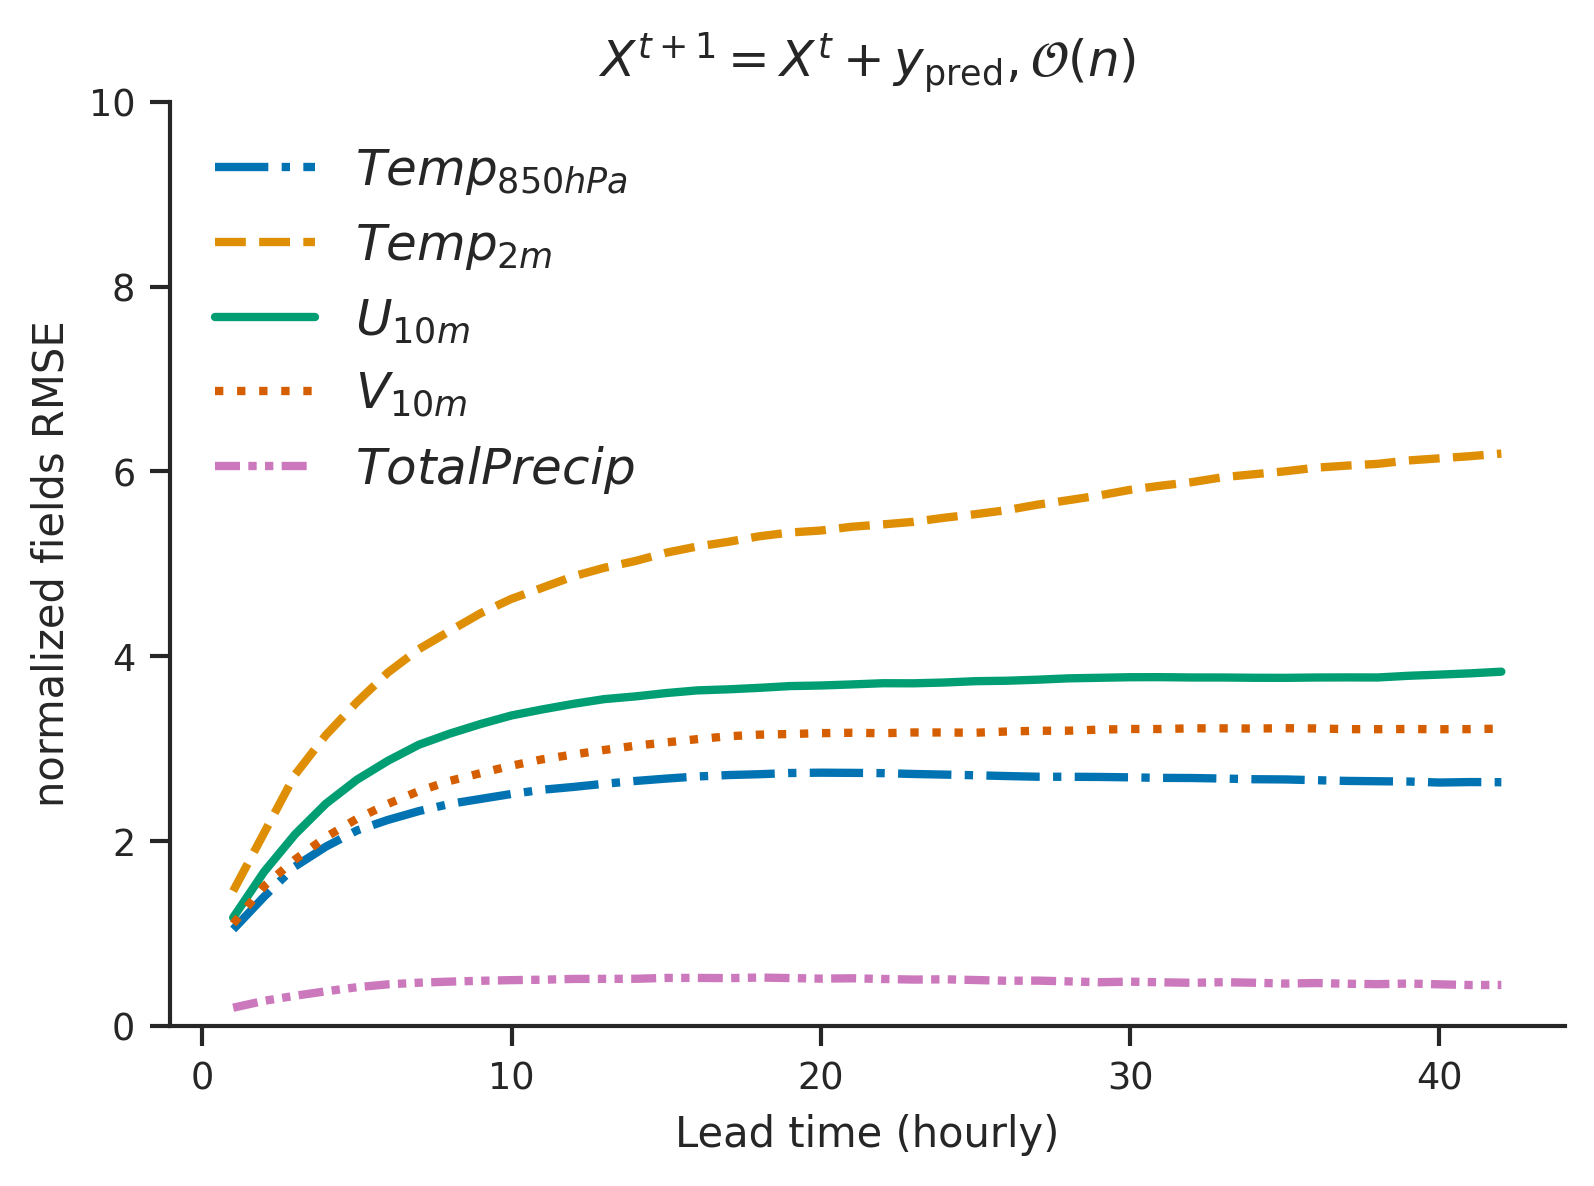

In [235]:
with open("/data/titan_21var/base_0order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

LTs = np.arange(1, 43, 1)

# Plot with distinct, publication-quality colors and styles
var = ["aro_t_850hpa", "aro_t2m_2m", "aro_u10_10m", "aro_v10_10m", "aro_tp_0m"]
var_name = [r'$Temp_{850hPa}$', r'$Temp_{2m}$', r'$U_{10m}$', r'$V_{10m}$', r'$Total Precip$']
linestyle = ['-.', '--', '-', ':', (0, (3, 1, 1, 1, 1, 1))]

for k in range(5):

        ax.plot(LTs, data[var[k]], label=var_name[k],
                color=palette[k], linestyle=linestyle[k], linewidth=2)


# Labels and title with LaTeX for better typography
ax.set_xlabel(r'Lead time (hourly)', fontsize=10)
ax.set_ylabel(r'normalized fields RMSE', fontsize=10)
ax.set_title(r'$X^{t+1} = X^{t} + y_{\text{pred}}, \mathcal{O}(n)$', fontsize=12, weight='bold')
ax.set_ylim(0, 10)

# Customize legend
ax.legend(frameon=False, fontsize=12, loc='upper left')

# Remove top and right borders
sns.despine()

# Show the plot
plt.show()

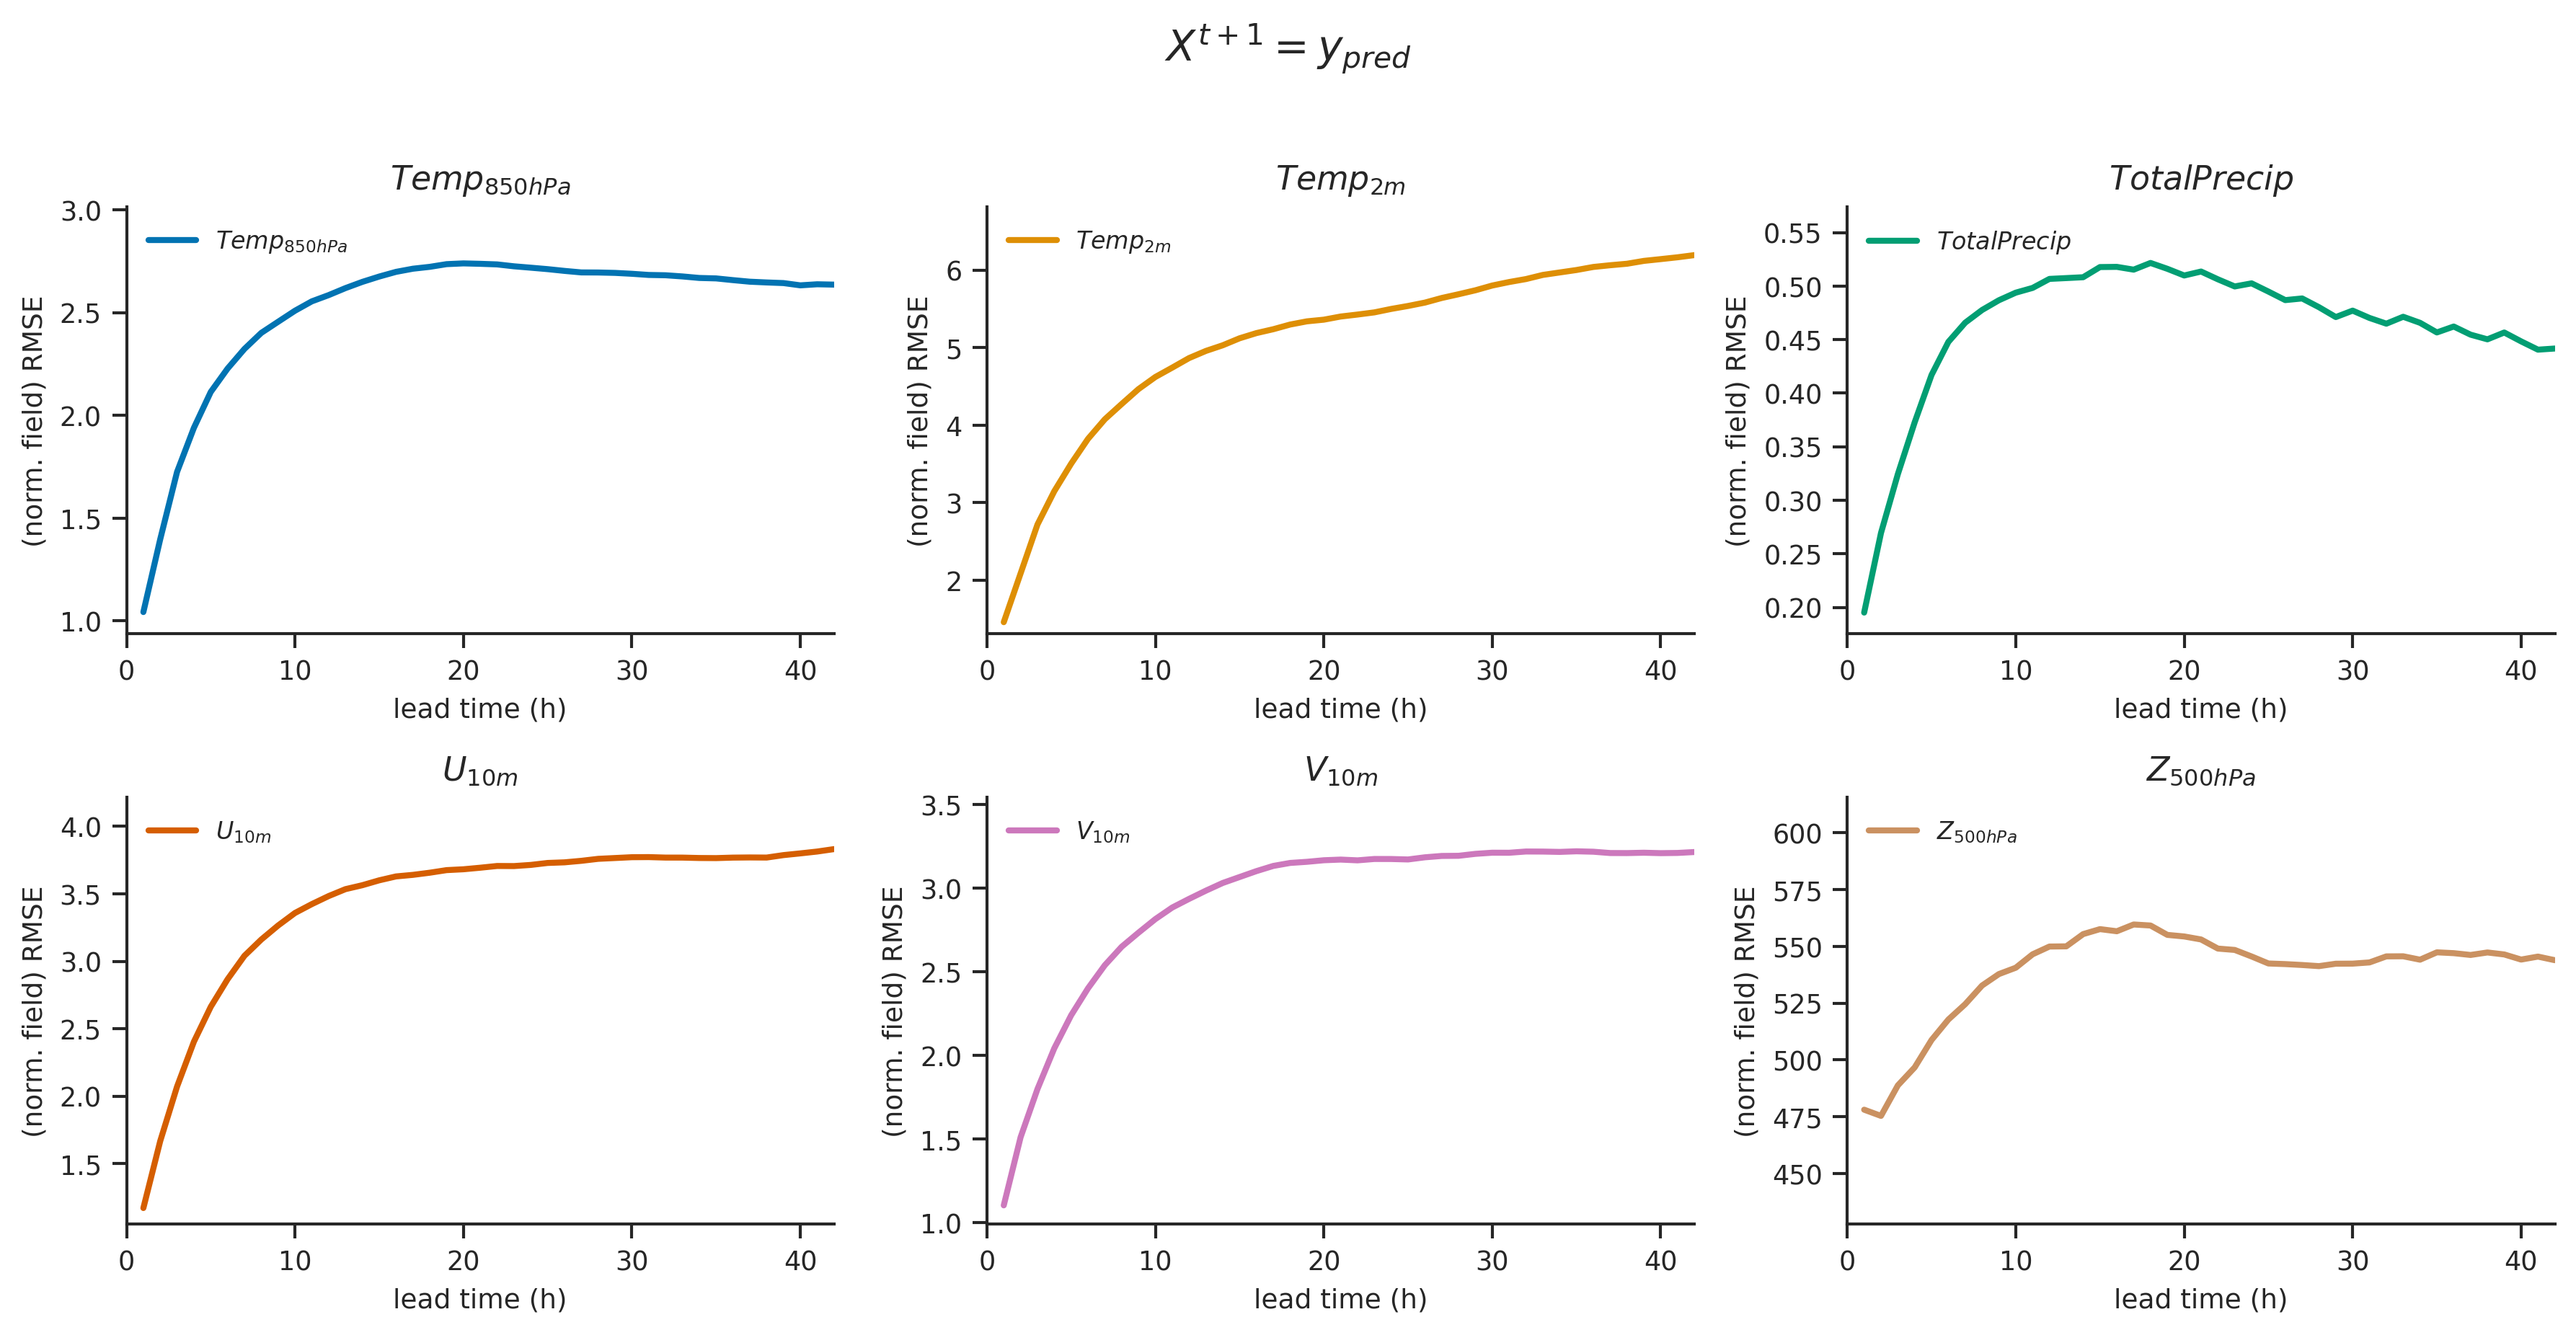

In [9]:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your JSON data
with open("/data/titan_21var/base_0order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Lead times
LTs = np.arange(1, 43, 1)

# Variables, names, and line styles
var = ["aro_t_850hpa", "aro_t2m_2m","aro_tp_0m", "aro_u10_10m", "aro_v10_10m",  "aro_z_500hpa"]
var_name = [r'$Temp_{850hPa}$', r'$Temp_{2m}$',r'$Total Precip$', r'$U_{10m}$', r'$V_{10m}$',  r'$Z_{500hPa}$']
linestyle = ['-.', '--', '-', ':', (0, (3, 1, 1, 1, 1, 1)), (0, (3, 5, 1, 5))]

# Create subplots grid (2 rows, 3 cols → 6 panels, but last one will be empty)
fig, axes = plt.subplots(2, 3, figsize=(12, 6), dpi=300)
axes = axes.flatten()  # Flatten for easy iteration

# Loop through each variable
for k in range(len(var)):
    ax = axes[k]
    ax.plot(LTs, data[var[k]], label=var_name[k],
            color=palette[k], linestyle='-', linewidth=2)

    # Labels
    ax.set_xlabel(r'lead time (h)', fontsize=9)
    ax.set_ylabel(r'(norm. field) RMSE', fontsize=9)
    ax.set_title(var_name[k], fontsize=11, weight='bold')

    # Example: independent axis limits (you can set per variable)
    ax.set_xlim(0, 42)
    # if var[k]=="aro_z_500hpa":
    #     ax.set_ylim(400, np.max(data[var[k]]) * 1.1)
    # elif var[k]=="aro_tp_0m":
    #     ax.set_ylim(0, np.max(data[var[k]]) * 1.1)
    # else:
    #     ax.set_ylim(np.min(data[var[k]]), np.max(data[var[k]]) * 1.1)  # auto-scaled individually
    ax.set_ylim(np.min(data[var[k]])*0.9, np.max(data[var[k]]) * 1.1)

    # Legend inside each subplot
    ax.legend(frameon=False, fontsize=8, loc='upper left')

    sns.despine(ax=ax)

fig.suptitle(
    r'$X^{t+1}=y_{pred}$',
    fontsize=14, weight='bold', y=1.02
)

plt.tight_layout()
plt.show()


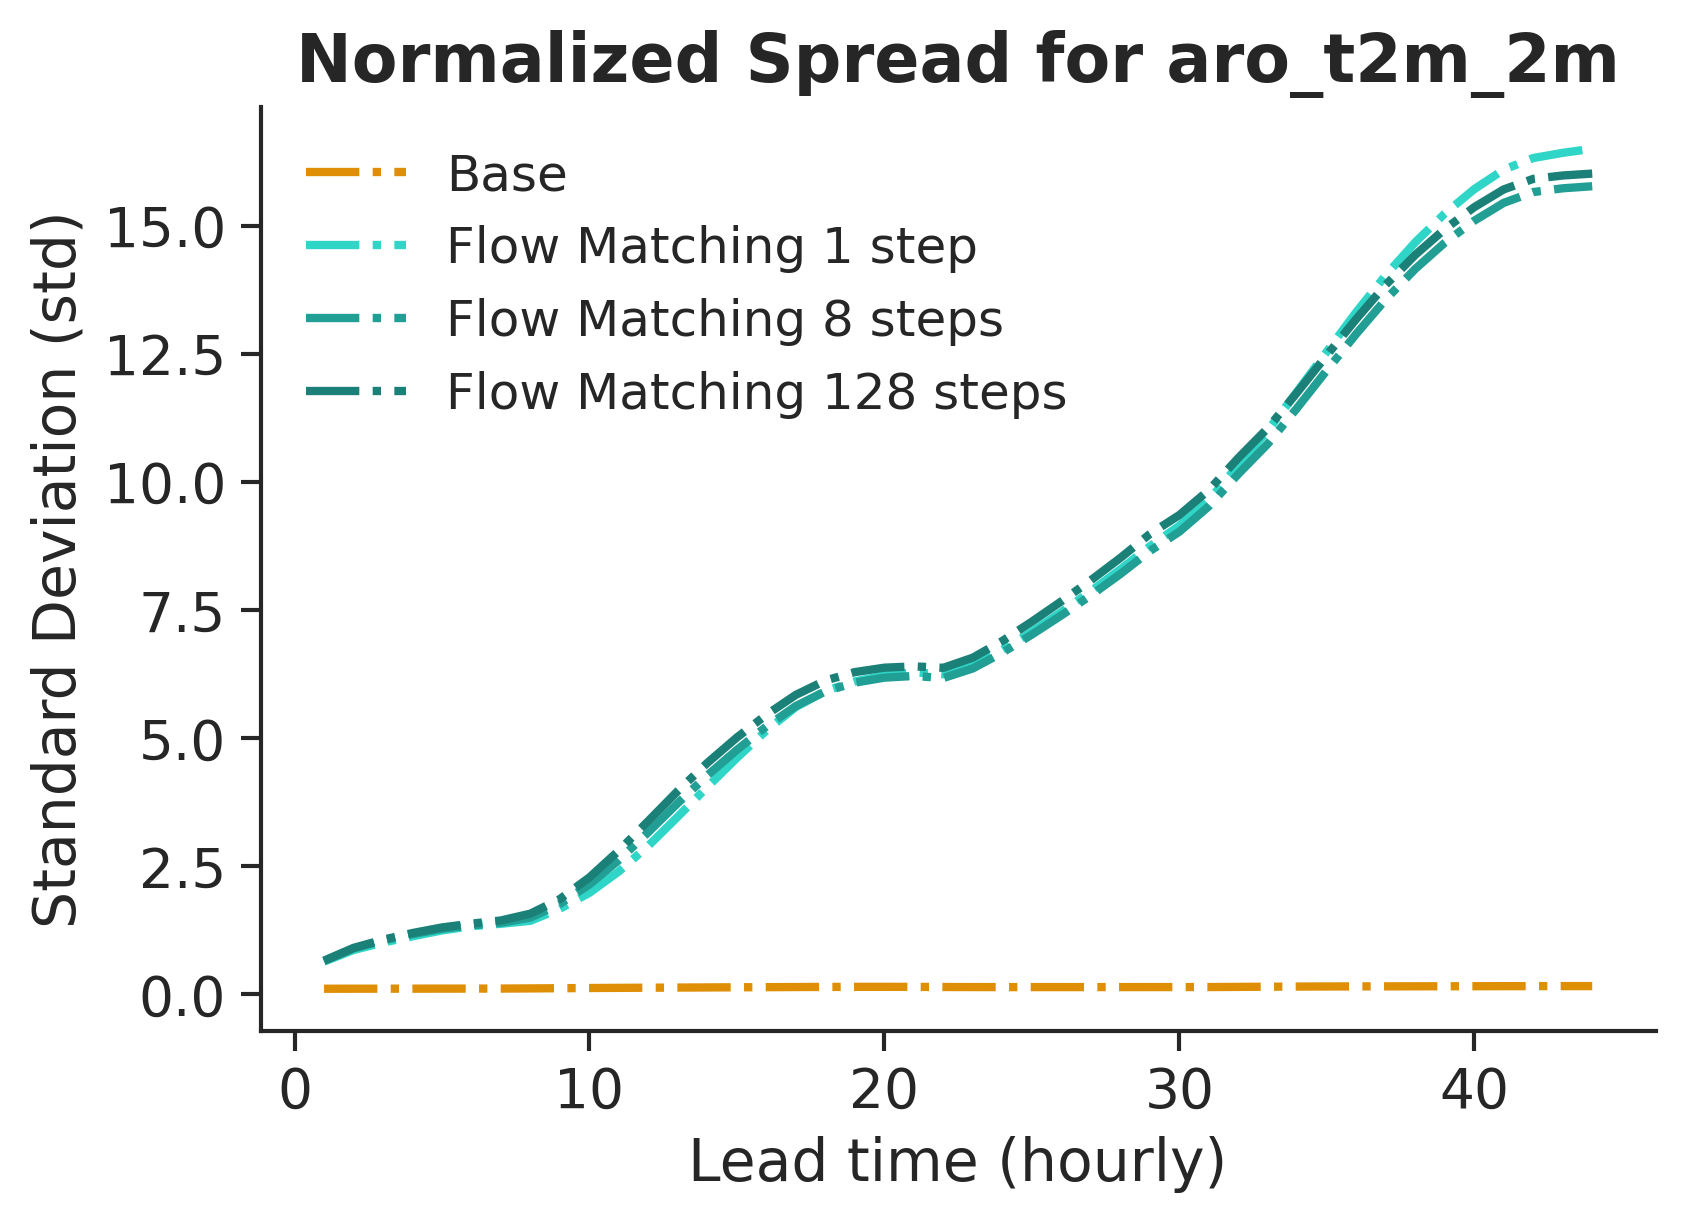

In [ ]:
# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1.5)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

LTs = np.arange(1, 45, 1)

# Plot with distinct, publication-quality colors and styles

ax.plot(df_base['step'], df_base['value'], label='Base',
        color=palette[1], linestyle='-.', linewidth=2)
ax.plot(df_forcing['step'], df_forcing['value'], label='Forcing',
        color=palette[2], linestyle='-.', linewidth=2)
ax.plot(df_smooth['step'], df_smooth['value'], label='Smooth',
        color=palette[3], linestyle='-.', linewidth=2)
ax.plot(df_stoEPA['step'], df_stoEPA['value'], label='Stochastic EPA',
        color=palette[4], linestyle='-.', linewidth=2)
ax.plot(LTs, value_1, label='Flow Matching 1 step',
        color="#2fd6c7", linestyle='-.', linewidth=2)
# ax.plot(LTs, value_8, label='Flow Matching 4 steps',
#         color="#229f94", linestyle='-.', linewidth=2)
# ax.plot(LTs, value_128, label='Flow Matching 128 steps',
#         color="#1b8077", linestyle='-.', linewidth=2)

# Labels and title with LaTeX for better typography
ax.set_xlabel(r'Lead time (hourly)', fontsize=14)
ax.set_ylabel(r'RMSE', fontsize=14)
ax.set_title(r'Distance to Poesy members for ' + var, fontsize=16, weight='bold')

# Customize legend
ax.legend(frameon=False, fontsize=12)

# Remove top and right borders
sns.despine()

# Show the plot
plt.show()

## Spread plots per LTs

In [25]:
var = "z_500hpa"

In [26]:
log_dir = "/data/baseARP/test_poesy/Test_std_timestep_pearo_"+var+"_poesy_refacto_EURW1S40_refacto/"
reader = SummaryReader(log_dir)
df_poesy = reader.scalars

log_dir = "/data/baseARP/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
reader = SummaryReader(log_dir)
df_base = reader.scalars

log_dir = "/data/Unetrpp_crps_forcing_ARP/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
reader = SummaryReader(log_dir)
df_forcing = reader.scalars

# log_dir = "/data/Unetrpp_crps_smooth/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_smooth = reader.scalars

# log_dir = "/data/Unetrpp_crps_stoEPA/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_stoEPA = reader.scalars

log_dir = "/data/Unetrpp_FM_forcing_ARP_v2/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
reader = SummaryReader(log_dir)
df_FM1 = reader.scalars

# log_dir = "/data/Unetrpp_FM/test_poesy_4steps/Test_std_timestep_pearo_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_FM8 = reader.scalars

# log_dir = "/data/Unetrpp_FM/test_poesy_128steps/Test_std_timestep_pearo_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_FM128 = reader.scalars

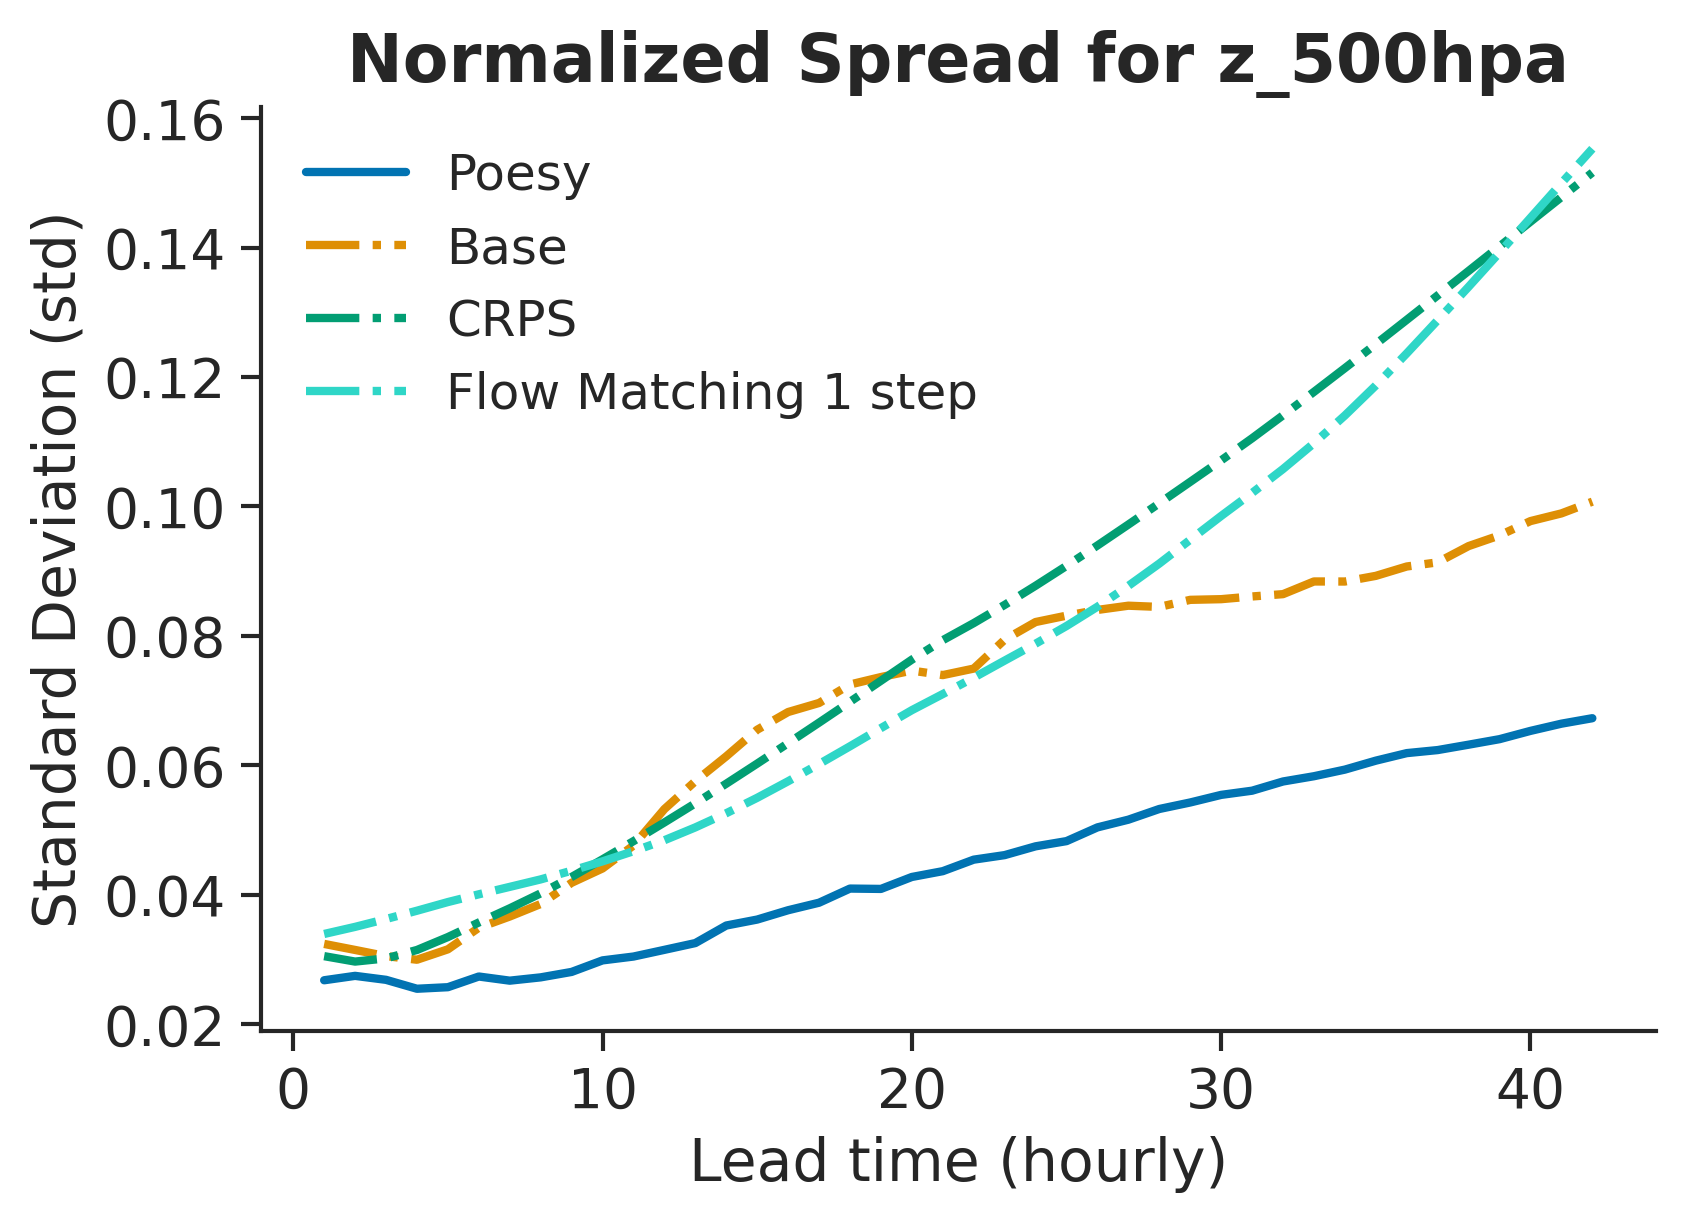

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1.5)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

# Plot with distinct, publication-quality colors and styles
ax.plot(df_poesy['step'], df_poesy['value'], label='Poesy',
        color=palette[0], linestyle='-', linewidth=2)
ax.plot(df_base['step'], df_base['value'], label='Base',
        color=palette[1], linestyle='-.', linewidth=2)
ax.plot(df_forcing['step'], df_forcing['value'], label='rse',
        color=palette[2], linestyle='-.', linewidth=2)
# ax.plot(df_smooth['step'], df_smooth['value'], label='Smooth',
#         color=palette[3], linestyle='-.', linewidth=2)
# ax.plot(df_stoEPA['step'], df_stoEPA['value'], label='Stochastic EPA',
#         color=palette[4], linestyle='-.', linewidth=2)
ax.plot(df_FM1['step'], df_FM1['value'], label='Flow Matching 1 step',
        color="#2fd6c7", linestyle='-.', linewidth=2)
# ax.plot(df_FM8['step'], df_FM8['value'], label='Flow Matching 4 steps',
#         color="#229f94", linestyle='-.', linewidth=2)
# ax.plot(df_FM128['step'], df_FM128['value'], label='Flow Matching 128 steps',
#         color="#1b8077", linestyle='-.', linewidth=2)

# Labels and title with LaTeX for better typography
ax.set_xlabel(r'Lead time (hourly)', fontsize=14)
ax.set_ylabel(r'Standard Deviation (std)', fontsize=14)
ax.set_title(r'Normalized Spread for ' + var, fontsize=16, weight='bold')

# Customize legend
ax.legend(frameon=False, fontsize=12)

# Remove top and right borders
sns.despine()

# Save as a high-quality vector image
plt.savefig("normalized_spread_std.pdf", bbox_inches='tight', transparent=True)

# Show the plot
plt.show()


## Spread Skill Plots

In [25]:
var = "pearo_t2m_2m"

In [ ]:
poesy_ssp = np.load(f"/data/base/test_poesy/pepearo_spread_skill_plot_per_param_{var}_LT_0-10.npy")

base_ssp = np.load(f"/data/base/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

forcing_ssp = np.load(f"/data/Unetrpp_rse_8nm_v2/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

smooth_ssp = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

stoEPA_ssp = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

FM_ssp = np.load(f"/data/Unetrpp_FM/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy") 

# FM8_ssp = np.load(f"/data/Unetrpp_FM/test_poesy_4steps/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

# FM128_ssp = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

In [ ]:
# poesy_ssp = np.load(f"/data/base/test_poesy/pepearo_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# base_ssp = np.load(f"/data/base/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# forcing_ssp = np.load(f"/data/Unetrpp_crps_8nm_v2/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# smooth_ssp = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# stoEPA_ssp = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# FM_ssp = np.load(f"/data/Unetrpp_FM/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy") 

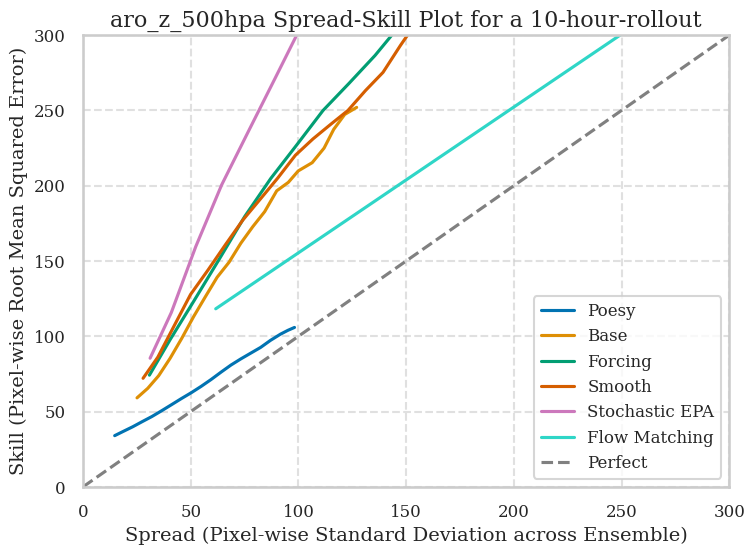

In [ ]:
sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,  # Set to True if LaTeX is installed
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})
plt.figure(figsize=(8, 6))
sns.lineplot(x=poesy_ssp[0], y=poesy_ssp[1], label="Poesy", color=palette[0])
sns.lineplot(x=base_ssp[0], y=base_ssp[1],  label="Base", color=palette[1])
sns.lineplot(x=forcing_ssp[0], y=forcing_ssp[1],  label="Forcing", color=palette[2])
sns.lineplot(x=smooth_ssp[0], y=smooth_ssp[1],  label="Smooth", color=palette[3])
sns.lineplot(x=stoEPA_ssp[0], y=stoEPA_ssp[1],  label="Stochastic EPA", color=palette[4])
sns.lineplot(x=FM_ssp[0], y=FM_ssp[1],  label="Flow Matching", color="#2fd6c7")
# sns.lineplot(x=FM8_ssp[0], y=FM8_ssp[1],  label="Flow Matching 4 steps", color="#229f94")
# sns.lineplot(x=FM128_ssp[0], y=FM128_ssp[1],  label="Flow Matching 128 steps", color="#1b8077")

# Add perfect line y=x
x = np.linspace(0, 300, 100)
y = x
plt.plot(x, y, color="grey", linestyle="--", label="Perfect")

plt.xlabel("Spread (Pixel-wise Standard Deviation across Ensemble)")
plt.ylabel("Skill (Pixel-wise Root Mean Squared Error)")
plt.title(var+" Spread-Skill Plot for a 10-hour-rollout")
plt.grid(True, linestyle="--", alpha=0.6)
plt.xlim(0, 300)
plt.ylim(0, 300)
plt.legend()
plt.tight_layout()
plt.show()


## Spread Error Ratio 

In [45]:
var = "pearo_z_500hpa"

In [46]:
poesy_rse = np.load(f"/data/baseARP/test_poesy/pearo_spread_error_ratio_plot_per_param_{var}.npy")

base_rse = np.load(f"/data/baseARP/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

forcing_rse = np.load(f"/data/Unetrpp_crps_forcing_ARP/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

# smooth_rse = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

# stoEPA_rse = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

FM_rse = np.load(f"/data/Unetrpp_FM_forcing_ARP_v2/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")
# FM8_rse = np.load(f"/data/Unetrpp_FM/test_poesy_4steps/preds_spread_error_ratio_plot_per_param_{var}.npy")
# FM128_rse = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/preds_spread_error_ratio_plot_per_param_{var}.npy")

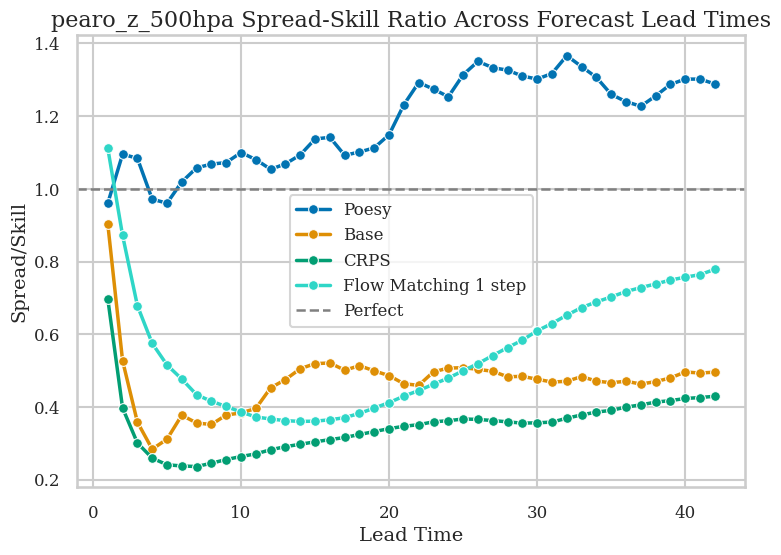

In [47]:
# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,  # Set to True if LaTeX is installed
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

lead_times = np.arange(1, poesy_rse.shape[0] + 1)
plt.figure(figsize=(8, 6))
sns.lineplot(x=lead_times, y=poesy_rse, marker="o", markersize=7, label="Poesy", linewidth=2.5, color=palette[0])
sns.lineplot(x=lead_times, y=base_rse, marker="o", markersize=7, label="Base", linewidth=2.5, color=palette[1])
sns.lineplot(x=lead_times, y=forcing_rse, marker="o", markersize=7, label="CRPS", linewidth=2.5, color=palette[2])
# sns.lineplot(x=lead_times, y=smooth_rse, marker="o", markersize=7, label="Smooth", linewidth=2.5, color=palette[3])
# sns.lineplot(x=lead_times, y=stoEPA_rse, marker="o", markersize=7, label="Stochastic EPA", linewidth=2.5, color=palette[4])
sns.lineplot(x=lead_times, y=FM_rse, marker="o", markersize=7, label="Flow Matching 1 step", linewidth=2.5, color="#2fd6c7")
# sns.lineplot(x=lead_times, y=FM8_rse, marker="o", markersize=7, label="Flow Matching 4 steps", linewidth=2.5, color="#229f94")
# sns.lineplot(x=lead_times, y=FM128_rse, marker="o", markersize=7, label="Flow Matching 128 steps", linewidth=2.5, color="#1b8077")

# Add perfect ratio reference line
plt.axhline(y=1, color="grey", linestyle="--", linewidth=1.8, label="Perfect")

# Labels and title
plt.xlabel("Lead Time")
plt.ylabel("Spread/Skill")
plt.title(f"{var} Spread-Skill Ratio Across Forecast Lead Times")
plt.legend(loc="best", frameon=True)

# Tight layout and publication-ready formatting
plt.tight_layout()
plt.show()

## CRPS

In [13]:
var = "pearo_t2m_2m"

In [ ]:
poesy_crps = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var_1rlt/pearo_error_plot_per_param_{var}.npy")

order0_crps = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var_1rlt/preds_error_plot_per_param_{var}.npy")

# base_crps = np.load(f"/data/baseARP/test_poesy/preds_crps_plot_per_param_{var}.npy")

# forcing_crps = np.load(f"/data/Unetrpp_crps_forcing_ARP/test_poesy/preds_crps_plot_per_param_{var}.npy")

# # smooth_crps = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_crps_plot_per_param_{var}.npy")

# # stoEPA_crps = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_crps_plot_per_param_{var}.npy")

# FM_crps = np.load(f"/data/Unetrpp_FM_forcing_ARP_v2/test_poesy/preds_crps_plot_per_param_{var}.npy")
# # FM8_crps = np.load(f"/data/Unetrpp_FM/test_poesy_4steps/preds_crps_plot_per_param_{var}.npy")
# # FM128_crps = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/preds_crps_plot_per_param_{var}.npy")

In [ ]:
["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m", "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

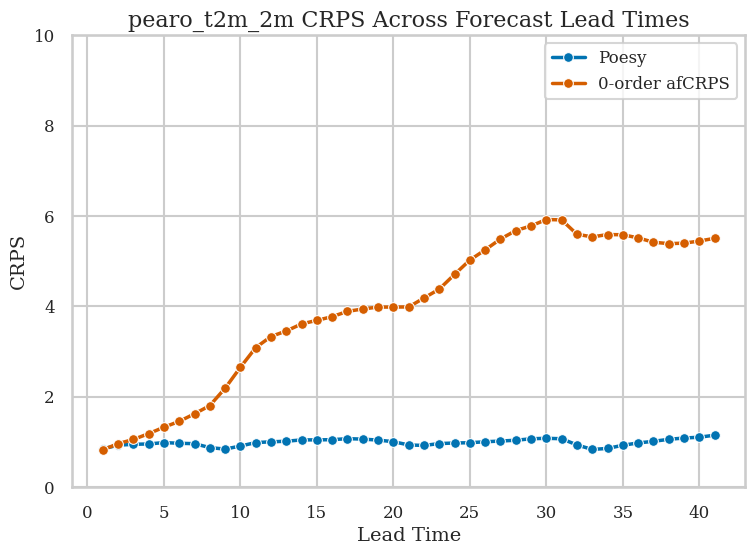

In [17]:
# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

lead_times = np.arange(1, poesy_crps.shape[0] + 1)
plt.figure(figsize=(8, 6))
sns.lineplot(x=lead_times, y=poesy_crps, marker="o", markersize=7, label="Poesy", linewidth=2.5, color=palette[0])
sns.lineplot(x=lead_times, y=order0_crps, marker="o", markersize=7, label="0-order afCRPS", linewidth=2.5, color=palette[3])
# sns.lineplot(x=lead_times, y=base_crps, marker="o", markersize=7, label="Base", linewidth=2.5, color=palette[1])
# sns.lineplot(x=lead_times, y=forcing_crps, marker="o", markersize=7, label="CRPS", linewidth=2.5, color=palette[2])
# # sns.lineplot(x=lead_times, y=smooth_crps, marker="o", markersize=7, label="Smooth", linewidth=2.5, color=palette[3])
# # sns.lineplot(x=lead_times, y=stoEPA_crps, marker="o", markersize=7, label="Stochastic EPA", linewidth=2.5, color=palette[4])
# sns.lineplot(x=lead_times, y=FM_crps, marker="o", markersize=7, label="Flow Matching 1 step", linewidth=2.5, color="#2fd6c7")
# # sns.lineplot(x=lead_times, y=FM8_crps, marker="o", markersize=7, label="Flow Matching 4 steps", linewidth=2.5, color="#229f94")
# # sns.lineplot(x=lead_times, y=FM128_crps, marker="o", markersize=7, label="Flow Matching 128 steps", linewidth=2.5, color="#1b8077")

# Labels and title
plt.xlabel("Lead Time")
plt.ylabel("CRPS")
plt.ylim(0, 10)
plt.title(f"{var} CRPS Across Forecast Lead Times")
plt.legend(loc="best", frameon=True)
plt.tight_layout()
plt.show()

In [7]:
poesy_crps.shape

(40,)

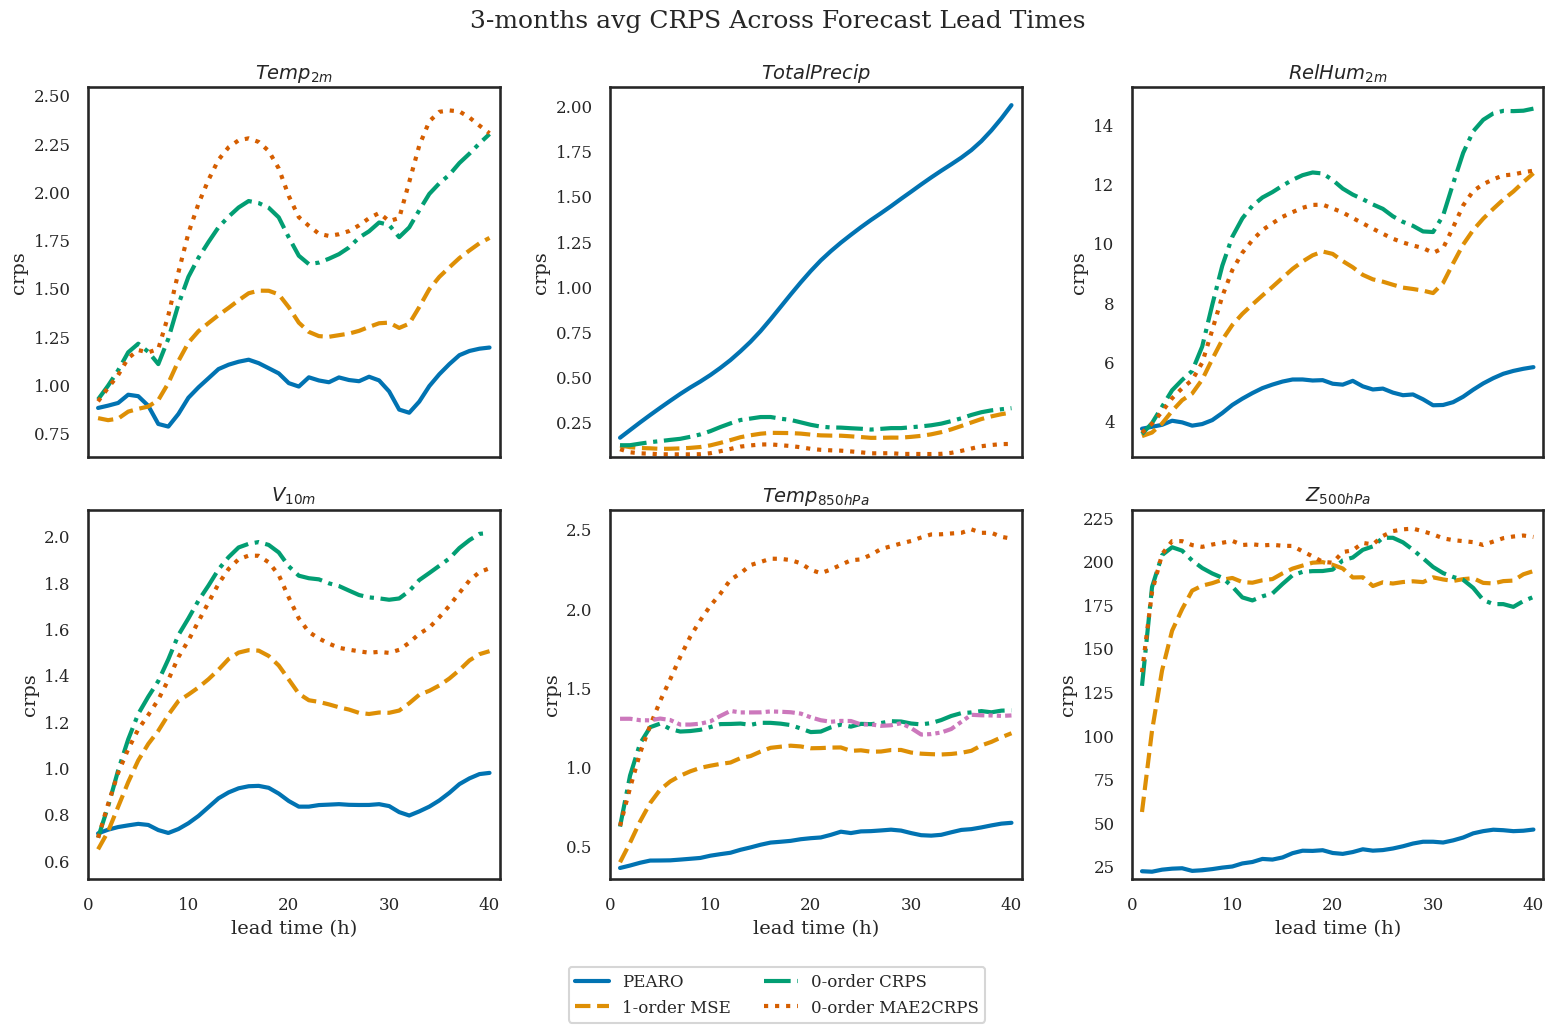

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="white", context="talk", font_scale=1.2)

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

# Example variable list
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]
var_name = [r'$Temp_{2m}$', r'$Total Precip$', r'$Rel Hum_{2m}$',
            r'$V_{10m}$', r'$Temp_{850hPa}$', r'$Z_{500hPa}$']

linestyle = ['-.', '--', '-', ':', (0, (3, 1, 1, 1, 1, 1)), (0, (3, 5, 1, 5))]

# Example lead times
lead_times = np.arange(1, 41)

# Create 2x3 figure
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=False)

# Collect handles for legend
handles, labels = None, None

for i, var in enumerate(vars):
    ax = axes[i // 3, i % 3]

    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_poesy/pearo_crps_plot_per_param_{var}.npy")
    mse_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_poesy/preds_crps_plot_per_param_{var}.npy")
    crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/test_poesy/preds_crps_plot_per_param_{var}.npy")
    mae2crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/test_poesy/preds_crps_plot_per_param_{var}.npy")

    if var == "pearo_t_850hpa":
        mse_PEARP_spectralDS = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/preds_crps_plot_per_param_{var}.npy")[:-1]



    sns.lineplot(x=lead_times, y=poesy,
                 label="PEARO", linewidth=3, color=palette[0], ax=ax, linestyle='-')
    
    sns.lineplot(x=lead_times, y=mse_1order,
                 label="1-order MSE", linewidth=3, color=palette[1], ax=ax, linestyle='--')
    
    sns.lineplot(x=lead_times, y=crps_0order,   
                 label="0-order CRPS", linewidth=3, color=palette[2], ax=ax, linestyle='-.')

    sns.lineplot(x=lead_times, y=mae2crps_0order,
                 label="0-order MAE2CRPS", linewidth=3, color=palette[3], ax=ax, linestyle=':')
    
    
    if var == "pearo_t_850hpa":
        sns.lineplot(x=lead_times, y=mse_PEARP_spectralDS,
                    label="PEARP SpectralDS", linewidth=3, color=palette[4], ax=ax, linestyle=(0, (3, 1, 1, 1, 1, 1)))
    
    ax.set_xlabel("lead time (h)")
    ax.set_ylabel("crps")
    ax.set_xlim(0, 41)
    ax.set_ylim(np.min((poesy, mse_1order, crps_0order, mae2crps_0order)) * 0.8, np.max((poesy, mse_1order, crps_0order, mae2crps_0order)) * 1.05)
    if var == "pearo_t_850hpa":
        ax.set_ylim(np.min((poesy, mse_1order, crps_0order, mae2crps_0order, mse_PEARP_spectralDS)) * 0.8, np.max((poesy, mse_1order, crps_0order, mae2crps_0order, mse_PEARP_spectralDS)) * 1.05)
    ax.set_title(var_name[i], fontsize=14, weight='bold')
    ax.legend(loc="best", frameon=True)
    # Capture legend handles once
    if handles is None and labels is None:
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()  # remove subplot legends

plt.tight_layout()
# Add global title
fig.suptitle("3-months avg CRPS Across Forecast Lead Times", fontsize=18, y=1.02)
# Add global legend at bottom
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=True, fontsize=12)
plt.subplots_adjust(bottom=0.15) 
plt.show()


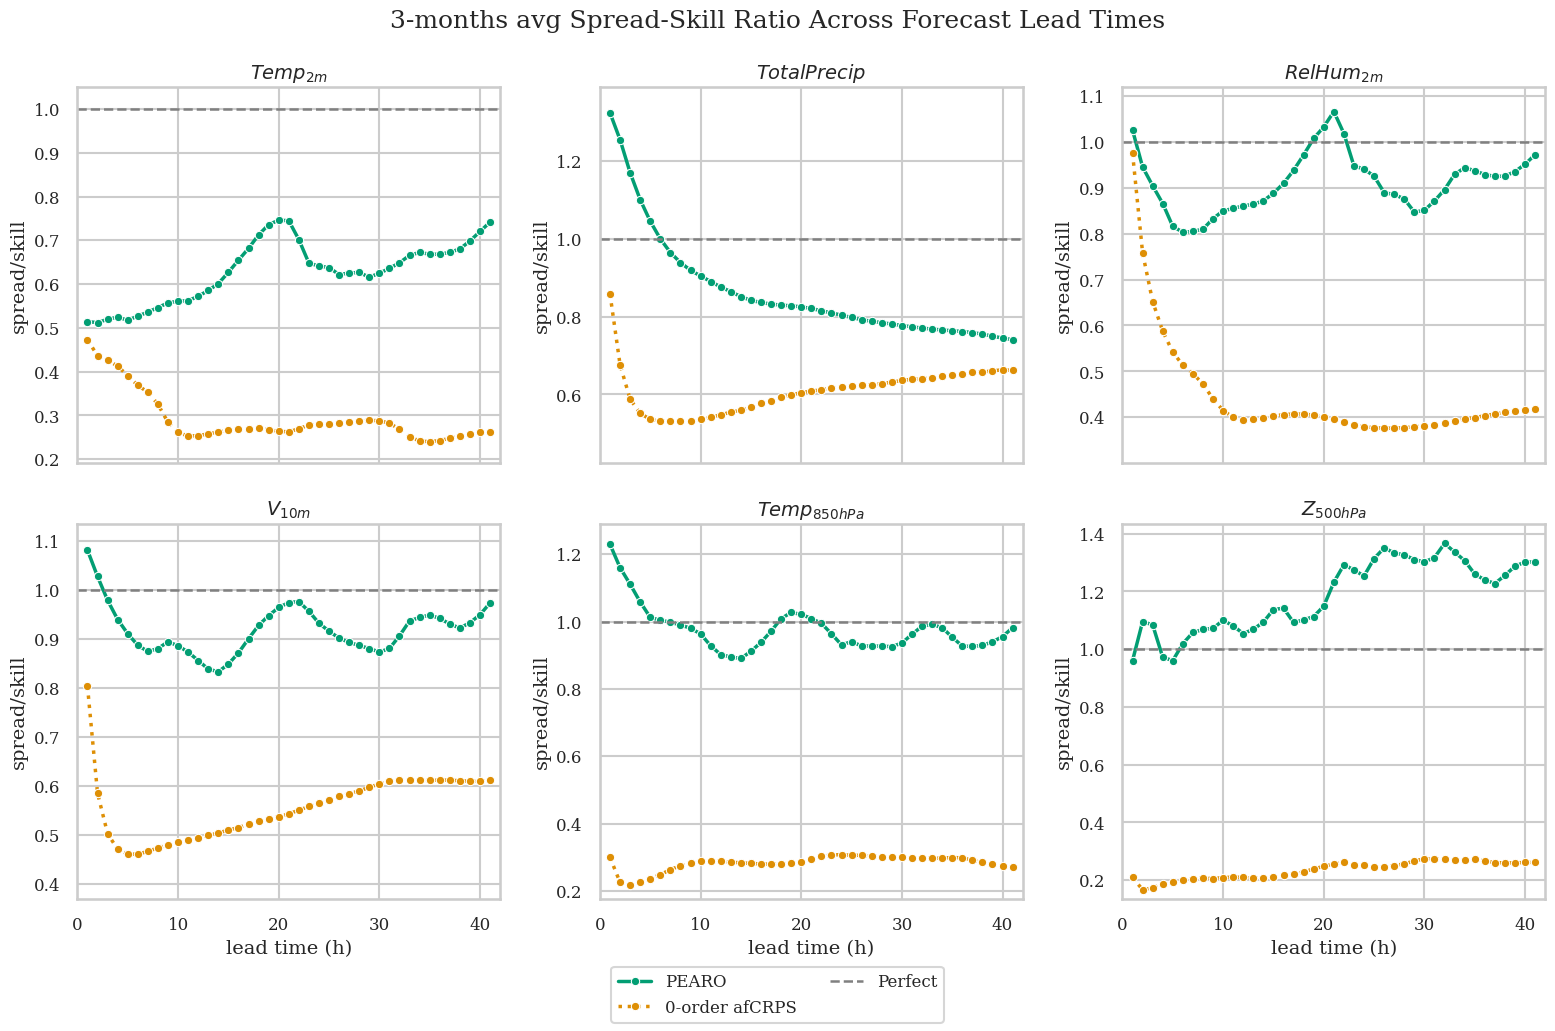

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

# Example variable list
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]
var_name = [r'$Temp_{2m}$', r'$Total Precip$', r'$Rel Hum_{2m}$',
            r'$V_{10m}$', r'$Temp_{850hPa}$', r'$Z_{500hPa}$']

# Example lead times
lead_times = np.arange(1, 42)

# Create 2x3 figure
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=False)

# Collect handles for legend
handles, labels = None, None

for i, var in enumerate(vars):
    ax = axes[i // 3, i % 3]

    poesy_rse = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/pearo_spread_error_ratio_plot_per_param_{var}.npy")
    order0_rse = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/preds_spread_error_ratio_plot_per_param_{var}.npy")

    sns.lineplot(x=lead_times, y=poesy_rse,
                 label="PEARO", linewidth=2.5, color=palette[2], ax=ax, linestyle='-', marker="o", markersize=6)
    sns.lineplot(x=lead_times, y=order0_rse,
                 label="0-order afCRPS", linewidth=2.5, color=palette[1], ax=ax, linestyle=':', marker="o", markersize=6)
    sns.lineplot(x=np.arange(0, poesy_rse.shape[0] + 2), y=np.ones(poesy_rse.shape[0] + 2),
                 label="Perfect", linewidth=1.8, color="grey", ax=ax, linestyle='--')
    
    ax.set_xlabel("lead time (h)")
    ax.set_ylabel("spread/skill")
    ax.set_ylim(np.min((poesy_rse, order0_rse)) * 0.8, np.max((poesy_rse, order0_rse, np.ones(poesy_rse.shape[0]))) * 1.05)
    ax.set_xlim(0, 42)
    ax.set_title(var_name[i], fontsize=14, weight='bold')
    ax.legend(loc="best", frameon=True)
    # Capture legend handles once
    if handles is None and labels is None:
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()  # remove subplot legends

plt.tight_layout()
# Add global title
fig.suptitle("3-months avg Spread-Skill Ratio Across Forecast Lead Times", fontsize=18, y=1.02)
# Add global legend at bottom
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=True, fontsize=12)
plt.subplots_adjust(bottom=0.13) 
plt.show()

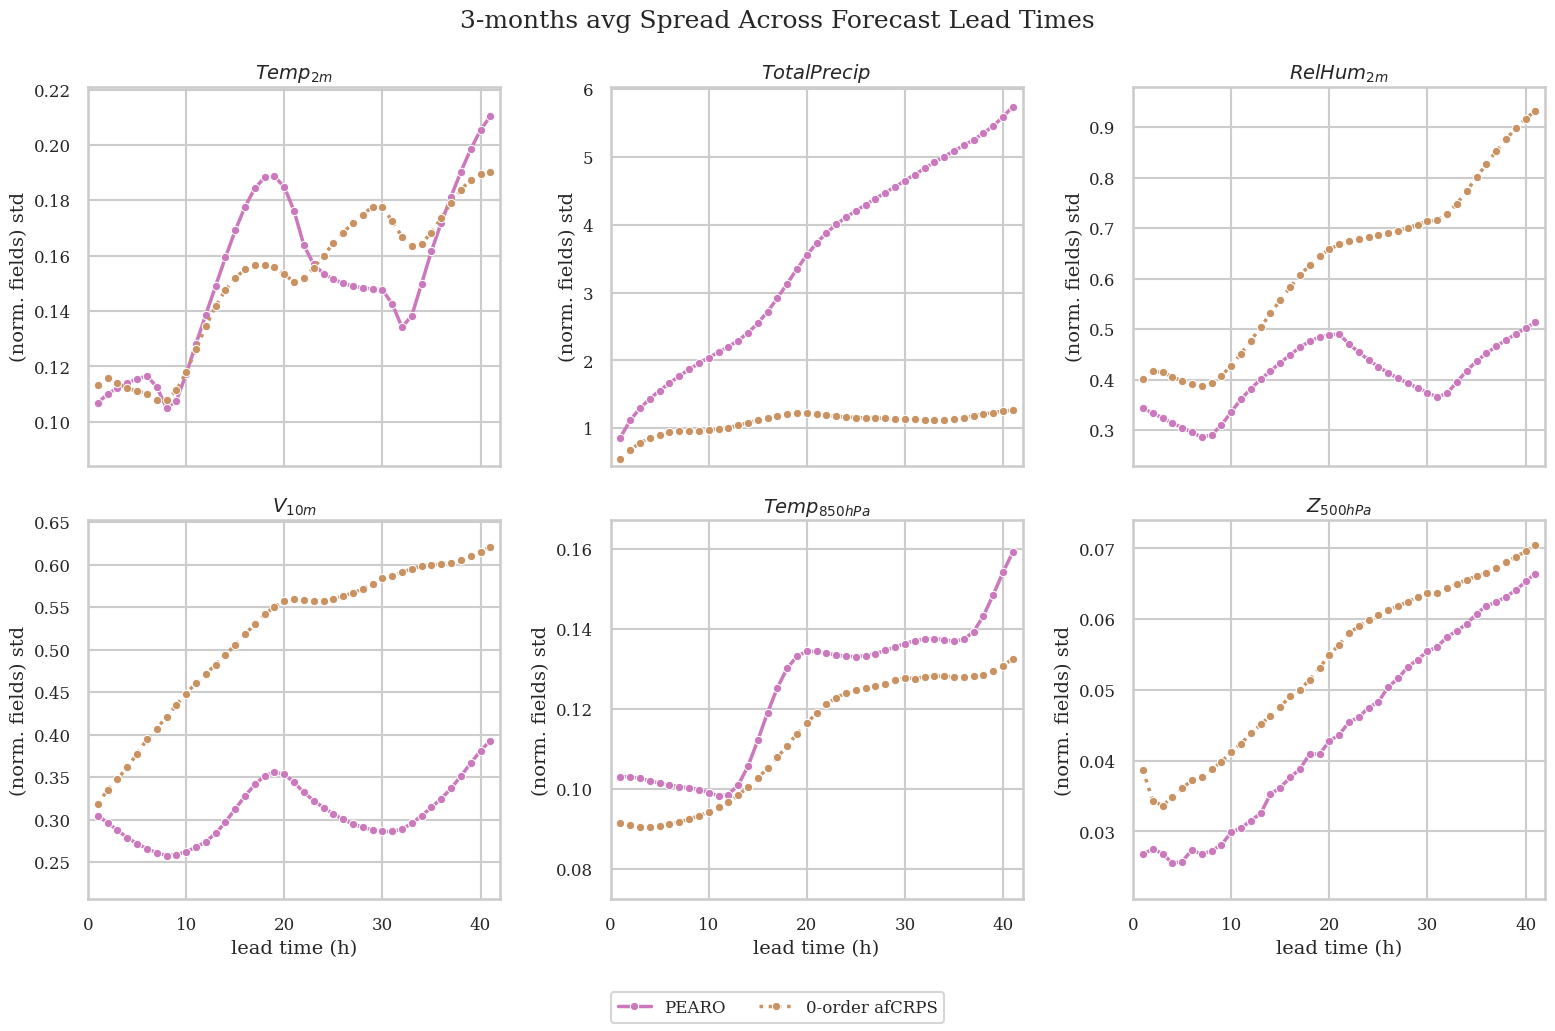

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

# Example variable list
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]
var_name = [r'$Temp_{2m}$', r'$Total Precip$', r'$Rel Hum_{2m}$',
            r'$V_{10m}$', r'$Temp_{850hPa}$', r'$Z_{500hPa}$']

# Example lead times
lead_times = np.arange(1, 42)

# Create 2x3 figure
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=False)

# Collect handles for legend
handles, labels = None, None

for i, var in enumerate(vars):
    ax = axes[i // 3, i % 3]
    
    log_dir = "/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/Test_std_timestep_"+var+"_poesy_refacto_EURW1S40_refacto/"
    reader = SummaryReader(log_dir)
    poesy_std = reader.scalars
    log_dir = "/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/Test_std_timestep_"+var+"_preds"
    reader = SummaryReader(log_dir)
    order0_std = reader.scalars

    sns.lineplot(x=lead_times, y=poesy_std['value'],
                 label="PEARO", linewidth=2.5, color=palette[4], ax=ax, linestyle='-', marker="o", markersize=6)
    sns.lineplot(x=lead_times, y=order0_std['value'],
                 label="0-order afCRPS", linewidth=2.5, color=palette[5], ax=ax, linestyle=':', marker="o", markersize=6)
    
    ax.set_xlabel("lead time (h)")
    ax.set_ylabel("(norm. fields) std")
    ax.set_ylim(np.min((poesy_std['value'], order0_std['value'])) * 0.8, np.max((poesy_std['value'], order0_std['value'])) * 1.05)
    ax.set_xlim(0, 42)
    ax.set_title(var_name[i], fontsize=14, weight='bold')
    ax.legend(loc="best", frameon=True)
    # Capture legend handles once
    if handles is None and labels is None:
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()  # remove subplot legends

plt.tight_layout()
# Add global title
fig.suptitle("3-months avg Spread Across Forecast Lead Times", fontsize=18, y=1.02)
# Add global legend at bottom
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=True, fontsize=12)
plt.subplots_adjust(bottom=0.13) 
plt.show()

## PSD

In [32]:
var = "z_500hpa"

In [33]:
poesy_psd = np.load(f"/data/baseARP/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

base_psd = np.load(f"/data/baseARP/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

# forcing_crps = np.load(f"/data/Unetrpp_crps_forcing_ARP/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

# smooth_crps = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

# stoEPA_crps = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

FM_psd = np.load(f"/data/Unetrpp_FM_forcing_ARP_v2/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")
# FM8_crps = np.load(f"/data/Unetrpp_FM/test_poesy_4steps/test_mean_psd_k_pearo_{var}_24.npy")
# FM128_crps = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/test_mean_psd_k_pearo_{var}_24.npy")

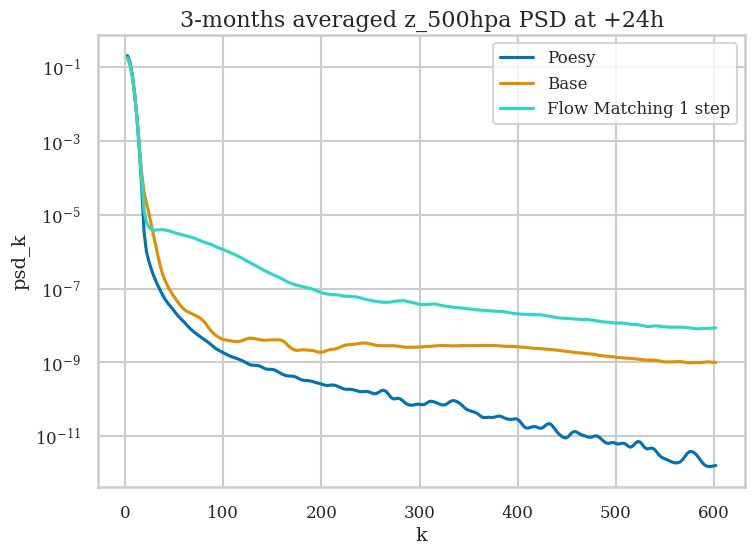

In [34]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

palette = sns.color_palette("colorblind")

# Apply Gaussian smoothing
sigma = 1.5  # Controls the smoothing level (higher = smoother)

poesy_smoothed = gaussian_filter1d(poesy_psd[2], sigma)
base_smoothed = gaussian_filter1d(base_psd[1], sigma)
fm_smoothed = gaussian_filter1d(FM_psd[1], sigma)

plt.figure(figsize=(8, 6))
sns.lineplot(x=poesy_psd[0], y=poesy_smoothed, label="Poesy",  color=palette[0])
sns.lineplot(x=poesy_psd[0], y=base_smoothed, label="Base",  color=palette[1])
sns.lineplot(x=FM_psd[0], y=fm_smoothed, label="Flow Matching 1 step",  color="#2fd6c7")

plt.xlabel("k")
plt.ylabel("psd_k")
plt.yscale("log")
plt.title(f"3-months averaged {var} PSD at +24h")
plt.legend(loc="best", frameon=True)
plt.tight_layout()
plt.show()


## Relative RMSE gains

In [6]:
import json
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
with open("/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_titan/Test_rmse_scores.json", 'r') as file:
    data_spectralDS = json.load(file)
with open("/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data_AR = json.load(file)

LTs = np.arange(1, 42, 1)

# Plot with distinct, publication-quality colors and styles
keys = ["aro_t_850hpa", "aro_u_850hpa", "aro_v_850hpa", "aro_z_850hpa"]

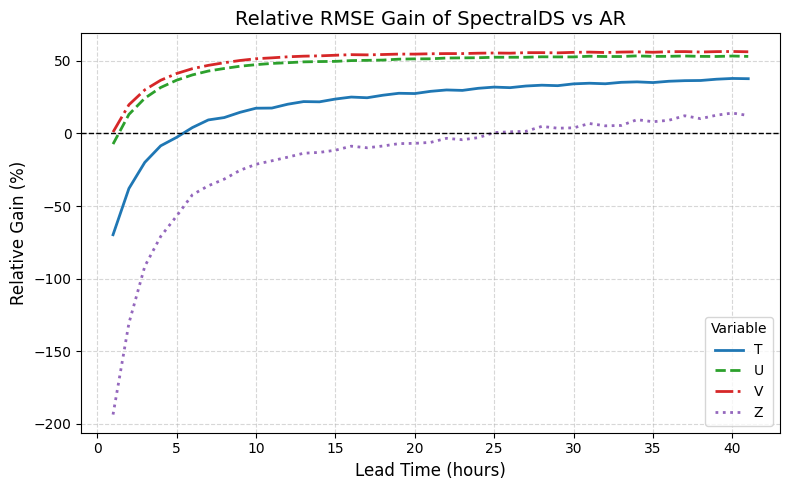

In [10]:
# --- Parameters ---
LTs = np.arange(1, 42, 1)
keys = ["aro_t_850hpa", "aro_u_850hpa", "aro_v_850hpa", "aro_z_850hpa"]

# --- Compute relative gains ---
# Relative gain = 100 * (RMSE_AR - RMSE_SpectralDS) / RMSE_AR
relative_gains = {}
for key in keys:
    rmse_ar = np.array(data_AR[key][:-1])
    rmse_spec = np.array(data_spectralDS[key])
    relative_gains[key] = 100 * (rmse_ar - rmse_spec) / rmse_ar

# --- Plot ---
plt.figure(figsize=(8, 5))

colors = ["#1f77b4", "#2ca02c", "#d62728", "#9467bd"]  # Blue, green, red, purple
linestyles = ["-", "--", "-.", ":"]

for key, color, style in zip(keys, colors, linestyles):
    plt.plot(LTs, relative_gains[key], label=key.replace("aro_", "").replace("_850hpa", "").upper(),
             color=color, linestyle=style, linewidth=2)

plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.xlabel("Lead Time (hours)", fontsize=12)
plt.ylabel("Relative Gain (%)", fontsize=12)
plt.title("Relative RMSE Gain of SpectralDS vs AR", fontsize=14)
plt.legend(title="Variable", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

In [26]:
relative_gains["aro_t_850hpa"][39]

37.84713197143133

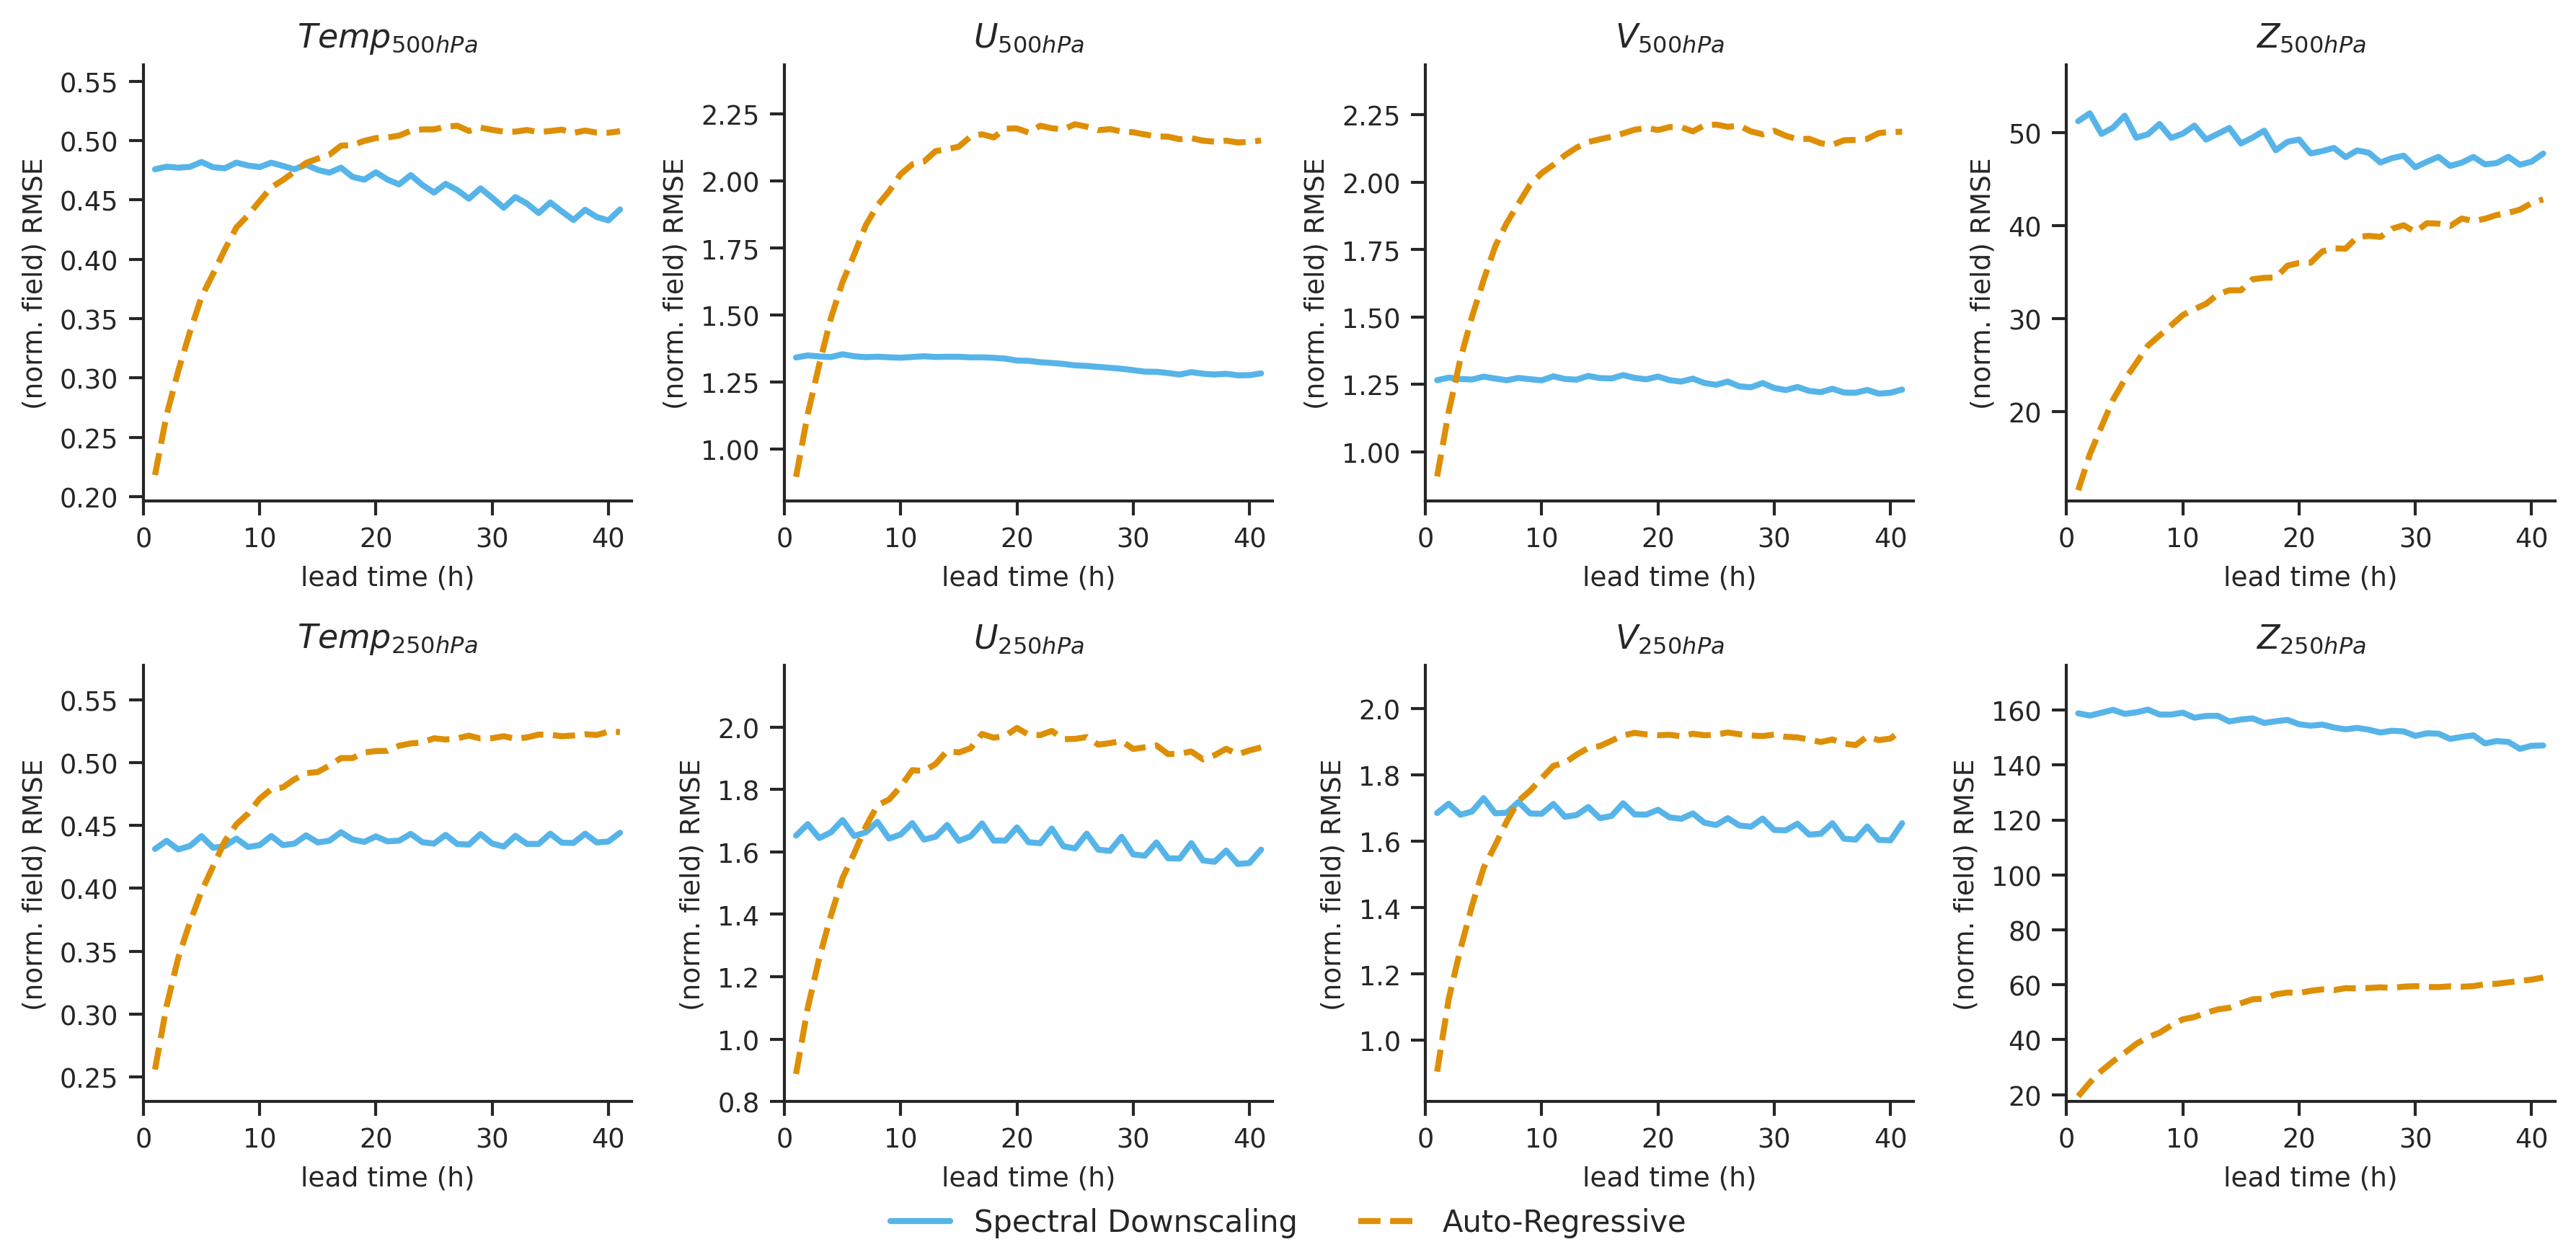

In [30]:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your JSON data
with open("/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_titan/Test_rmse_scores.json", 'r') as file:
    data_spectralDS = json.load(file)
with open("/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data_AR = json.load(file)


# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Lead times
LTs = np.arange(1, 42, 1)

# Variables, names, and line styles
# var = ["aro_t_850hpa", "aro_u_850hpa", "aro_v_850hpa", "aro_z_850hpa", "aro_t_700hpa", "aro_u_700hpa", "aro_v_700hpa", "aro_z_700hpa"] 
var = ["aro_t_500hpa", "aro_u_500hpa", "aro_v_500hpa", "aro_z_500hpa", "aro_t_250hpa", "aro_u_250hpa", "aro_v_250hpa", "aro_z_250hpa"]
# var_name = [r'$Temp_{850hPa}$', r'$U_{850hPa}$', r'$V_{850hPa}$', r'$Z_{850hPa}$', r'$Temp_{700hPa}$', r'$U_{700hPa}$', r'$V_{700hPa}$', r'$Z_{700hPa}$']
var_name = [r'$Temp_{500hPa}$', r'$U_{500hPa}$', r'$V_{500hPa}$', r'$Z_{500hPa}$', r'$Temp_{250hPa}$', r'$U_{250hPa}$', r'$V_{250hPa}$', r'$Z_{250hPa}$']

# Create subplots grid (2 rows, 3 cols → 6 panels, but last one will be empty)
fig, axes = plt.subplots(2, 4, figsize=(12, 6), dpi=300)
axes = axes.flatten()  # Flatten for easy iteration

# Loop through each variable
for k in range(len(var)):
    ax = axes[k]
    ax.plot(LTs, data_spectralDS[var[k]], label="Spectral Downscaling",
            color=palette[9], linestyle='-', linewidth=2)
    ax.plot(LTs, data_AR[var[k]][:-1], label="Auto-Regressive",
            color=palette[1], linestyle='--', linewidth=2)

    # Labels
    ax.set_xlabel(r'lead time (h)', fontsize=9)
    ax.set_ylabel(r'(norm. field) RMSE', fontsize=9)
    ax.set_title(var_name[k], fontsize=11, weight='bold')

    ax.set_xlim(0, 42)
    ax.set_ylim(min(np.min(data_spectralDS[var[k]]), np.min(data_AR[var[k]]))*0.9,
                max(np.max(data_spectralDS[var[k]]), np.max(data_AR[var[k]])) * 1.1)

    sns.despine(ax=ax)

# Create a single legend for all plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=10, borderaxespad=-0.1)

plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the legend
plt.show()

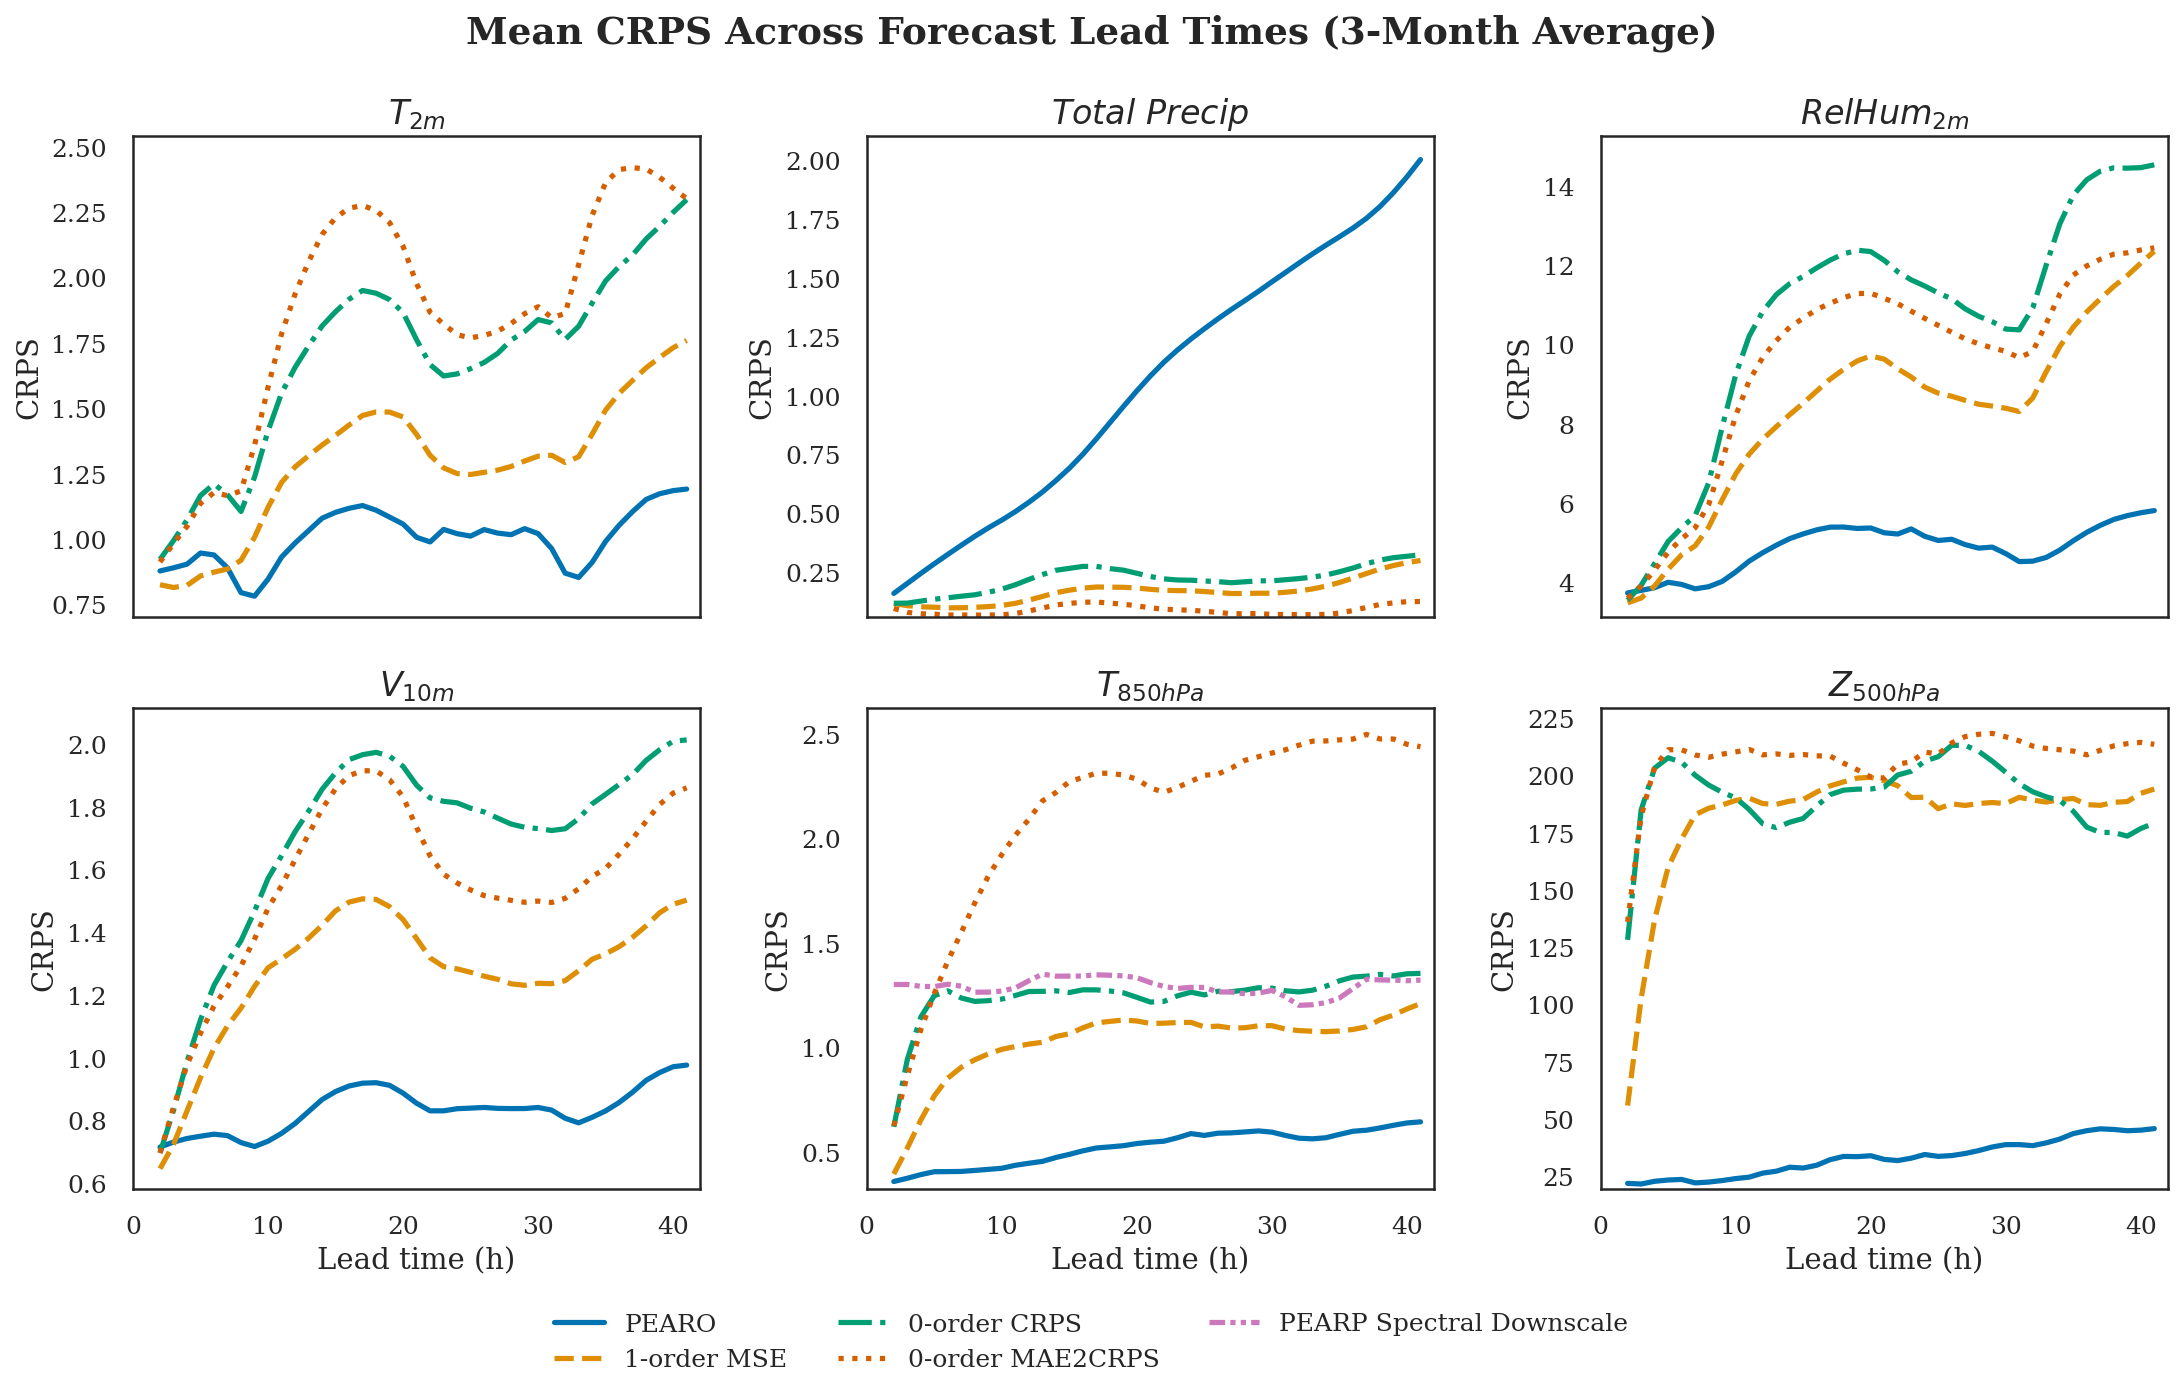

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$Total\ Precip$", 
    r"$RelHum_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure
# ---------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):
    ax = axes.flat[i]

    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_poesy/pearo_crps_plot_per_param_{var}.npy")
    mse_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_poesy/preds_crps_plot_per_param_{var}.npy")
    crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/test_poesy/preds_crps_plot_per_param_{var}.npy")
    mae2crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/test_poesy/preds_crps_plot_per_param_{var}.npy")

    lines = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mse_1order, "1-order MSE", palette[1], linestyles[1]),
        (crps_0order, "0-order CRPS", palette[2], linestyles[2]),
        (mae2crps_0order, "0-order MAE2CRPS", palette[3], linestyles[3]),
    ]

    # Add optional extra model for specific variable
    if var == "pearo_t_850hpa":
        mse_PEARP_spectralDS = np.load(
            f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/preds_crps_plot_per_param_{var}.npy"
        )[:-1]
        lines.append((mse_PEARP_spectralDS, "PEARP Spectral Downscale", palette[4], linestyles[4]))

    # Plot all models for this variable
    for data, label, color, style in lines:
        sns.lineplot(x=lead_times[:len(data)], y=data,
                     label=label, color=color, linestyle=style,
                     linewidth=2.5, ax=ax)

    # Aesthetics
    ax.set_title(var_name[i], weight="bold")
    ax.set_xlabel("Lead time (h)")
    ax.set_ylabel("CRPS")
    ax.grid(False)
    ax.set_xlim(0, 42)
    ax.tick_params(width=1.2)

    # Adjust y-limits per subplot
    ymin = min([np.min(d) for d, *_ in lines]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines]) * 1.05
    ax.set_ylim(ymin, ymax)

    # Capture legend handles
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ---------------------------
# Global labels and layout
# ---------------------------
fig.suptitle("Mean CRPS Across Forecast Lead Times (3-Month Average)", fontsize=18, weight="bold", y=1.02)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.15, top=0.93)

# ---------------------------
# Save high-quality figure
# ---------------------------
plt.savefig("CRPS_leadtime_comparison.png", bbox_inches="tight", dpi=300)
# plt.savefig("CRPS_leadtime_comparison.pdf", bbox_inches="tight")

plt.show()


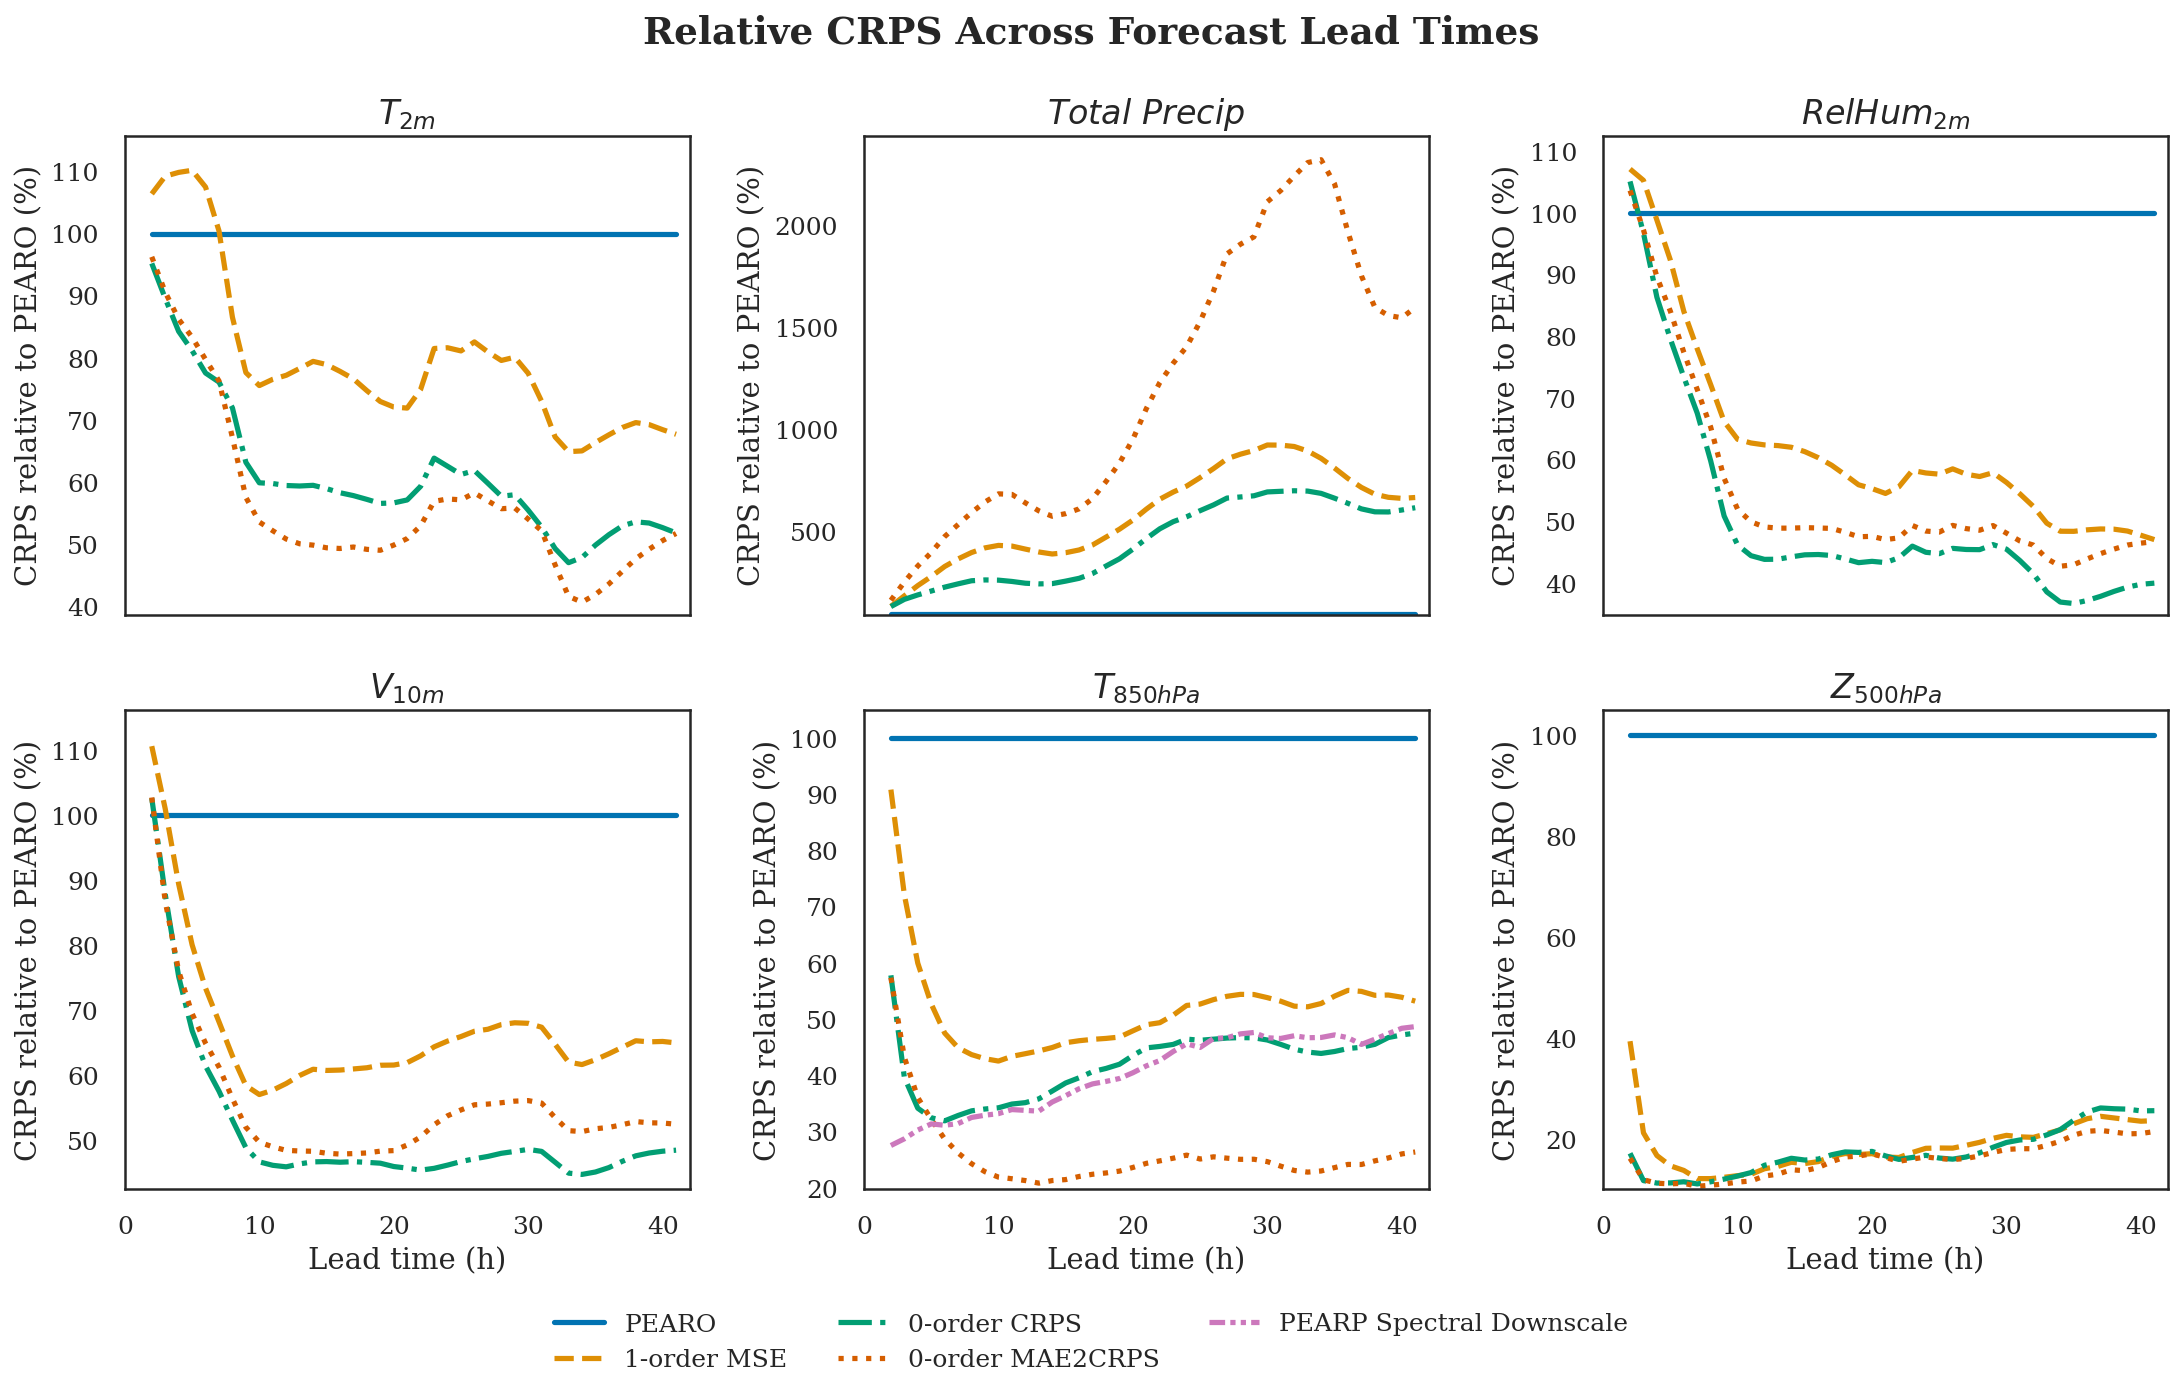

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$Total\ Precip$", 
    r"$RelHum_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure
# ---------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop (relative values)
# ---------------------------
for i, var in enumerate(vars):
    ax = axes.flat[i]

    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_poesy/pearo_crps_plot_per_param_{var}.npy")
    mse_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_poesy/preds_crps_plot_per_param_{var}.npy")
    crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/test_poesy/preds_crps_plot_per_param_{var}.npy")
    mae2crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/test_poesy/preds_crps_plot_per_param_{var}.npy")

    # Convert to relative values (% of baseline poesy)
    mse_1order_rel = (poesy / mse_1order) * 100
    crps_0order_rel = (poesy / crps_0order) * 100
    mae2crps_0order_rel = (poesy / mae2crps_0order) * 100
    poesy_rel = np.ones_like(poesy) * 100  # baseline at 100%

    lines = [
        (poesy_rel, "PEARO", palette[0], linestyles[0]),
        (mse_1order_rel, "1-order MSE", palette[1], linestyles[1]),
        (crps_0order_rel, "0-order CRPS", palette[2], linestyles[2]),
        (mae2crps_0order_rel, "0-order MAE2CRPS", palette[3], linestyles[3]),
    ]

    # Optional extra model for specific variable
    if var == "pearo_t_850hpa":
        mse_PEARP_spectralDS = np.load(
            f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/preds_crps_plot_per_param_{var}.npy"
        )[:-1]
        mse_PEARP_spectralDS_rel = (poesy[:len(mse_PEARP_spectralDS)] / mse_PEARP_spectralDS) * 100
        lines.append((mse_PEARP_spectralDS_rel, "PEARP Spectral Downscale", palette[4], linestyles[4]))

    # Plot all models for this variable
    for data, label, color, style in lines:
        sns.lineplot(x=lead_times[:len(data)], y=data,
                     label=label, color=color, linestyle=style,
                     linewidth=2.5, ax=ax)

    # Aesthetics
    ax.set_title(var_name[i], weight="bold")
    ax.set_xlabel("Lead time (h)")
    ax.set_ylabel("CRPS relative to PEARO (%)")
    ax.grid(False)
    ax.set_xlim(0, 42)
    ax.tick_params(width=1.2)

    # Adjust y-limits per subplot
    ymin = min([np.min(d) for d, *_ in lines]) * 0.95
    ymax = max([np.max(d) for d, *_ in lines]) * 1.05
    ax.set_ylim(ymin, ymax)

    # Capture legend handles
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ---------------------------
# Global labels and layout
# ---------------------------
fig.suptitle("Relative CRPS Across Forecast Lead Times", fontsize=18, weight="bold", y=1.02)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.15, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("CRPS_leadtime_relative_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


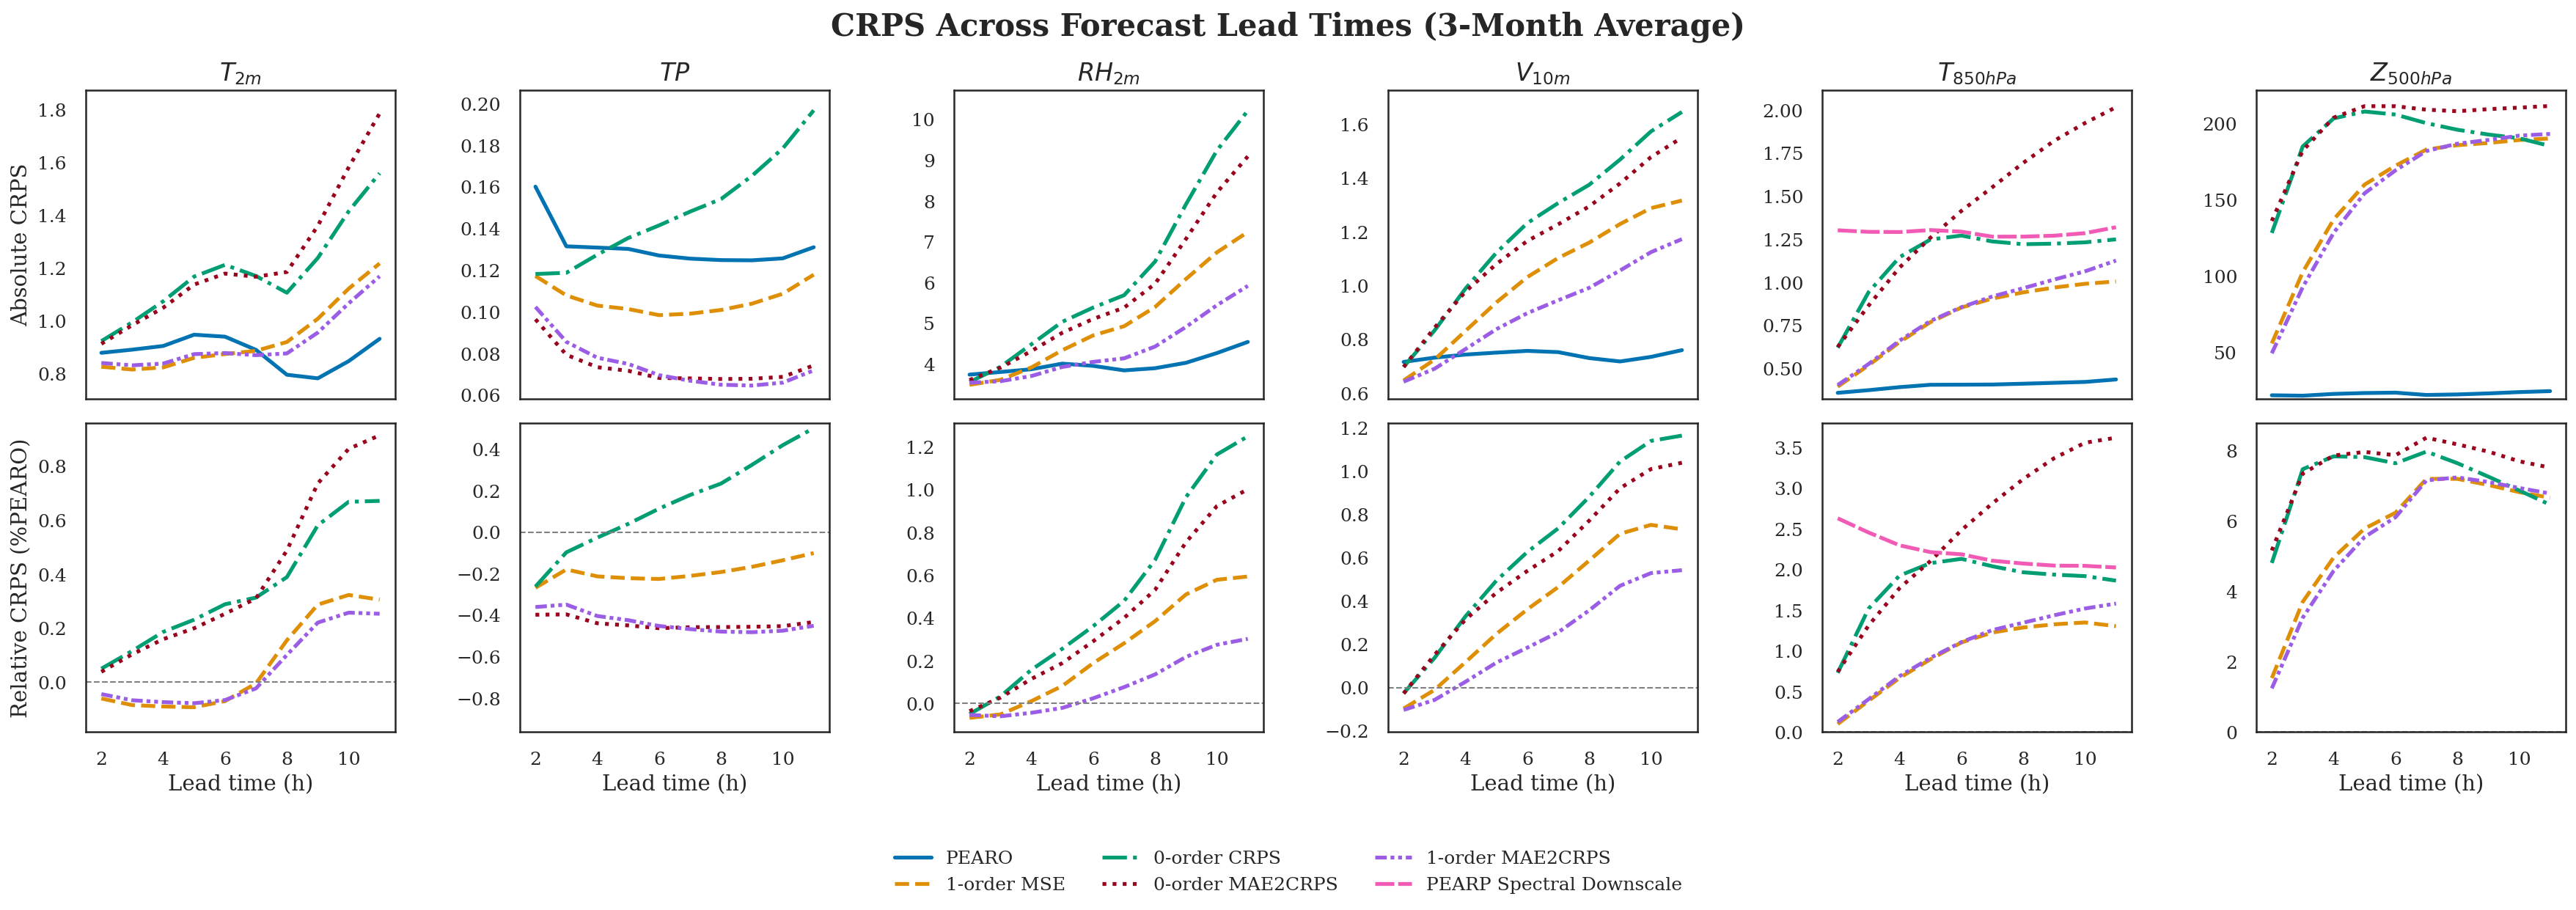

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$TP$", 
    r"$RH_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

# lead_times = np.arange(2, 42)
lead_times = np.arange(2, 12)

# ---------------------------
# Create figure: 2 rows x 6 cols
# ---------------------------
fig, axes = plt.subplots(2, 6, figsize=(24, 8), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):
    # Top row: absolute CRPS
    ax_abs = axes[0, i]
    
    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran/pearo_crps_plot_per_param_{var}.npy")[:10]
    mse_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_poesy/preds_crps_plot_per_param_{var}.npy")[:10]
    crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/test_poesy/preds_crps_plot_per_param_{var}.npy")[:10]
    mae2crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/test_poesy/preds_crps_plot_per_param_{var}.npy")[:10]
    mae2crps_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran/preds_crps_plot_per_param_{var}.npy")[:10]

    
    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mse_1order, "1-order MSE", palette[1], linestyles[1]),
        (crps_0order, "0-order CRPS", palette[2], linestyles[2]),
        (mae2crps_0order, "0-order MAE2CRPS", "#9a031e", linestyles[3]),
        (mae2crps_1order, "1-order MAE2CRPS", "#9b5de5", linestyles[5]), 
    ]
    
    if var == "pearo_t_850hpa":
        mse_PEARP_spectralDS = np.load(
            f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/preds_crps_plot_per_param_{var}.npy"
        )[1:11]
        lines_abs.append((mse_PEARP_spectralDS, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))
    
    for data, label, color, style in lines_abs:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_abs)
    
    ax_abs.set_title(var_name[i], weight="bold")
    ax_abs.set_xlabel("Lead time (h)")
    ax_abs.set_ylabel("Absolute CRPS")
    ax_abs.grid(False)
    # ax_abs.set_xlim(0, 42)
    ax_abs.set_xlim(1.5, 11.5)
    ymin = min([np.min(d) for d, *_ in lines_abs]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines_abs]) * 1.05
    ax_abs.set_ylim(ymin, ymax)
    
    # Capture legend from the top row
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax_abs.get_legend_handles_labels()
    ax_abs.get_legend().remove()
    
    # Bottom row: relative CRPS
    ax_rel = axes[1, i]
    
    # Convert to relative (% of baseline poesy)
    mse_1order_rel = (mse_1order - poesy) / poesy 
    crps_0order_rel = (crps_0order - poesy) / poesy 
    mae2crps_0order_rel = (mae2crps_0order - poesy) / poesy 
    mae2crps_1order_rel = (mae2crps_1order - poesy) / poesy 
    
    lines_rel = [
        (mse_1order_rel, "1-order MSE", palette[1], linestyles[1]),
        (crps_0order_rel, "0-order CRPS", palette[2], linestyles[2]),
        (mae2crps_0order_rel, "0-order MAE2CRPS", "#9a031e", linestyles[3]),
        (mae2crps_1order_rel, "1-order MAE2CRPS", "#9b5de5", linestyles[5]),
    ]
    
    if var == "pearo_t_850hpa":
        mse_PEARP_spectralDS_rel =  (mse_PEARP_spectralDS - poesy[:len(mse_PEARP_spectralDS)]) / poesy[:len(mse_PEARP_spectralDS)]
        lines_rel.append((mse_PEARP_spectralDS_rel, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))
    
    for data, label, color, style in lines_rel:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_rel)
    
    ax_rel.set_title(var_name[i], weight="bold")
    ax_rel.set_xlabel("Lead time (h)")
    ax_rel.set_ylabel("Relative CRPS (%PEARO)")
    ax_rel.grid(False)
    # ax_rel.set_xlim(0, 42)
    ax_rel.set_xlim(1.5, 11.5)
    ymin = min(min([np.min(d) for d, *_ in lines_rel]), 0) * 2
    ymax = max(max([np.max(d) for d, *_ in lines_rel]), 0) * 1.05
    ax_rel.set_ylim(ymin, ymax)
    ax_rel.get_legend().remove()
    # Optional: add horizontal line at 100% in relative plots
    ax_rel.axhline(0, color="gray", linestyle="--", linewidth=1)


for ax_row in axes:
    for ax in ax_row:
        ax.set_aspect(aspect='auto')  # 'equal' can be too extreme for line plots
        ax.set_box_aspect(1)

# Keep only y-labels on the first column
for row in axes:
    for j, ax in enumerate(row):
        if j != 0:
            ax.set_ylabel("")
# Keep titles only on first (top) row
for j in range(6):
    axes[1, j].set_title("")  # remove title from second row



# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle("CRPS Across Forecast Lead Times (3-Month Average)", fontsize=20, weight="bold", y=1.02)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.2, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
#plt.savefig("CRPS_absolute_relative_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


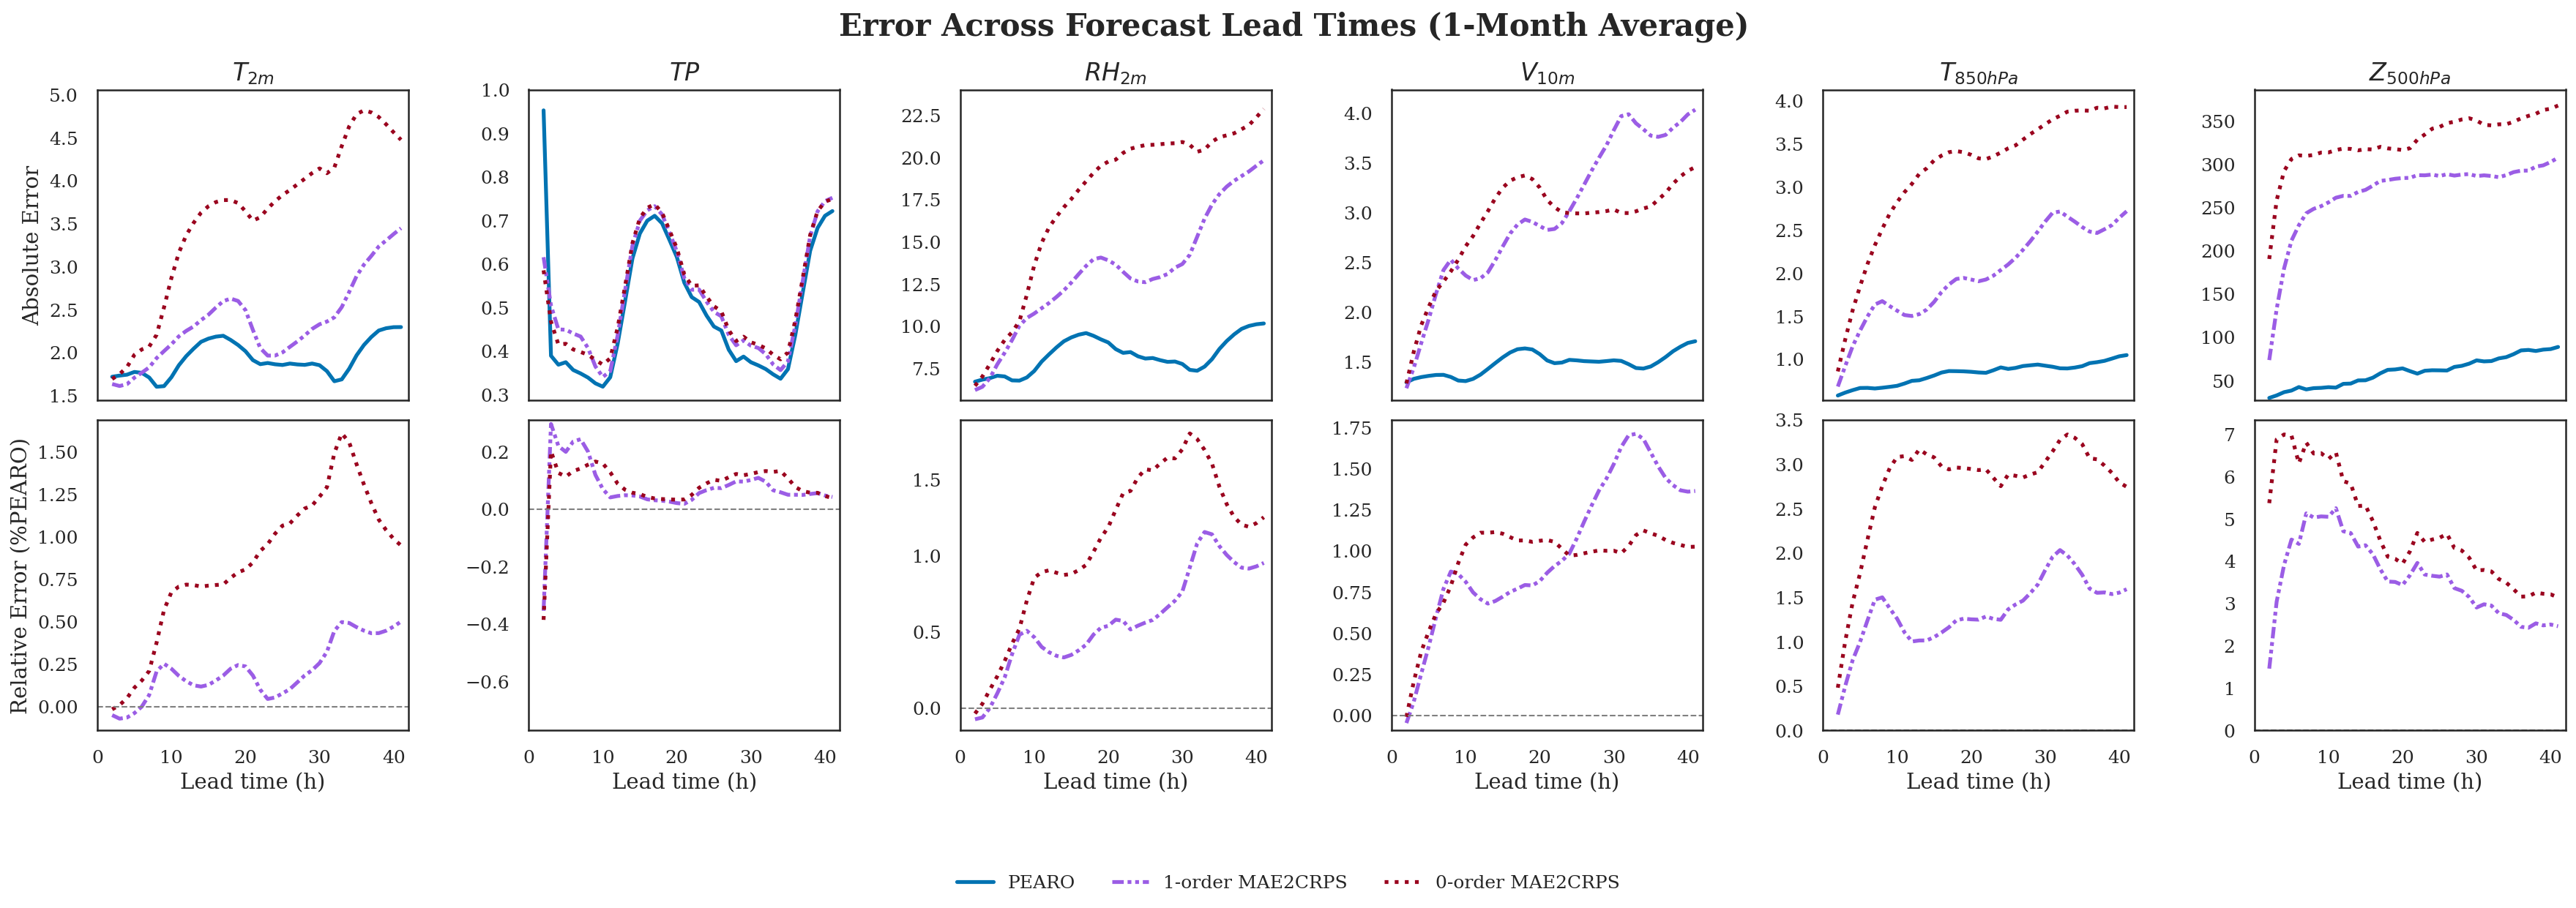

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$TP$", 
    r"$RH_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 2 rows x 6 cols
# ---------------------------
fig, axes = plt.subplots(2, 6, figsize=(24, 8), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):
    # Top row: absolute CRPS
    ax_abs = axes[0, i]
    
    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/pearo_error_plot_per_param_{var}.npy")
    # mse_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")
    # crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")
    mae2crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")
    mae2crps_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/preds_error_plot_per_param_{var}.npy")

    
    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mae2crps_1order, "1-order MAE2CRPS", "#9b5de5", linestyles[5]),
        (mae2crps_0order, "0-order MAE2CRPS", "#9a031e", linestyles[3])]

    #     (mse_1order, "1-order MSE", palette[1], linestyles[1]),
    #     (crps_0order, "0-order CRPS", palette[2], linestyles[2]),
    #     ,
        
    # ]
    
    # if var == "pearo_t_850hpa":
    #     mse_PEARP_spectralDS = np.load(
    #         f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/preds_error_plot_per_param_{var}.npy"
    #     )[1:]
    #     lines_abs.append((mse_PEARP_spectralDS, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))
    
    for data, label, color, style in lines_abs:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_abs)
    
    ax_abs.set_title(var_name[i], weight="bold")
    ax_abs.set_xlabel("Lead time (h)")
    ax_abs.set_ylabel("Absolute Error")
    ax_abs.grid(False)
    ax_abs.set_xlim(0, 42)
    ymin = min([np.min(d) for d, *_ in lines_abs]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines_abs]) * 1.05
    ax_abs.set_ylim(ymin, ymax)
    
    # Capture legend from the top row
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax_abs.get_legend_handles_labels()
    ax_abs.get_legend().remove()
    
    # Bottom row: relative CRPS
    ax_rel = axes[1, i]
    
    # Convert to relative (% of baseline poesy)
    mae2crps_1order_rel = (mae2crps_1order - poesy) / poesy 
    # mse_1order_rel = (mse_1order - poesy) / poesy 
    # crps_0order_rel = (crps_0order - poesy) / poesy 
    mae2crps_0order_rel = (mae2crps_0order - poesy) / poesy 
    
    
    lines_rel = [
        (mae2crps_1order_rel, "1-order MAE2CRPS", "#9b5de5", linestyles[5]),
        (mae2crps_0order_rel, "0-order MAE2CRPS", "#9a031e", linestyles[3])]

    #     (mse_1order_rel, "1-order MSE", palette[1], linestyles[1]),
    #     (crps_0order_rel, "0-order CRPS", palette[2], linestyles[2]),
    #     ,
        
    # ]
    
    # if var == "pearo_t_850hpa":
    #     mse_PEARP_spectralDS_rel =  (mse_PEARP_spectralDS - poesy[:len(mse_PEARP_spectralDS)]) / poesy[:len(mse_PEARP_spectralDS)]
    #     lines_rel.append((mse_PEARP_spectralDS_rel, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))
    
    for data, label, color, style in lines_rel:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_rel)
    
    ax_rel.set_title(var_name[i], weight="bold")
    ax_rel.set_xlabel("Lead time (h)")
    ax_rel.set_ylabel("Relative Error (%PEARO)")
    ax_rel.grid(False)
    ax_rel.set_xlim(0, 42)
    ymin = min(min([np.min(d) for d, *_ in lines_rel]), 0) * 2
    ymax = max(max([np.max(d) for d, *_ in lines_rel]), 0) * 1.05
    ax_rel.set_ylim(ymin, ymax)
    ax_rel.get_legend().remove()
    # Optional: add horizontal line at 100% in relative plots
    ax_rel.axhline(0, color="gray", linestyle="--", linewidth=1)


for ax_row in axes:
    for ax in ax_row:
        ax.set_aspect(aspect='auto')  # 'equal' can be too extreme for line plots
        ax.set_box_aspect(1)

# Keep only y-labels on the first column
for row in axes:
    for j, ax in enumerate(row):
        if j != 0:
            ax.set_ylabel("")
# Keep titles only on first (top) row
for j in range(6):
    axes[1, j].set_title("")  # remove title from second row



# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle("Error Across Forecast Lead Times (1-Month Average)", fontsize=20, weight="bold", y=1.02)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.2, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("Error_absolute_relative_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


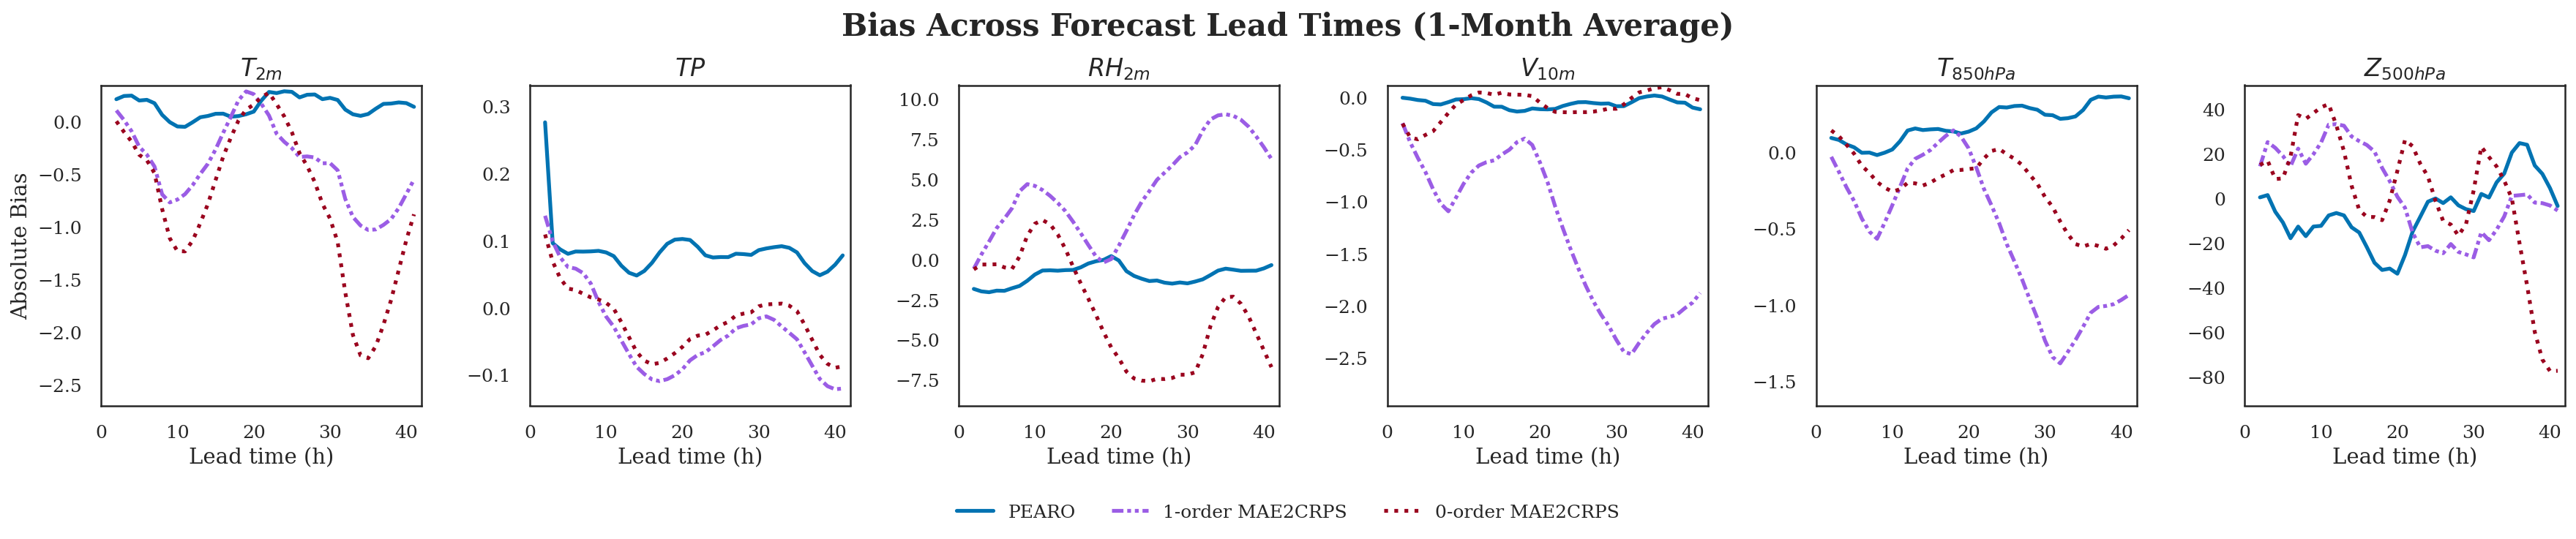

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$", 
    r"$TP$", 
    r"$RH_{2m}$",
    r"$V_{10m}$", 
    r"$T_{850hPa}$", 
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 1 row x 6 cols
# ---------------------------
fig, axes = plt.subplots(1, 6, figsize=(24, 4), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):

    ax = axes[i]

    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/pearo_bias_plot_per_param_{var}.npy")
    # mse_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")
    # crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")
    mae2crps_0order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")
    mae2crps_1order = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/preds_bias_plot_per_param_{var}.npy")

    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mae2crps_1order, "1-order MAE2CRPS", "#9b5de5", linestyles[5]),
        (mae2crps_0order, "0-order MAE2CRPS", "#9a031e", linestyles[3])
    ]
    #     (mse_1order, "1-order MSE", palette[1], linestyles[1]),
    #     (crps_0order, "0-order CRPS", palette[2], linestyles[2]),
        
    # ]
    
    # if var == "pearo_t_850hpa":
    #     mse_PEARP_spectralDS = np.load(
    #         f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/preds_bias_plot_per_param_{var}.npy"
    #     )[1:]
    #     lines_abs.append((mse_PEARP_spectralDS, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))

    # Plot curves
    for data, label, color, style in lines_abs:
        sns.lineplot(
            x=lead_times[:len(data)], y=data,
            label=label, color=color, linestyle=style, linewidth=2.5, ax=ax
        )

    # Formatting
    ax.set_title(var_name[i], weight="bold")
    ax.set_xlabel("Lead time (h)")
    if i == 0:
        ax.set_ylabel("Absolute Bias")
    else:
        ax.set_ylabel("")

    ax.grid(False)
    ax.set_xlim(0, 42)
    
    ymax = max(max([np.max(d) for d, *_ in lines_abs]),0) *1.2
    ymin = min(min([np.min(d) for d, *_ in lines_abs]),0) *1.2
    
    ax.set_ylim(ymin, ymax)

    # Capture legend once
    if handles is None and var == "pearo_t2m_2m":
        handles, labels = ax.get_legend_handles_labels()

    ax.get_legend().remove()
    ax.set_aspect(aspect='auto')
    ax.set_box_aspect(1)

# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle("Bias Across Forecast Lead Times (1-Month Average)", fontsize=20, weight="bold", y=1.1)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12, bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.subplots_adjust(bottom=0.2, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("Error_absolute_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


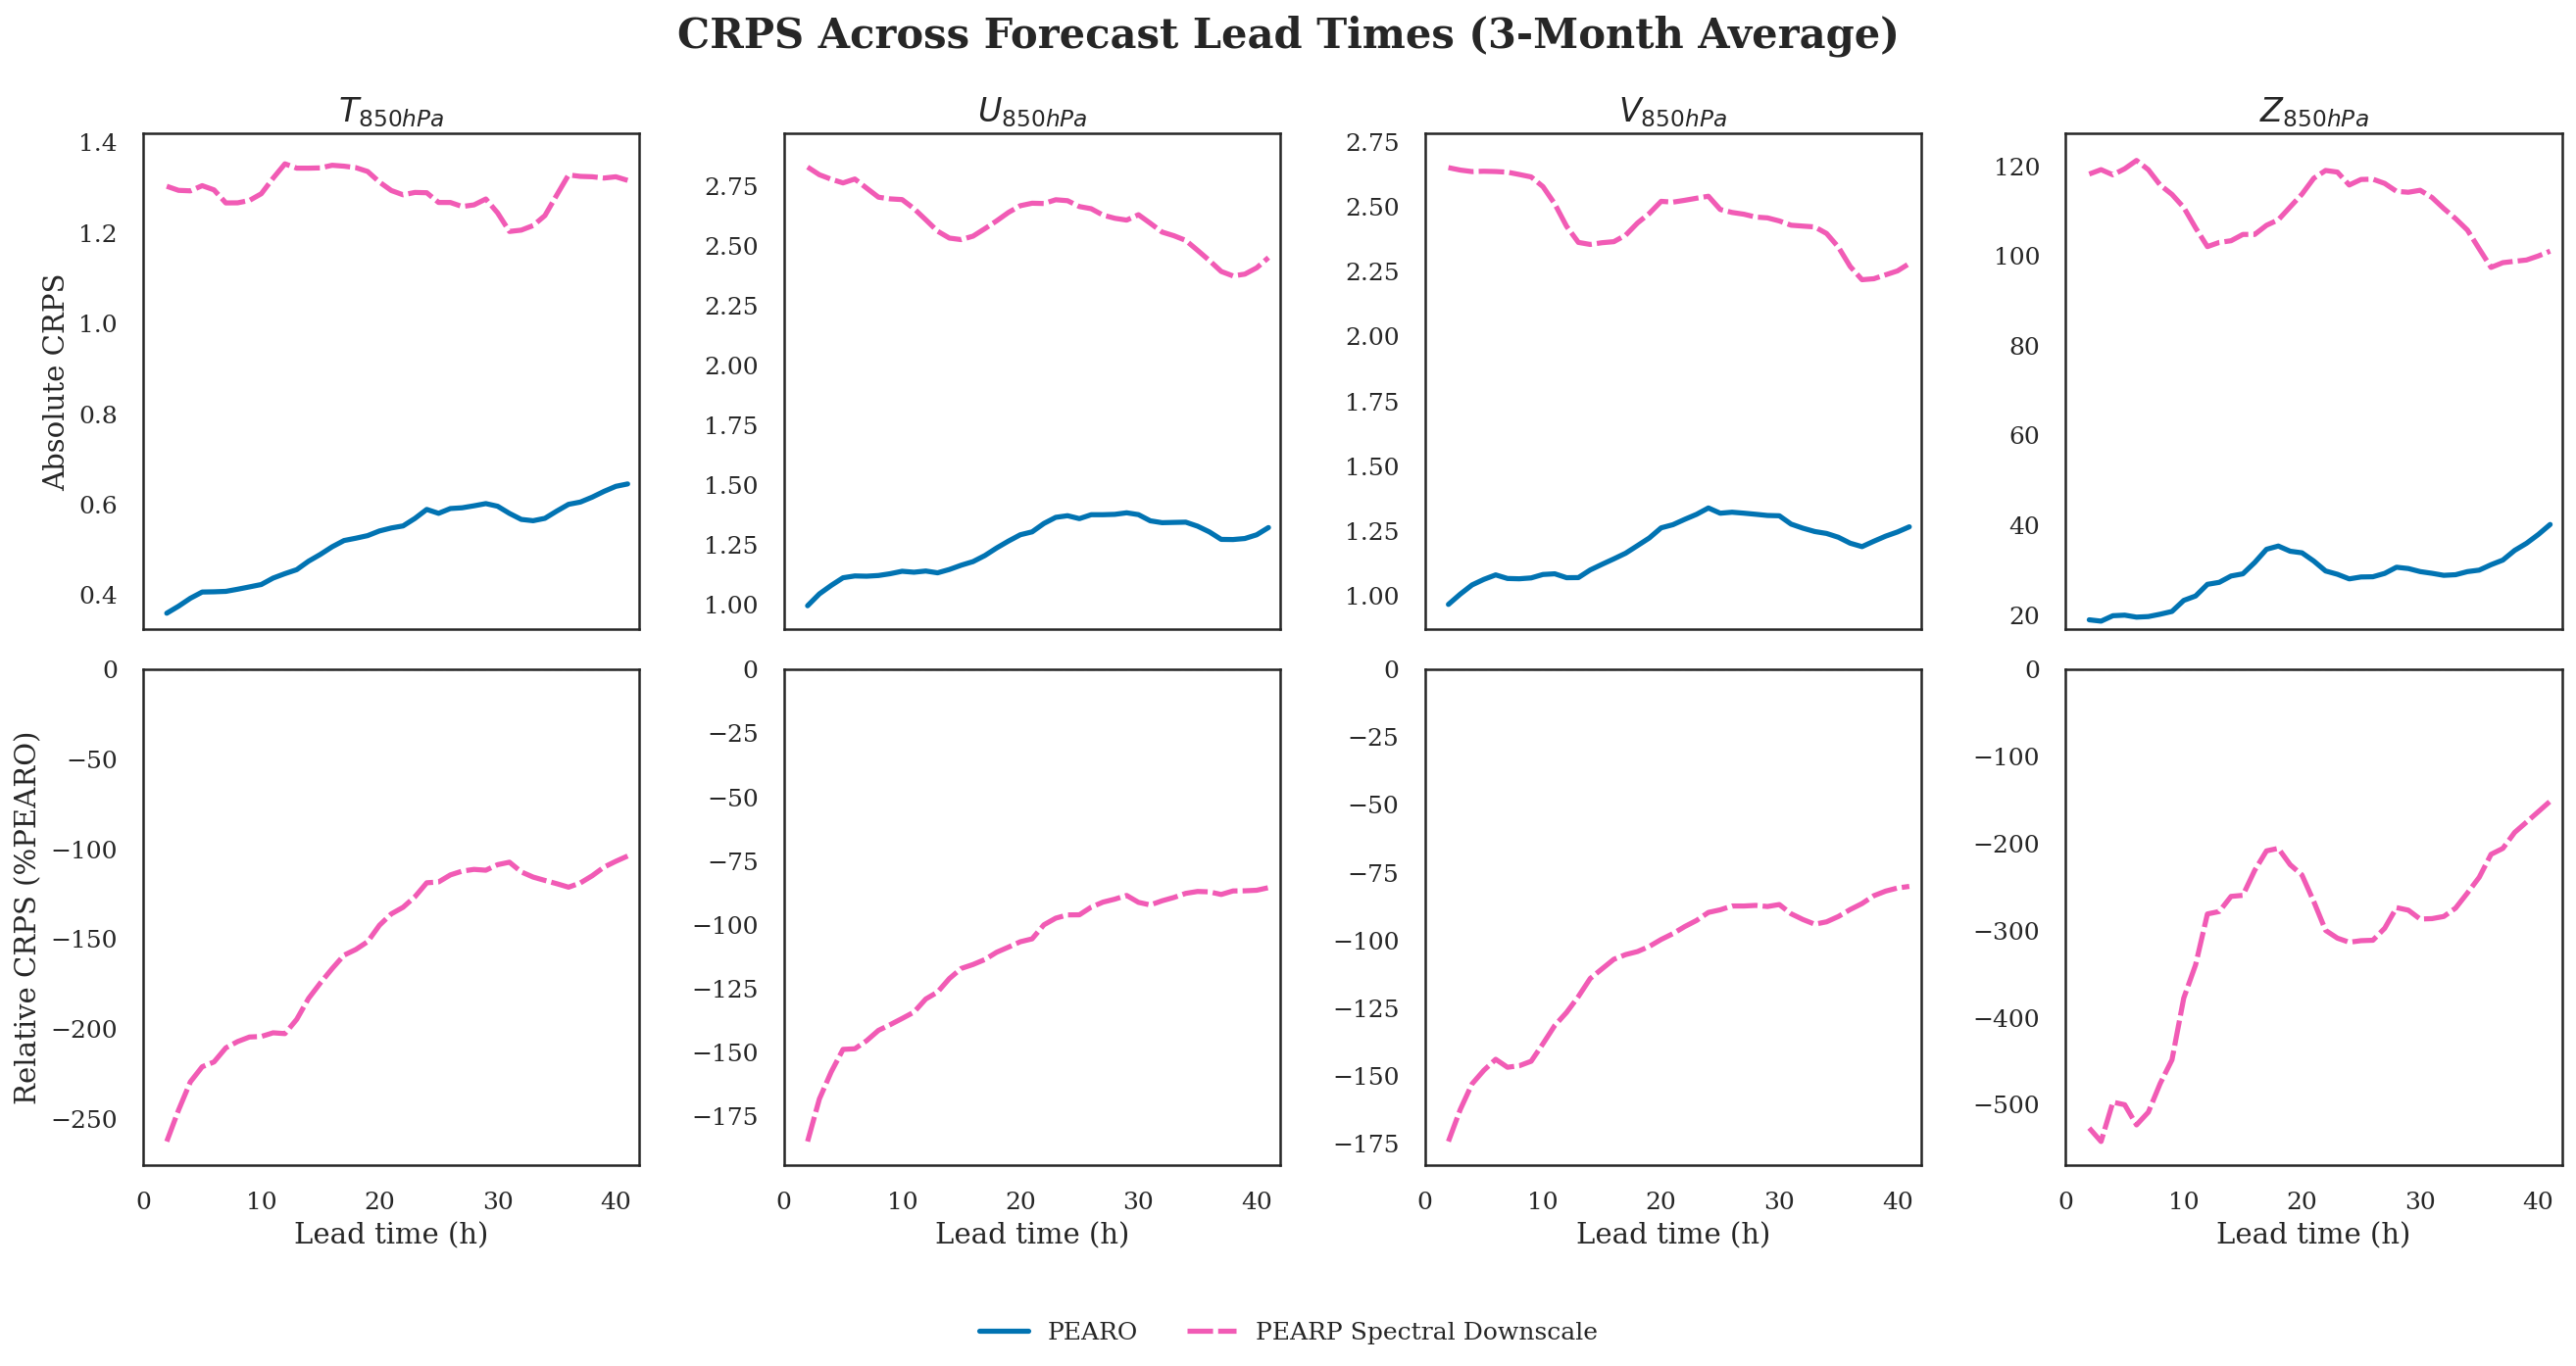

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t_850hpa", "pearo_u_850hpa", "pearo_v_850hpa", "pearo_z_850hpa"]

var_name = [
    r"$T_{850hPa}$",
    r"$U_{850hPa}$",
    r"$V_{850hPa}$",
    r"$Z_{850hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 2 rows x 6 cols
# ---------------------------
fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharex=True)
handles, labels = None, None

# ---------------------------
# Plot loop
# ---------------------------
for i, var in enumerate(vars):
    # Top row: absolute CRPS
    ax_abs = axes[0, i]
    
    # Load data
    poesy = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/pearo_crps_plot_per_param_{var}.npy")[1:]
    mse_PEARP_spectralDS = np.load(f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/preds_crps_plot_per_param_{var}.npy")[1:]

    
    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mse_PEARP_spectralDS, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]),
    ]
    
    for data, label, color, style in lines_abs:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_abs)
    
    ax_abs.set_title(var_name[i], weight="bold")
    ax_abs.set_xlabel("Lead time (h)")
    ax_abs.set_ylabel("Absolute CRPS")
    ax_abs.grid(False)
    ax_abs.set_xlim(0, 42)
    ymin = min([np.min(d) for d, *_ in lines_abs]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines_abs]) * 1.05
    ax_abs.set_ylim(ymin, ymax)
    
    # Capture legend from the top row
    handles, labels = ax_abs.get_legend_handles_labels()
    ax_abs.get_legend().remove()
    
    # Bottom row: relative CRPS
    ax_rel = axes[1, i]
    
    # Convert to relative (% of baseline poesy)

    mse_PEARP_spectralDS_rel = ((poesy - mse_PEARP_spectralDS) / poesy) * 100
    lines_rel = [
        (mse_PEARP_spectralDS_rel, "PEARP Spectral Downscale", "#f15bb5", linestyles[4])
    ]
    
    for data, label, color, style in lines_rel:
        sns.lineplot(x=lead_times[:len(data)], y=data, label=label, color=color, linestyle=style, linewidth=2.5, ax=ax_rel)
    
    ax_rel.set_title(var_name[i], weight="bold")
    ax_rel.set_xlabel("Lead time (h)")
    ax_rel.set_ylabel("Relative CRPS (%PEARO)")
    ax_rel.grid(False)
    ax_rel.set_xlim(0, 42)
    ymin = min(min([np.min(d) for d, *_ in lines_rel]), 0) * 1.05
    ymax = max(max([np.max(d) for d, *_ in lines_rel]), 0) * 2
    ax_rel.set_ylim(ymin, ymax)
    ax_rel.get_legend().remove()
    # Optional: add horizontal line at 100% in relative plots
    ax_rel.axhline(0, color="gray", linestyle="--", linewidth=1)


for ax_row in axes:
    for ax in ax_row:
        ax.set_aspect(aspect='auto')  # 'equal' can be too extreme for line plots
        ax.set_box_aspect(1)

# Keep only y-labels on the first column
for row in axes:
    for j, ax in enumerate(row):
        if j != 0:
            ax.set_ylabel("")
# Keep titles only on first (top) row
for j in range(4):
    axes[1, j].set_title("")  # remove title from second row



# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle("CRPS Across Forecast Lead Times (3-Month Average)", fontsize=20, weight="bold", y=1.02)
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.15, top=0.93)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("CRPS_ARPds_absolute_relative_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


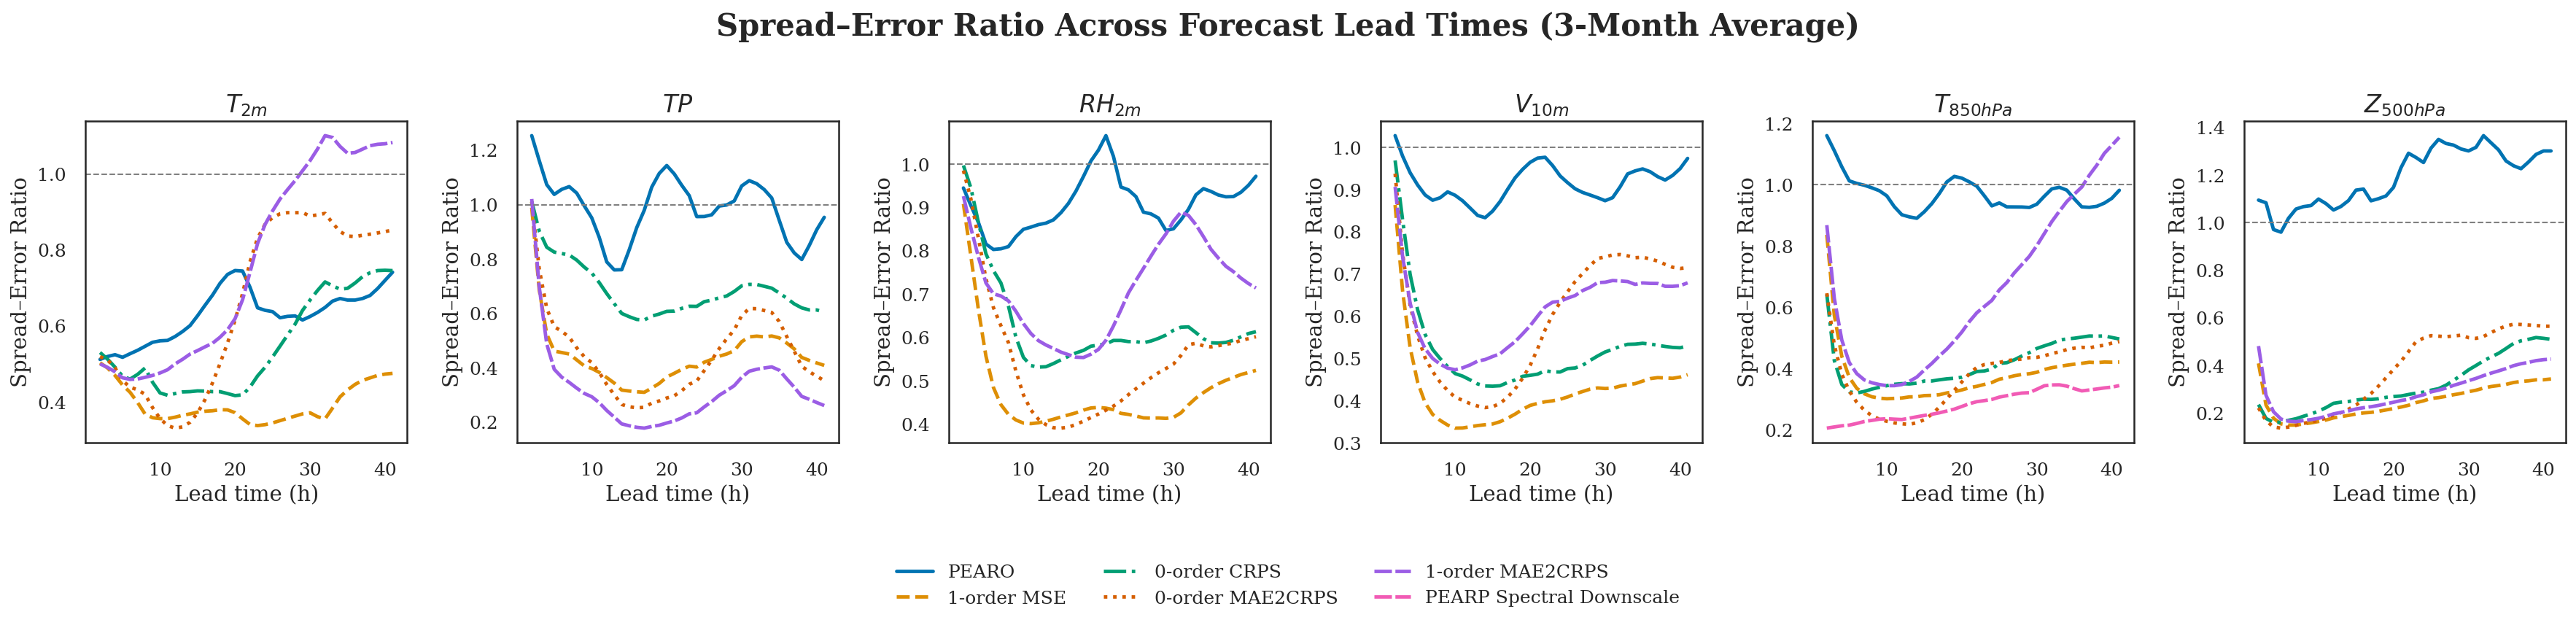

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetics
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = [
    "pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
    "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"
]

var_name = [
    r"$T_{2m}$", r"$TP$", r"$RH_{2m}$",
    r"$V_{10m}$", r"$T_{850hPa}$", r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]
lead_times = np.arange(2, 42)

# ---------------------------
# Paths to each model
# ---------------------------
model_paths = {
    "PEARO": (
        "titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran",
        "pearo"   # ❗ special prefix
    ),
    "1-order MSE": (
        "titan_21var/base_1order_5em4/test_poesy",
        "preds"
    ),
    "0-order CRPS": (
        "titan_21var/crps_0order_5em4_2M_2BS/test_poesy",
        "preds"
    ),
    "0-order MAE2CRPS": (
        "titan_21var/mae2crps_0order_5em4_2M_2BS/test_poesy",
        "preds"
    ),
    "1-order MAE2CRPS": (
        "titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran",
        "preds"
    )
}

# Only applies to T850
special_downscale_model = (
    "titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy",
    "preds"
)

# ---------------------------
# Helper: loads correct filename depending on model
# ---------------------------
def load_var(base_path, prefix, var):
    return np.load(
        f"/scratch/audrena/py4cast_expe/{base_path}/{prefix}_spread_error_ratio_plot_per_param_{var}.npy"
    )

# ---------------------------
# Create figure
# ---------------------------
fig, axes = plt.subplots(1, 6, figsize=(24, 8))
legend_handles = legend_labels = None

for i, (var, vname) in enumerate(zip(vars, var_name)):

    ax = axes[i]
    lines = []

    # Load standard models
    for (label, (path, prefix)), color, ls in zip(model_paths.items(), palette, linestyles):
        data = load_var(path, prefix, var)
        if label == "1-order MAE2CRPS":
            color = "#9b5de5"  # custom color
        lines.append((label, data, color, ls))

    # Add downscale model for T850 only
    if var == "pearo_t_850hpa":
        path, prefix = special_downscale_model
        data = load_var(path, prefix, var)[1:]  # original slicing preserved
        lines.append(("PEARP Spectral Downscale", data, "#f15bb5", linestyles[4]))

    # Plot all lines
    for label, data, color, ls in lines:
        sns.lineplot(
            x=lead_times[:len(data)],
            y=data,
            ax=ax,
            label=label,
            color=color,
            linestyle=ls,
            linewidth=2.3
        )

    ax.set_title(vname, weight="bold")
    ax.set_xlabel("Lead time (h)")
    ax.set_ylabel("Spread–Error Ratio")
    ax.axhline(1, color="gray", ls="--", lw=1)
    ax.set_box_aspect(1)      # ← PERFECTLY SQUARE SUBPLOTS

    # Save legend reference once
    if legend_handles is None and var == "pearo_t_850hpa":
        legend_handles, legend_labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ---------------------------
# Global layout
# ---------------------------
fig.suptitle(
    "Spread–Error Ratio Across Forecast Lead Times (3-Month Average)",
    fontsize=20, weight="bold", y=0.9
)

fig.legend(
    legend_handles, legend_labels,
    loc="lower center", ncol=3, frameon=False, fontsize=12, bbox_to_anchor=(0.5, 0.2),
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.30, top=0.88)

plt.savefig("spread_error_ratio.png",
            dpi=300, bbox_inches="tight")
plt.show()


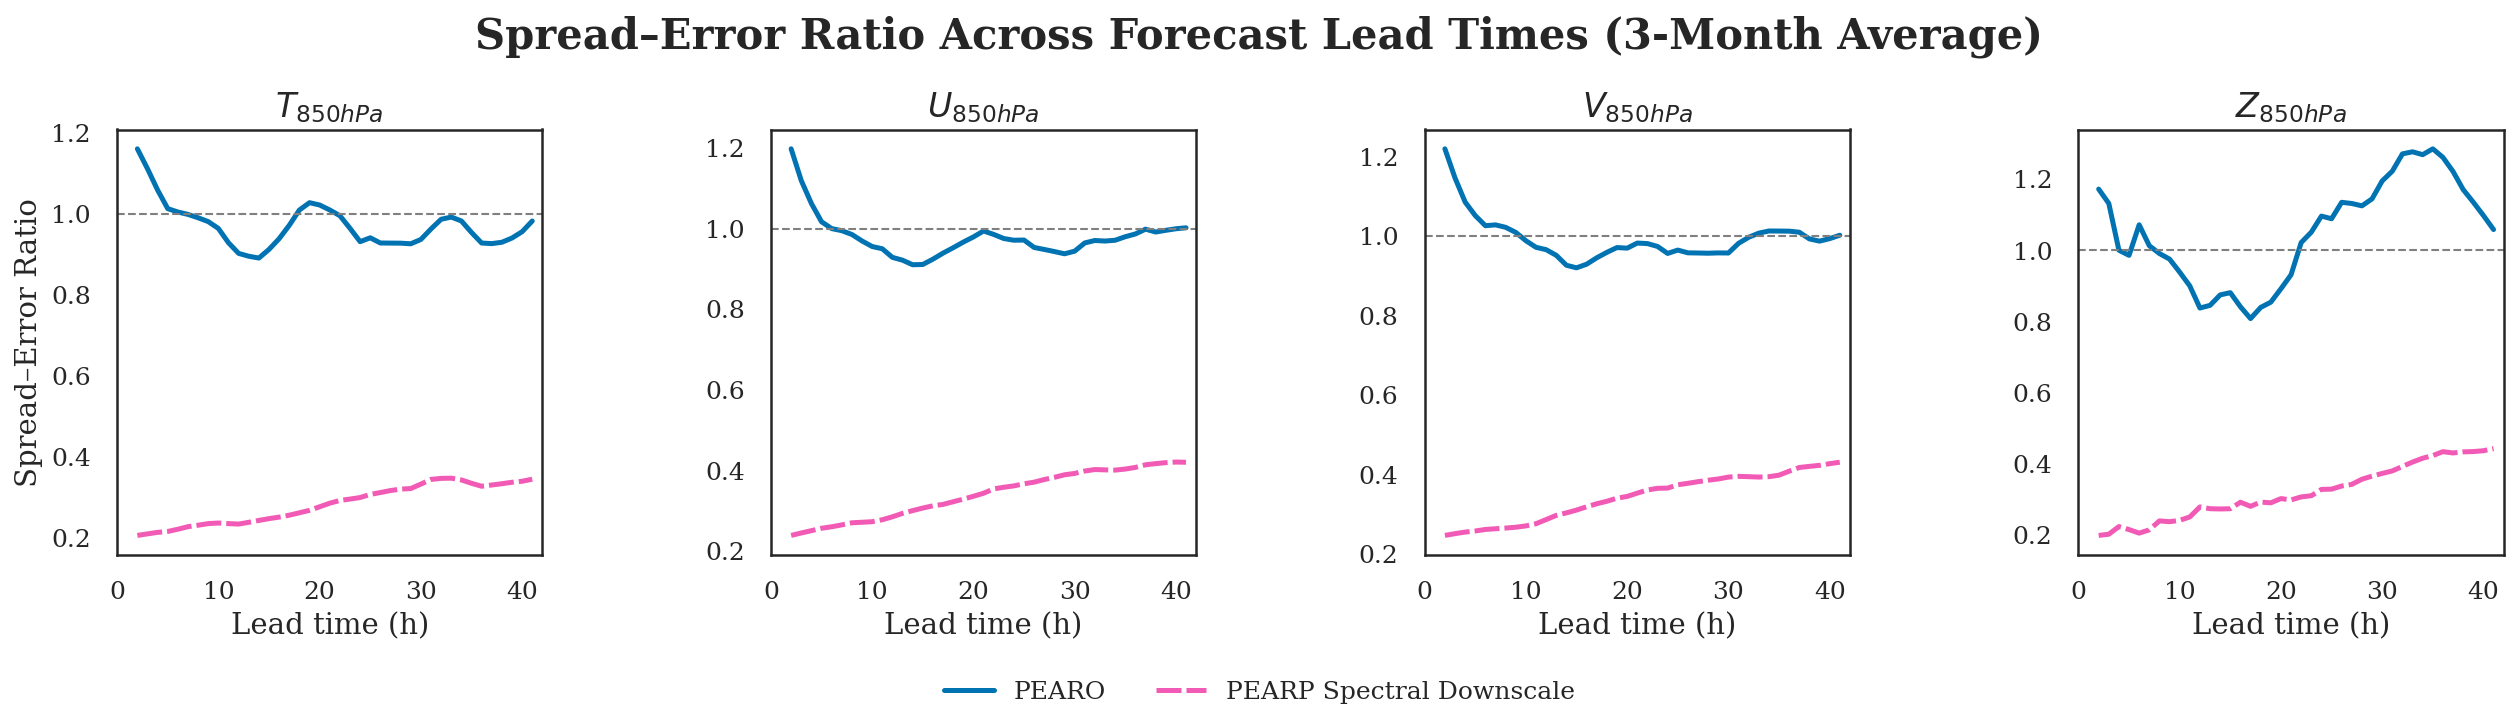

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetics
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables
# ---------------------------
vars = ["pearo_t_850hpa", "pearo_u_850hpa", "pearo_v_850hpa", "pearo_z_850hpa"]
var_name = [r"$T_{850hPa}$", r"$U_{850hPa}$", r"$V_{850hPa}$", r"$Z_{850hPa}$"]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Paths (PEARO vs PEARP-SDS)
# ---------------------------
path_pearo = "titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy"
path_pearp = "titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy"

# ---------------------------
# Helper loader
# ---------------------------
def load_var(path, prefix, var):
    return np.load(
        f"/scratch/audrena/py4cast_expe/{path}/{prefix}_spread_error_ratio_plot_per_param_{var}.npy"
    )[1:]

# ---------------------------
# Figure: 1 row × 4 columns
# ---------------------------
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

legend_handles = legend_labels = None

# ---------------------------
# Plot loop (ABSOLUTE ONLY)
# ---------------------------
for i, (var, name) in enumerate(zip(vars, var_name)):

    ax = axes[i]

    # Load data
    poesy = load_var(path_pearo, "pearo", var)
    pearp_ds = load_var(path_pearp, "preds", var)

    # Lines to plot
    abs_lines = [
        ("PEARO", poesy, palette[0], linestyles[0]),
        ("PEARP Spectral Downscale", pearp_ds, "#f15bb5", linestyles[4]),
    ]

    # Plot
    for label, data, color, ls in abs_lines:
        sns.lineplot(
            x=lead_times[:len(data)], y=data,
            ax=ax, label=label, color=color, linestyle=ls, linewidth=2.4
        )

    ax.set_title(name, weight="bold")
    ax.set_xlabel("Lead time (h)")
    ax.set_ylabel("Spread–Error Ratio")
    ax.set_xlim(0, 42)
    ax.axhline(1, color="gray", linestyle="--", linewidth=1)

    # Square subplots
    ax.set_box_aspect(1)

    # Capture legend once
    if legend_handles is None:
        legend_handles, legend_labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# Remove y-axis labels from all but the first subplot
for i in range(1, 4):
    axes[i].set_ylabel("")

# ---------------------------
# Layout
# ---------------------------
fig.suptitle(
    "Spread–Error Ratio Across Forecast Lead Times (3-Month Average)",
    fontsize=20, weight="bold", y=1.05
)

fig.legend(
    legend_handles, legend_labels,
    loc="lower center", ncol=2, frameon=False, fontsize=12
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.25, top=0.88)

plt.savefig("spread_error_ratio_ARPds.png",
            dpi=300, bbox_inches="tight")
plt.show()


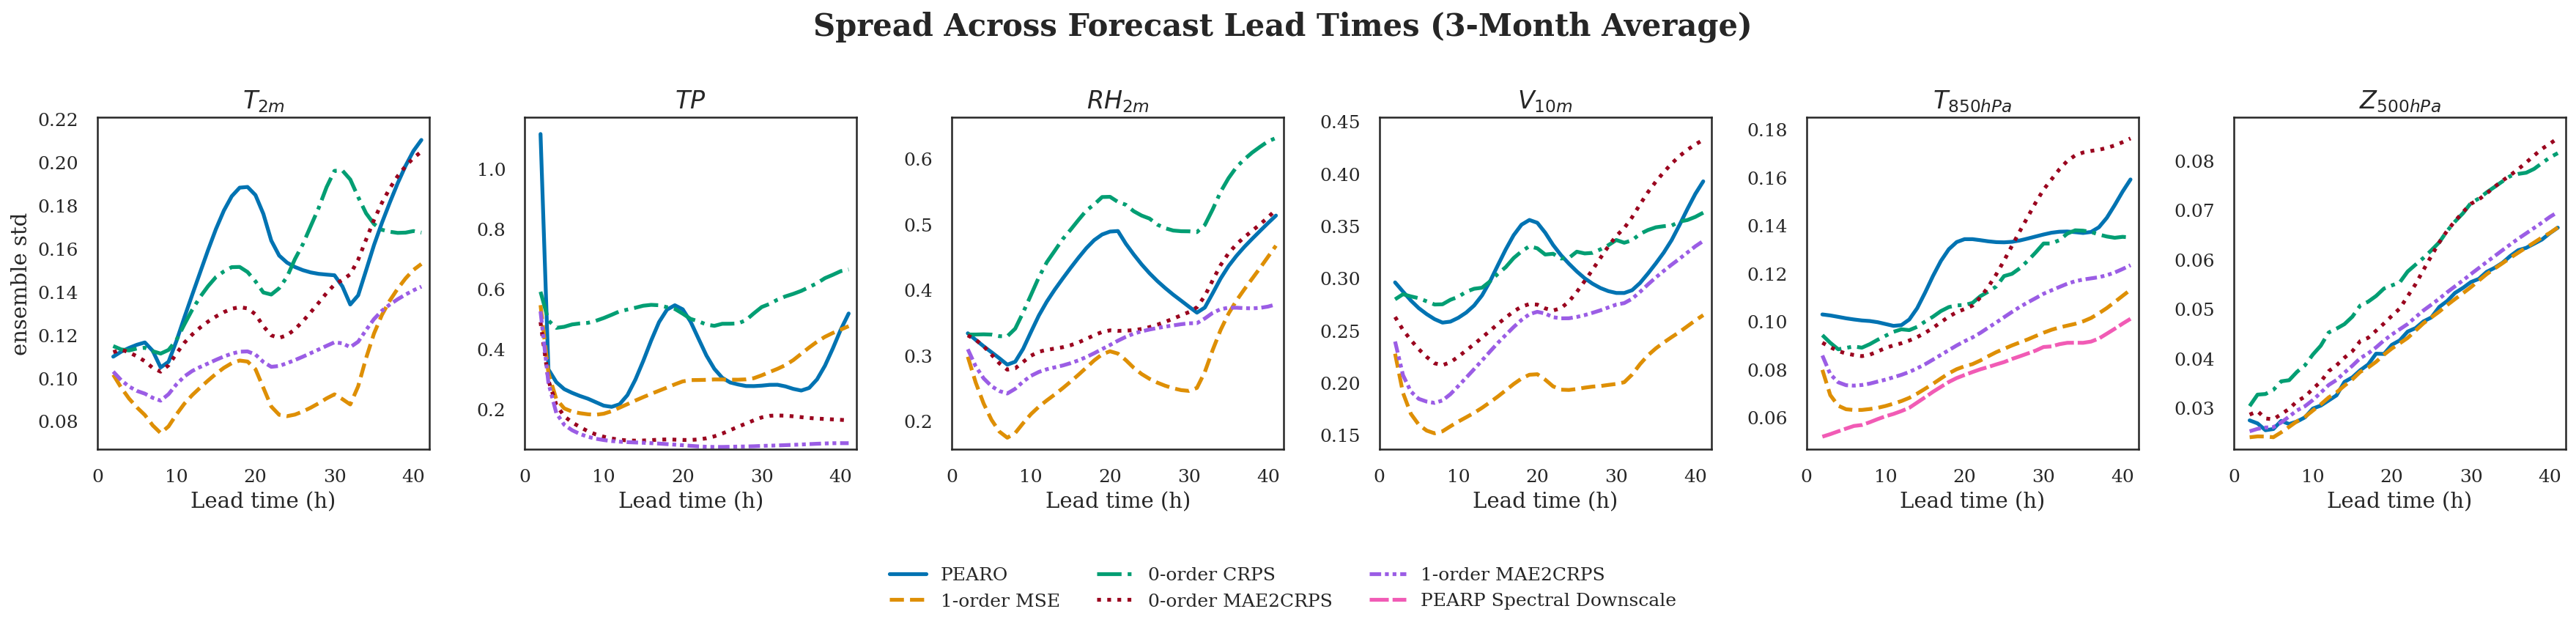

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$",
    r"$TP$",
    r"$RH_{2m}$",
    r"$V_{10m}$",
    r"$T_{850hPa}$",
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 1 row × 6 cols (ABSOLUTE ONLY)
# ---------------------------
fig, axes = plt.subplots(1, 6, figsize=(24, 8))
handles, labels = None, None

# ---------------------------
# Plot loop (ABSOLUTE ONLY)
# ---------------------------
for i, var in enumerate(vars):
    ax = axes[i]

    # Load data
    poesy_logdir = f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran/Test_std_timestep_{var}_poesy_refacto_EURW1S40_refacto/"
    poesy = SummaryReader(poesy_logdir).scalars['value']

    mse_1order = SummaryReader(f"/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_poesy/Test_std_timestep_{var}_preds").scalars['value']
    crps_0order = SummaryReader(f"/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/test_poesy/Test_std_timestep_{var}_preds").scalars['value']
    mae2crps_0order = SummaryReader(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/test_poesy/Test_std_timestep_{var}_preds").scalars['value']
    mae2crps_1order = SummaryReader(f"/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran/Test_std_timestep_{var}_preds").scalars['value']

    # Build absolute curve list
    lines_abs = [
        (poesy, "PEARO", palette[0], linestyles[0]),
        (mse_1order, "1-order MSE", palette[1], linestyles[1]),
        (crps_0order, "0-order CRPS", palette[2], linestyles[2]),
        (mae2crps_0order, "0-order MAE2CRPS", "#9a031e", linestyles[3]),
        (mae2crps_1order, "1-order MAE2CRPS", "#9b5de5", linestyles[5]),
    ]

    # Add PEARP Spectral Downscale only for 850hPa Temp
    if var == "pearo_t_850hpa":
        ds_logdir = f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/Test_std_timestep_{var}_preds"
        mse_PEARP_spectralDS = SummaryReader(ds_logdir).scalars['value'][1:]
        lines_abs.append((mse_PEARP_spectralDS, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))

    # Plot absolute
    for data, label, color, style in lines_abs:
        sns.lineplot(
            x=lead_times[:len(data)], y=data,
            label=label, color=color, linestyle=style,
            linewidth=2.5, ax=ax
        )

    ax.set_title(var_name[i], weight="bold")
    ax.set_xlabel("Lead time (h)")
    if i == 0:
        ax.set_ylabel("ensemble std")
    else:
        ax.set_ylabel("")

    ax.grid(False)
    ax.set_xlim(0, 42)

    ymin = min([np.min(d) for d, *_ in lines_abs]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines_abs]) * 1.05
    ax.set_ylim(ymin, ymax)

    # Capture legend once
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

    # Square subplots
    ax.set_box_aspect(1)

# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle(
    "Spread Across Forecast Lead Times (3-Month Average)",
    fontsize=20, weight="bold", y=0.9
)

fig.legend(handles, labels, loc="lower center", ncol=3,
           frameon=False, fontsize=12, bbox_to_anchor=(0.5, 0.2))

plt.tight_layout()
plt.subplots_adjust(bottom=0.30, top=0.88)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("spread.png", bbox_inches="tight", dpi=300)
plt.show()


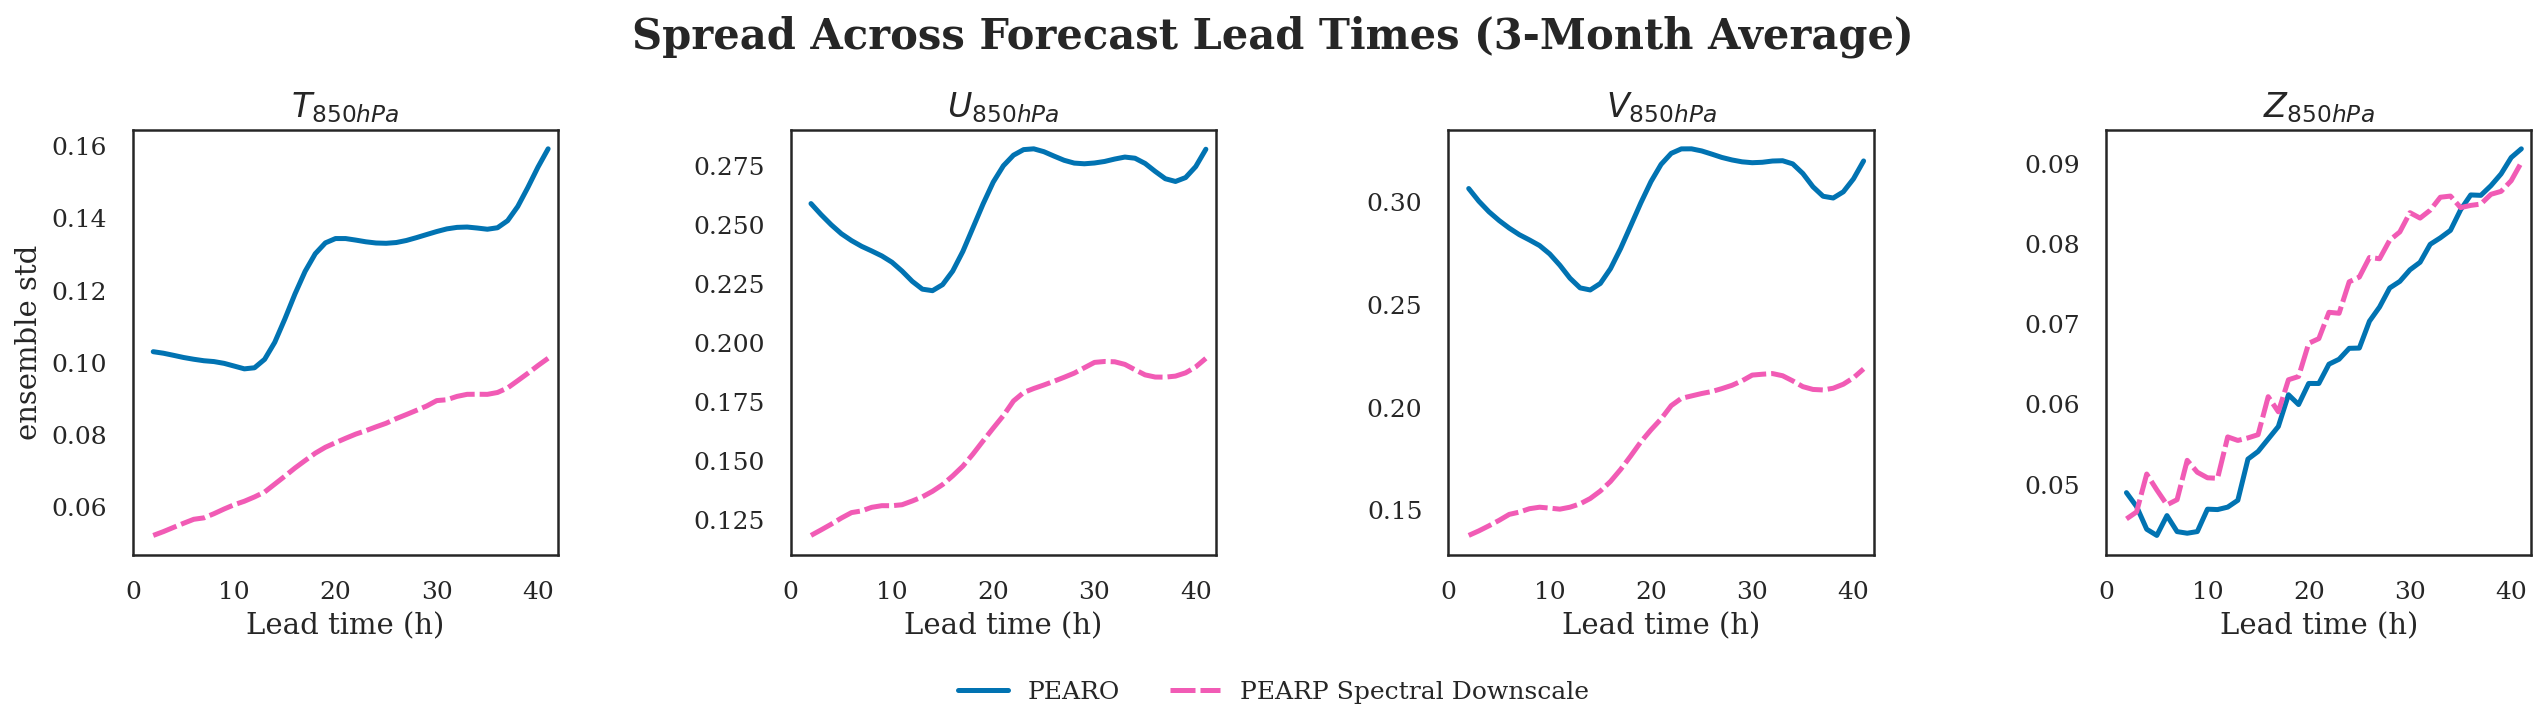

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetics
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables
# ---------------------------
vars = ["pearo_t_850hpa", "pearo_u_850hpa", "pearo_v_850hpa", "pearo_z_850hpa"]
var_name = [r"$T_{850hPa}$", r"$U_{850hPa}$", r"$V_{850hPa}$", r"$Z_{850hPa}$"]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Figure: 1 row × 4 columns
# ---------------------------
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

legend_handles = legend_labels = None

# ---------------------------
# Plot loop (ABSOLUTE ONLY)
# ---------------------------
for i, (var, name) in enumerate(zip(vars, var_name)):

    ax = axes[i]

    # ---------------------------
    # Paths (PEARO vs PEARP-SDS)
    # ---------------------------
    poesy_logdir = f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/Test_std_timestep_{var}_poesy_refacto_EURW1S40_refacto/"
    poesy = SummaryReader(poesy_logdir).scalars['value'][1:]

    ARPds_logdir = f"/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/Test_std_timestep_{var}_preds"
    mse_PEARP_spectralDS = SummaryReader(ARPds_logdir).scalars['value'][1:]

    # Lines to plot
    abs_lines = [
        ("PEARO", poesy, palette[0], linestyles[0]),
        ("PEARP Spectral Downscale", mse_PEARP_spectralDS, "#f15bb5", linestyles[4]),
    ]
    # Plot
    for label, data, color, ls in abs_lines:
        sns.lineplot(
            x=lead_times[:len(data)], y=data,
            ax=ax, label=label, color=color, linestyle=ls, linewidth=2.4
        )

    ax.set_title(name, weight="bold")
    ax.set_xlabel("Lead time (h)")
    ax.set_ylabel("ensemble std")
    ax.set_xlim(0, 42)

    # Square subplots
    ax.set_box_aspect(1)

    # Capture legend once
    if legend_handles is None:
        legend_handles, legend_labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# Remove y-axis labels from all but the first subplot
for i in range(1, 4):
    axes[i].set_ylabel("")

# ---------------------------
# Layout
# ---------------------------
fig.suptitle(
    "Spread Across Forecast Lead Times (3-Month Average)",
    fontsize=20, weight="bold", y=1.05
)

fig.legend(
    legend_handles, legend_labels,
    loc="lower center", ncol=2, frameon=False, fontsize=12
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.25, top=0.88)

plt.savefig("spread_ARPds.png",
            dpi=300, bbox_inches="tight")
plt.show()


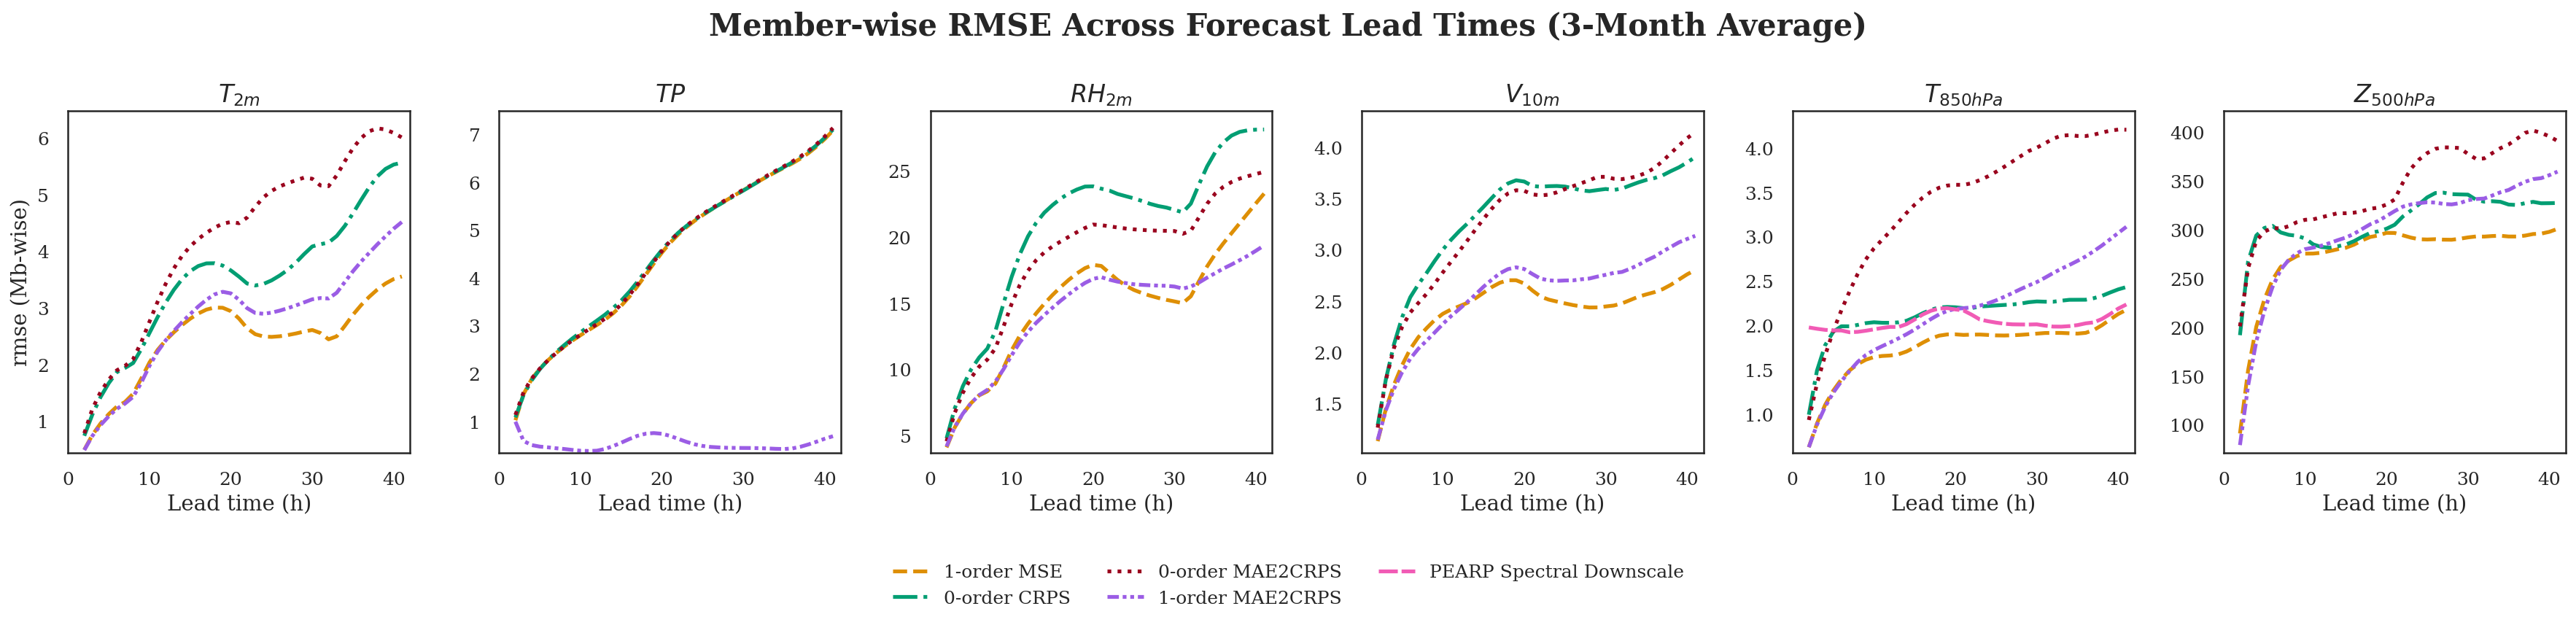

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetic settings
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables and names
# ---------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$",
    r"$TP$",
    r"$RH_{2m}$",
    r"$V_{10m}$",
    r"$T_{850hPa}$",
    r"$Z_{500hPa}$"
]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Create figure: 1 row × 6 cols (ABSOLUTE ONLY)
# ---------------------------
fig, axes = plt.subplots(1, 6, figsize=(24, 8))
handles, labels = None, None

# ---------------------------
# Plot loop (ABSOLUTE ONLY)
# ---------------------------
for i, var in enumerate(vars):
    ax = axes[i]

    # Load data
    with open("/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/test_poesy/Test_rmse_scores.json", 'r') as file:
        mse_1order = json.load(file)[var]
    with open("/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/test_poesy/Test_rmse_scores.json", 'r') as file:
        crps_0order = json.load(file)[var]
    with open("/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/test_poesy/Test_rmse_scores.json", 'r') as file:
        mae2crps_0order = json.load(file)[var]
    with open("/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/test_poesy_ciaran/Test_rmse_scores.json", 'r') as file:
        mae2crps_1order = json.load(file)[var]

    # Build absolute curve list
    lines_abs = [
        (mse_1order, "1-order MSE", palette[1], linestyles[1]),
        (crps_0order, "0-order CRPS", palette[2], linestyles[2]),
        (mae2crps_0order, "0-order MAE2CRPS", "#9a031e", linestyles[3]),
        (mae2crps_1order, "1-order MAE2CRPS", "#9b5de5", linestyles[5]),
    ]

    # Add PEARP Spectral Downscale only for 850hPa Temp
    if var == "pearo_t_850hpa":
        with open("/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/Test_rmse_scores.json", 'r') as file:
            mse_PEARP_spectralDS = json.load(file)[var][1:]  
        lines_abs.append((mse_PEARP_spectralDS, "PEARP Spectral Downscale", "#f15bb5", linestyles[4]))

    # Plot absolute
    for data, label, color, style in lines_abs:
        sns.lineplot(
            x=lead_times[:len(data)], y=data,
            label=label, color=color, linestyle=style,
            linewidth=2.5, ax=ax
        )

    ax.set_title(var_name[i], weight="bold")
    ax.set_xlabel("Lead time (h)")
    if i == 0:
        ax.set_ylabel("rmse (Mb-wise)")
    else:
        ax.set_ylabel("")

    ax.grid(False)
    ax.set_xlim(0, 42)

    ymin = min([np.min(d) for d, *_ in lines_abs]) * 0.9
    ymax = max([np.max(d) for d, *_ in lines_abs]) * 1.05
    ax.set_ylim(ymin, ymax)

    # Capture legend once
    if handles is None and var == "pearo_t_850hpa":
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

    # Square subplots
    ax.set_box_aspect(1)

# ---------------------------
# Global layout and legend
# ---------------------------
fig.suptitle(
    "Member-wise RMSE Across Forecast Lead Times (3-Month Average)",
    fontsize=20, weight="bold", y=0.9
)

fig.legend(handles, labels, loc="lower center", ncol=3,
           frameon=False, fontsize=12, bbox_to_anchor=(0.5, 0.2))

plt.tight_layout()
plt.subplots_adjust(bottom=0.30, top=0.88)

# ---------------------------
# Save figure
# ---------------------------
plt.savefig("rmse.png", bbox_inches="tight", dpi=300)
plt.show()


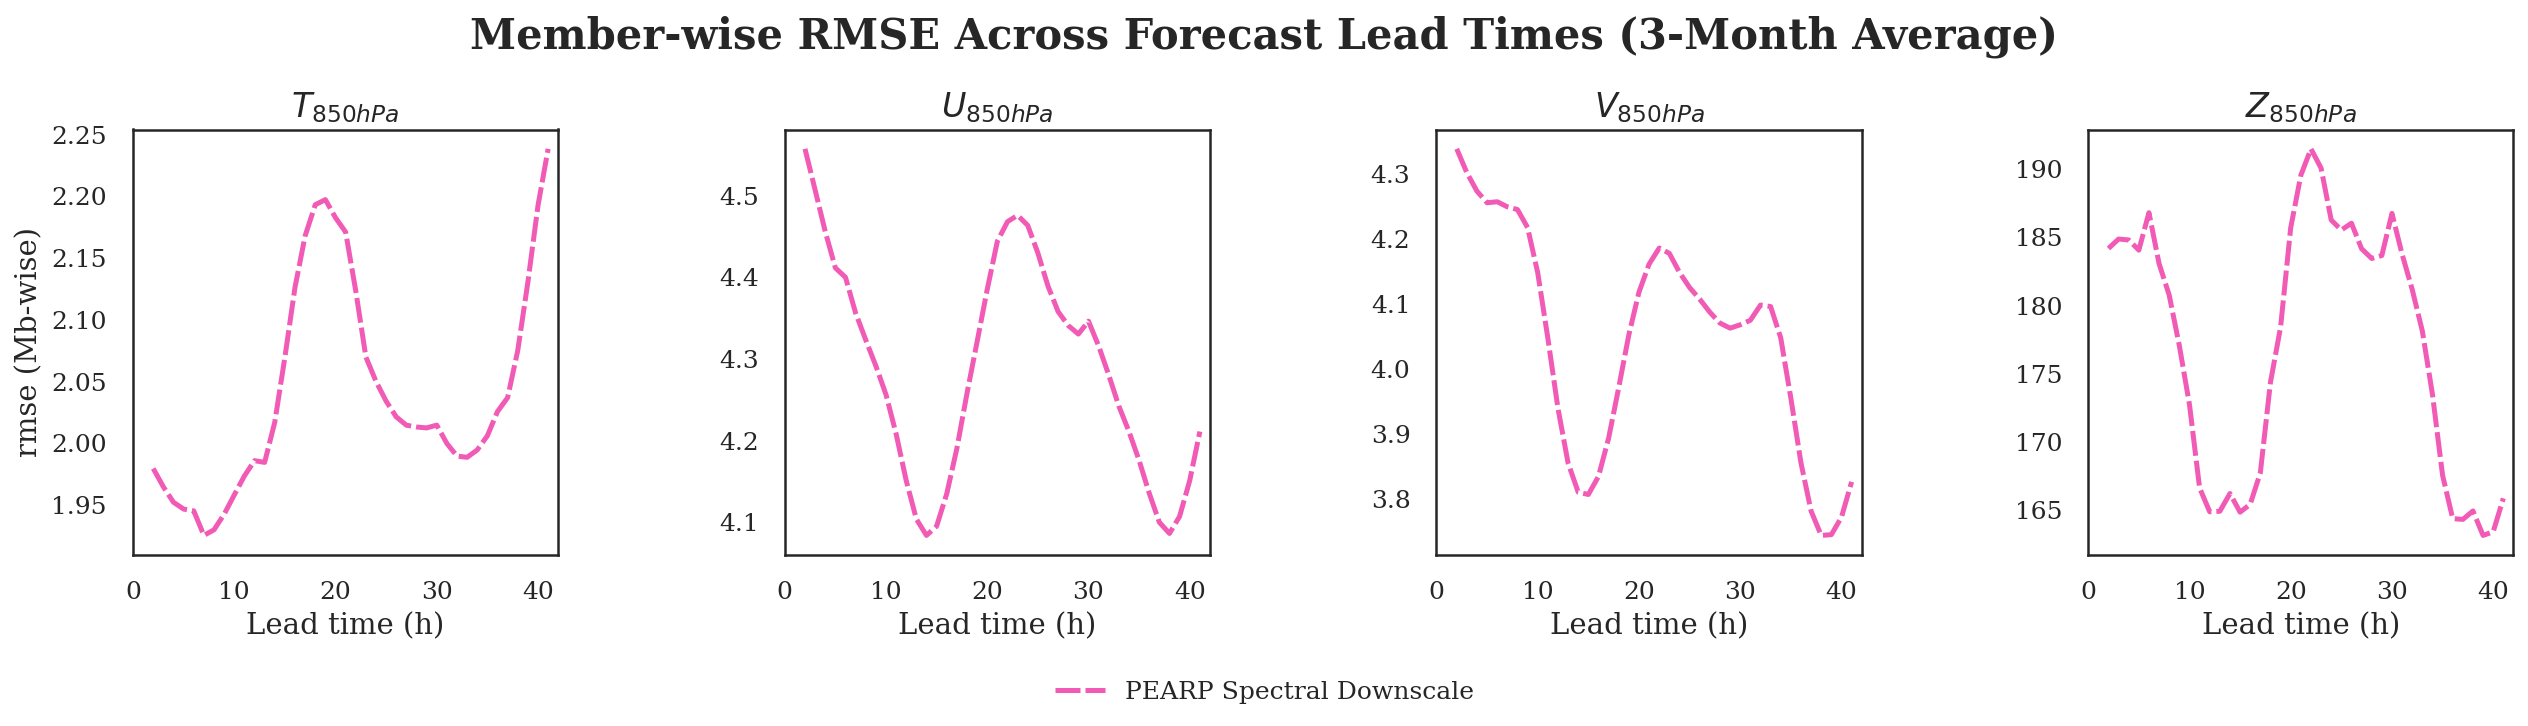

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------------------
# Global aesthetics
# ---------------------------
sns.set_theme(style="white", context="talk", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.2,
    "savefig.dpi": 300,
    "figure.dpi": 150,
})

# ---------------------------
# Variables
# ---------------------------
vars = ["pearo_t_850hpa", "pearo_u_850hpa", "pearo_v_850hpa", "pearo_z_850hpa"]
var_name = [r"$T_{850hPa}$", r"$U_{850hPa}$", r"$V_{850hPa}$", r"$Z_{850hPa}$"]

palette = sns.color_palette("colorblind")
linestyles = ['-', '--', '-.', ':', (0, (5, 1))]

lead_times = np.arange(2, 42)

# ---------------------------
# Figure: 1 row × 4 columns
# ---------------------------
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

legend_handles = legend_labels = None

# ---------------------------
# Plot loop (ABSOLUTE ONLY)
# ---------------------------
for i, (var, name) in enumerate(zip(vars, var_name)):

    ax = axes[i]

    # ---------------------------
    # Paths (PEARO vs PEARP-SDS)
    # ---------------------------
    with open("/scratch/audrena/py4cast_expe/titan_21var/mse_ARPdownscale_5em4_multiscale/test_poesy/Test_rmse_scores.json", 'r') as file:
        mse_PEARP_spectralDS = json.load(file)[var][1:]

    # Lines to plot
    abs_lines = [
        ("PEARP Spectral Downscale", mse_PEARP_spectralDS, "#f15bb5", linestyles[4]),
    ]
    # Plot
    for label, data, color, ls in abs_lines:
        sns.lineplot(
            x=lead_times[:len(data)], y=data,
            ax=ax, label=label, color=color, linestyle=ls, linewidth=2.4
        )

    ax.set_title(name, weight="bold")
    ax.set_xlabel("Lead time (h)")
    ax.set_ylabel("rmse (Mb-wise)")
    ax.set_xlim(0, 42)

    # Square subplots
    ax.set_box_aspect(1)

    # Capture legend once
    if legend_handles is None:
        legend_handles, legend_labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# Remove y-axis labels from all but the first subplot
for i in range(1, 4):
    axes[i].set_ylabel("")

# ---------------------------
# Layout
# ---------------------------
fig.suptitle(
    "Member-wise RMSE Across Forecast Lead Times (3-Month Average)",
    fontsize=20, weight="bold", y=1.05
)

fig.legend(
    legend_handles, legend_labels,
    loc="lower center", ncol=2, frameon=False, fontsize=12
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.25, top=0.88)

plt.savefig("rmse_ARPds.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
def plot_log_psd_perLeadtimes(
    k: np.ndarray, psd_mean: np.ndarray, psd_member: np.ndarray, psd_target: np.ndarray, title: str = ""
):
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.plot(k, psd_mean, label="Ensemble Mean")
    ax.plot(k, psd_member, label="Ensemble Member")
    ax.plot(k, psd_target, label="PEARO")
    ax.set_xlabel("k")
    ax.set_ylabel("psd_k")
    ax.legend()
    ax.set_title(title)
    plt.yscale("log")
    plt.close()
    return fig



In [ ]:
def plot_log_psd_perLeadtimes(
    k: np.ndarray, psd_pred: np.ndarray, psd_target: np.ndarray, title: str = ""
):
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.plot(k, psd_pred, label="Prediction")
    ax.plot(k, psd_target, label="ARO")
    ax.set_xlabel("k")
    ax.set_ylabel("psd_k")
    ax.legend()
    ax.set_title(title)
    plt.yscale("log")
    plt.close()
    return fig

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import imageio
import os

def plot_log_psd_perLeadtimes(
    k: np.ndarray, psd_mean: np.ndarray, psd_member: np.ndarray, psd_target: np.ndarray, title: str = ""
):
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.plot(k, psd_mean, label="Ensemble Mean")
    ax.plot(k, psd_member, label="Ensemble Member")
    ax.plot(k, psd_target, label="PEARO")
    ax.set_xlabel("k")
    ax.set_ylabel("psd_k")
    ax.legend()
    ax.set_title(title)
    plt.yscale("log")
    plt.close()
    return fig

# ----------------------------
# SETTINGS
# ----------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$",
    r"$TP$",
    r"$RH_{2m}$",
    r"$V_{10m}$",
    r"$T_{850hPa}$",
    r"$Z_{500hPa}$"
]
for i, var in enumerate(vars):
    
    base_path = "/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy"
    file_template = base_path + "/test_mean_psd_k_"+var+"_{}.npy"
    os.makedirs(base_path+"/PSD_GIFs", exist_ok=True)
    output_dir = base_path+"/PSD_GIFs"

    gif_filename = output_dir+"/"+var+"_psd_.gif"

    # ----------------------------
    # GENERATE FRAMES
    # ----------------------------
    frames = []
    for frame_num in range(1, 40 + 1):  # 1 → 40
        filepath = file_template.format(frame_num)
        data = np.load(filepath)  # shape (3, n)

        k, psd_mean, psd_pred, psd_target = data[0], data[1], data[2], data[3]

        title = f"{var_name[i]} RAPSD Comparison + {frame_num+1}h"
        fig = plot_log_psd_perLeadtimes(k, psd_mean, psd_pred, psd_target, title)

        frame_path = f"{output_dir}/frame_{frame_num:03d}.png"
        fig.savefig(frame_path, dpi=120)
        plt.close(fig)

        frames.append(frame_path)
        print(f"Saved {frame_path}")

    # ----------------------------
    # BUILD GIF
    # ----------------------------
    images = [imageio.imread(f) for f in frames]
    imageio.mimsave(gif_filename, images, fps=6)  # adjust speed as needed

    print(f"\nGIF saved as: {gif_filename}")


Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_001.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_002.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_003.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_004.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_005.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_006.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_007.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_008.png
Saved /scratch/audrena/py4cast_expe/titan_21var/

/tmp/ipykernel_1886967/2228396471.py:67: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(f) for f in frames]



GIF saved as: /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/pearo_t2m_2m_psd_.gif
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_001.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_002.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_003.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_004.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_005.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_006.png
Saved /scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/PSD_GIFs/frame_007.png
Saved /scratch/audrena/py4cast_

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import imageio
import os
import seaborn as sns

# ---------------------------------------------------
# Plotting function (multi-model)
# ---------------------------------------------------
def plot_log_psd_multiple_models(k, lines, title=""):
    fig, ax = plt.subplots(figsize=(15, 10))
    for psd, label, color, linestyle in lines:
        ax.plot(k, psd, label=label, color=color, linestyle="-", linewidth=2.3)
    ax.set_xlabel("k")
    ax.set_ylabel("psd_k")
    ax.set_title(title)
    ax.legend()
    ax.set_yscale("log")
    plt.close()
    return fig


# ---------------------------------------------------
# SETTINGS
# ---------------------------------------------------
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

var_name = [
    r"$T_{2m}$",
    r"$TP$",
    r"$RH_{2m}$",
    r"$V_{10m}$",
    r"$T_{850hPa}$",
    r"$Z_{500hPa}$"
]
palette = sns.color_palette("colorblind")
palette = [palette[0], "#9a031e", "#9b5de5", palette[1], palette[2]]
linestyles = ["-", "--", "-.", ":", "-"]

# Each model now has its *own template* with <var> AND <leadtime>
model_templates = {
    "PEARO": "/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/test_mean_psd_k_{}_{}.npy",
    
    # "0-order MAE2CRPS": "/scratch/audrena/py4cast_expe/titan_21var/mae2crps_0order_5em4_2M_2BS/june2023_test_poesy/test_mean_psd_k_{}_{}.npy",

    "1-order MAE2CRPS": "/scratch/audrena/py4cast_expe/titan_21var/mae2crps_1order_5em4_2M_2BS/june2023_test_poesy/test_mean_psd_k_{}_{}.npy",

    "1-order MSE": "/scratch/audrena/py4cast_expe/titan_21var/base_1order_5em4/june2023_test_poesy/test_mean_psd_k_{}_{}.npy",

    "0-order CRPS": "/scratch/audrena/py4cast_expe/titan_21var/crps_0order_5em4_2M_2BS/june2023_test_poesy/test_mean_psd_k_{}_{}.npy"
    
}


# ---------------------------------------------------
# MAIN LOOP
# ---------------------------------------------------
for i, var in enumerate(vars):

    # Output folder for GIFs
    output_dir = "/scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs"
    os.makedirs(output_dir, exist_ok=True)
    gif_filename = f"{output_dir}/{var}_psd_models.gif"

    frames = []

    # Loop over leadtimes
    for frame_num in range(1, 41):

        lines = []
        k = None  # will be filled by first model

        # Loop over all models
        for idx, (label, template) in enumerate(model_templates.items()):
            filepath = template.format(var, frame_num)
            data = np.load(filepath)   # === SAME loading structure as your original code ===

            k = data[0]
            if label == "PEARO":
                psd_mean = data[3]         # target PSD       
            else:
                psd_mean = data[1]         # ensemble-mean PSD

            lines.append((psd_mean, label, palette[idx], linestyles[idx]))

        # Create figure for this leadtime
        title = f"{var_name[i]} RAPSD Comparison +{frame_num+1}h (1-Month Avg)"
        fig = plot_log_psd_multiple_models(k, lines, title)

        frame_path = f"{output_dir}/frame_{var}_{frame_num:03d}.png"
        fig.savefig(frame_path, dpi=120)
        plt.close(fig)

        frames.append(frame_path)
        print(f"Saved {frame_path}")

    # ---------------------------------------------------
    # Build GIF
    # ---------------------------------------------------
    images = [imageio.imread(f) for f in frames]
    imageio.mimsave(gif_filename, images, fps=4)

    print(f"\nGIF saved as: {gif_filename}")


Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_001.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_002.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_003.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_004.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_005.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_006.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_007.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_008.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_009.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_010.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_011.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_t2m_2m_

/tmp/ipykernel_1975551/287761862.py:101: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images = [imageio.imread(f) for f in frames]



GIF saved as: /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/pearo_t2m_2m_psd_models.gif
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_001.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_002.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_003.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_004.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_005.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_006.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_007.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_008.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_009.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_010.png
Saved /scratch/audrena/py4cast_expe/titan_21var/PSD_GIFs/frame_pearo_tp_0m_0

In [7]:
# generate 8 random numbers from gaussain distribution
print(np.random.normal(loc=0.0, scale=1.0, size=8))

[-0.88694341 -0.11184378 -0.03137296 -0.99880897  0.13756441 -0.02275014
  0.54943919 -0.49050083]


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.interpolate import RegularGridInterpolator
import os

vars = ["t2m_2m", "tp_0m", "r2_2m",
        "v10_10m", "t_850hpa", "z_500hpa"]

var_name = [
    r"$T_{2m}$",
    r"$TP$",
    r"$RH_{2m}$",
    r"$V_{10m}$",
    r"$T_{850hPa}$",
    r"$Z_{500hPa}$"
]

model_path_name = [
    "mae2crps_1order_5em4_2M_2BS",
    "base_1order_5em4",
    "crps_0order_5em4_2M_2BS",
]

model_names = [
    "1-order MAE2CRPS",
    "1-order MSE",
    "0-order CRPS",
]

# -----------------------------------------------
# GLOBAL PARAMETERS
# -----------------------------------------------
frames = range(1, 40 + 1)


# ==========================================================
#         MAIN LOOP OVER VARIABLES
# ==========================================================
for var in vars:

    print(f"\nProcessing variable: {var}")

    # ------------------------------------------------------
    # FIRST PASS → load ALL models to compute global vmin/vmax
    # ------------------------------------------------------
    model_errors = []      # store psd_error arrays
    k_values = None
    lead_times = np.array(list(frames))+1

    for m_idx, model in enumerate(model_path_name):

        # Construct path template
        base_path = (
            f"/scratch/audrena/py4cast_expe/titan_21var/{model}/june2023_test_poesy"
        )
        file_template = base_path + f"/test_mean_psd_k_pearo_{var}" + "_{}.npy"

        psd_pred_list = []
        psd_target_list = []

        for frame_num in frames:
            data = np.load(file_template.format(frame_num))
            k, psd_pred, psd_target = data[0], data[1], data[3]

            if k_values is None:
                k_values = k

            psd_pred_list.append(psd_pred)
            psd_target_list.append(psd_target)

        psd_pred_arr = np.array(psd_pred_list).T
        psd_target_arr = np.array(psd_target_list).T

        error = (psd_pred_arr - psd_target_arr)**2
        model_errors.append(error)

    # ------------------------------------------------------
    # COMPUTE GLOBAL COLOR LIMITS ACROSS ALL MODELS
    # ------------------------------------------------------
    all_errors = np.concatenate([err.flatten() for err in model_errors])
    all_errors = all_errors[all_errors > 0]  # avoid log(0)

    global_vmin = np.nanmin(all_errors)
    global_vmax = np.nanmax(all_errors)

    print(f"Global color range for {var}: vmin={global_vmin:.2e}, vmax={global_vmax:.2e}")


    # ==========================================================
    # SECOND PASS → Produce plots using the global vmin / vmax
    # ==========================================================
    for m_idx, model in enumerate(model_path_name):

        title = (
            f"{model_names[m_idx]} {var_name[vars.index(var)]} "
            "RAPSD Error Across Lead Times (1-Month Avg)"
        )

        error = model_errors[m_idx]  # retrieved from earlier load

        # --------------------------------------------
        # CREATE FINE GRID (INTERPOLATION)
        # --------------------------------------------
        k_fine = np.linspace(k_values.min(), k_values.max(), 500)
        lead_fine = np.linspace(lead_times.min(), lead_times.max(), 500)

        interp_func = RegularGridInterpolator(
            (k_values, lead_times),
            error,
            method='linear',
            bounds_error=False,
            fill_value=None
        )

        K_fine, L_fine = np.meshgrid(k_fine, lead_fine, indexing='ij')
        points_fine = np.array([K_fine.ravel(), L_fine.ravel()]).T
        Z_fine = interp_func(points_fine).reshape(K_fine.shape)

        # --------------------------------------------
        # PLOT WITH CONSISTENT SCALING
        # --------------------------------------------
        plt.figure(figsize=(12, 6), dpi=300)

        plt.pcolormesh(
            lead_fine,
            k_fine,
            np.where(Z_fine > 0, Z_fine, global_vmin),  # avoid log(0)
            shading="auto",
            cmap="jet",
            norm=LogNorm(vmin=global_vmin, vmax=global_vmax)
        )

        plt.colorbar(label="RAPSD Error (log scale)")
        plt.xlabel("Lead Time (h)")
        plt.ylabel("k")
        plt.yscale("log")
        plt.title(title)
        plt.tight_layout()

        # save file
        fname = f"psd_error_{var}_{model_names[m_idx].replace(' ', '_')}.png"
        plt.savefig(fname, dpi=300, bbox_inches="tight")
        plt.close()

        print(f"Saved: {fname}")



Processing variable: t2m_2m
Global color range for t2m_2m: vmin=2.41e-24, vmax=2.10e-02
Saved: psd_error_t2m_2m_1-order_MAE2CRPS.png
Saved: psd_error_t2m_2m_1-order_MSE.png
Saved: psd_error_t2m_2m_0-order_CRPS.png

Processing variable: tp_0m
Global color range for tp_0m: vmin=7.05e-21, vmax=2.20e+00
Saved: psd_error_tp_0m_1-order_MAE2CRPS.png
Saved: psd_error_tp_0m_1-order_MSE.png
Saved: psd_error_tp_0m_0-order_CRPS.png

Processing variable: r2_2m
Global color range for r2_2m: vmin=4.01e-24, vmax=5.70e-01
Saved: psd_error_r2_2m_1-order_MAE2CRPS.png
Saved: psd_error_r2_2m_1-order_MSE.png
Saved: psd_error_r2_2m_0-order_CRPS.png

Processing variable: v10_10m
Global color range for v10_10m: vmin=9.39e-24, vmax=2.11e+00
Saved: psd_error_v10_10m_1-order_MAE2CRPS.png
Saved: psd_error_v10_10m_1-order_MSE.png
Saved: psd_error_v10_10m_0-order_CRPS.png

Processing variable: t_850hpa
Global color range for t_850hpa: vmin=1.96e-23, vmax=5.95e-03
Saved: psd_error_t_850hpa_1-order_MAE2CRPS.png
Saved